In [80]:
# Import: import os, glob, json
import os, glob, json

# Default env path if unset
os.environ.setdefault("AMAZON_ROOT", "/mnt/c/Users/legen/amazon_project")
# Default env path if unset
os.environ.setdefault("AMAZON_RAW", "/mnt/c/Users/legen/amazon_data")
# Default env path if unset
os.environ.setdefault("AMAZON_ROOT_256", "/mnt/c/Users/legen/amazon_project_tif_256")

# Read path/config from environment
root = os.environ.get("AMAZON_ROOT", "/mnt/c/Users/legen/amazon_project")
# Read path/config from environment
raw = os.environ.get("AMAZON_RAW", "/mnt/c/Users/legen/amazon_data")
# Ensure output directory exists
os.makedirs(root, exist_ok=True)
# Ensure output directory exists
os.makedirs(raw, exist_ok=True)
# Ensure output directory exists
os.makedirs(f"{root}/results", exist_ok=True)
# Ensure output directory exists
os.makedirs(f"{root}/figs", exist_ok=True)
# Ensure output directory exists
os.makedirs(f"{root}/cache", exist_ok=True)
# Ensure output directory exists
os.makedirs(f"{root}/runs", exist_ok=True)

In [81]:
# Import: import sys
import sys
# Import: import importlib.util
import importlib.util
# Import: import subprocess
import subprocess

# Set `_pipPkgs` = [
_pipPkgs = [
    # Continuation of the multi-line expression
    ("torch", "torch"),
    # Continuation of the multi-line expression
    ("torchvision", "torchvision"),
    # Continuation of the multi-line expression
    ("cv2", "opencv-python-headless"),
    # Continuation of the multi-line expression
    ("pandas", "pandas"),
    # Continuation of the multi-line expression
    ("sklearn", "scikit-learn"),
    # Continuation of the multi-line expression
    ("matplotlib", "matplotlib"),
    # Continuation of the multi-line expression
    ("tifffile", "tifffile"),
# Continuation of the multi-line expression
]
# Set `missing` = [pip for mod, pip in _pipPkgs if importlib.util.find_spec(mod) is None…
missing = [pip for mod, pip in _pipPkgs if importlib.util.find_spec(mod) is None]
# Conditional branch
if missing:
    # Print status / metrics to the notebook
    print("Installing into active kernel:", " ".join(sorted(set(missing))))
    # Run this pipeline step
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *sorted(set(missing))])

In [82]:
# Find matching files under the data root
jpgsQuick = glob.glob(f"{raw}/**/train-jpg/*.jpg", recursive=True)
# Conditional branch
if not jpgsQuick:
    # Find matching files under the data root
    jpgsQuick = glob.glob(f"{raw}/**/*.jpg", recursive=True)
# Conditional branch
if len(jpgsQuick) > 1000:
    # Print status / metrics to the notebook
    print(f"Local JPG dataset detected ({len(jpgsQuick)} files) — skipping any remote/Kaggle download.")
# Fallback when earlier conditions were false
else:
    # Print status / metrics to the notebook
    print("No large local JPG set found. Copy Kaggle train-jpg + train_v2.csv into AMAZON_RAW, then re-run.")

Local JPG dataset detected (40479 files) — skipping any remote/Kaggle download.


In [83]:
# Find matching files under the data root
tifs = glob.glob(f"{raw}/**/*.tif", recursive=True)
# Find matching files under the data root
jpgs = glob.glob(f"{raw}/**/train-jpg/*.jpg", recursive=True)
# Conditional branch
if not jpgs:
    # Find matching files under the data root
    jpgs = glob.glob(f"{raw}/**/*.jpg", recursive=True)

# Set `csvCandidates` = [
csvCandidates = [
    # Continuation of the multi-line expression
    p for p in (
        # Keyword/field `glob.glob(f"{raw}/**/train_classes.csv", recursive`
        glob.glob(f"{raw}/**/train_classes.csv", recursive=True)
        # Keyword/field `+ glob.glob(f"{raw}/**/train_v2.csv", recursive`
        + glob.glob(f"{raw}/**/train_v2.csv", recursive=True)
        # Keyword/field `+ glob.glob(f"{raw}/**/labels_train_v2.csv", recursive`
        + glob.glob(f"{raw}/**/labels_train_v2.csv", recursive=True)
    # Continuation of the multi-line expression
    )
    # Continuation of the multi-line expression
    if os.path.isfile(p)
# Continuation of the multi-line expression
]

# Conditional branch
if len(tifs) > 1000 and csvCandidates:
    # Set `paths` = {
    paths = {
        # Dict entry for key `"tif_dir"`
        "tif_dir": os.path.dirname(tifs[0]),
        # Dict entry for key `"csv"`
        "csv": csvCandidates[0],
        # String entry in this collection
        "image_ext": ".tif",
    # Continuation of the multi-line expression
    }
    # Print status / metrics to the notebook
    print("TIF files found:", len(tifs))
# Alternate conditional branch
elif len(jpgs) > 1000 and csvCandidates:
    # Set `jpgDir` = os.path.dirname(jpgs[0])
    jpgDir = os.path.dirname(jpgs[0])
    # Set `csvNear` = os.path.join(os.path.dirname(jpgDir), "train_classes.csv")
    csvNear = os.path.join(os.path.dirname(jpgDir), "train_classes.csv")
    # Check that this path exists
    csvPath = csvNear if os.path.exists(csvNear) else csvCandidates[0]
    # Set `paths` = {
    paths = {
        # Dict entry for key `"tif_dir"`
        "tif_dir": jpgDir,
        # Dict entry for key `"csv"`
        "csv": csvPath,
        # String entry in this collection
        "image_ext": ".jpg",
    # Continuation of the multi-line expression
    }
    # Print status / metrics to the notebook
    print("JPG files found:", len(jpgs), "(TIF torrent unavailable — RGB-only pipeline)")
# Fallback when earlier conditions were false
else:
    # Stop with an error when setup/data is invalid
    raise SystemExit(
        # String entry in this collection
        f"Setup incomplete: tifs={len(tifs)} jpgs={len(jpgs)} csvs={len(csvCandidates)}. "
        # String entry in this collection
        f"Place data under AMAZON_RAW ({raw}) or set AMAZON_RAW / AMAZON_ROOT and re-run from the top.")

# Enter a context manager (auto-closes resources)
with open(f"{root}/paths.json", "w") as f:
    # Write JSON metadata to disk
    json.dump(paths, f, indent=2)

TIF files found: 40479


In [84]:
# Import: import numpy as np
import numpy as np
# Import: import pandas as pd
import pandas as pd
# Import: import cv2
import cv2
# Import: import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
# Jupyter magic used by this environment
%matplotlib inline
# Import: from concurrent.futures import ThreadPoolExecutor
from concurrent.futures import ThreadPoolExecutor
# Import: from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
# Import: import tifffile
import tifffile

# Read path/config from environment
root = os.environ.get("AMAZON_ROOT", "/mnt/c/Users/legen/amazon_project")

# Set `tileSize` = 128
tileSize = 128
# Set `subset` = None
subset = None
# Set `seed` = 42
seed = 42
# Set `figDir, cache` = f"{root}/figs", f"{root}/cache"
figDir, cache = f"{root}/figs", f"{root}/cache"
# Ensure output directory exists
os.makedirs(figDir, exist_ok=True)
# Ensure output directory exists
os.makedirs(cache, exist_ok=True)
# Load JSON metadata from disk
paths = json.load(open(f"{root}/paths.json"))
# Set `imageExt` = paths.get("image_ext", ".tif").lower()
imageExt = paths.get("image_ext", ".tif").lower()
# Set `jpgMode` = imageExt in (".jpg", ".jpeg")
jpgMode = imageExt in (".jpg", ".jpeg")

In [85]:
# Load the Planet label CSV
df = pd.read_csv(paths["csv"])
# Set `tagLists` = df["tags"].str.split()
tagLists = df["tags"].str.split()
# Set `labels` = sorted({t for tl in tagLists for t in tl})
labels = sorted({t for tl in tagLists for t in tl})
# Assert an invariant (fail fast if violated)
assert len(labels) == 17, labels
# Set `y` = np.zeros((len(df), 17), dtype=np.uint8)
y = np.zeros((len(df), 17), dtype=np.uint8)
# Iterate over this sequence
for i, tl in enumerate(tagLists):
    # Iterate over this sequence
    for t in tl:
        # Set `y[i, labels.index(t)]` = 1
        y[i, labels.index(t)] = 1
# Set `names` = df["image_name"].tolist()
names = df["image_name"].tolist()
# Print status / metrics to the notebook
print("Tiles:", len(df), "| labels:", labels)

Tiles: 40479 | labels: ['agriculture', 'artisinal_mine', 'bare_ground', 'blooming', 'blow_down', 'clear', 'cloudy', 'conventional_mine', 'cultivation', 'habitation', 'haze', 'partly_cloudy', 'primary', 'road', 'selective_logging', 'slash_burn', 'water']


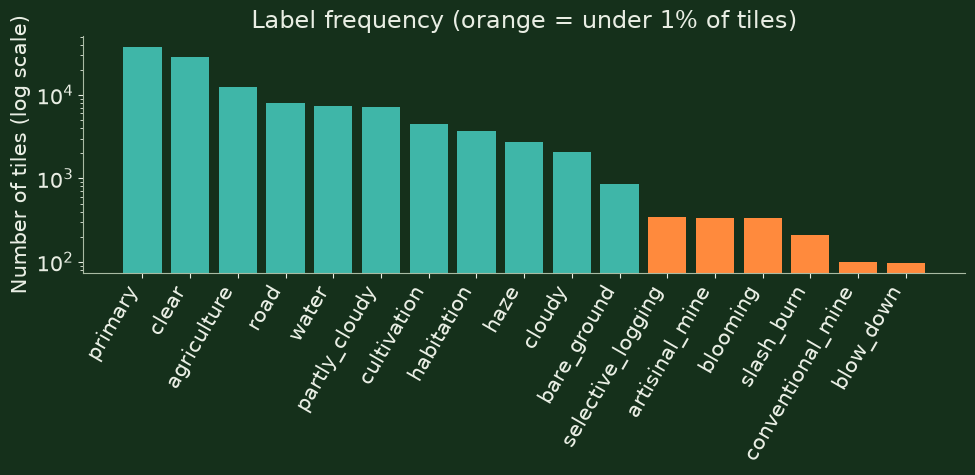

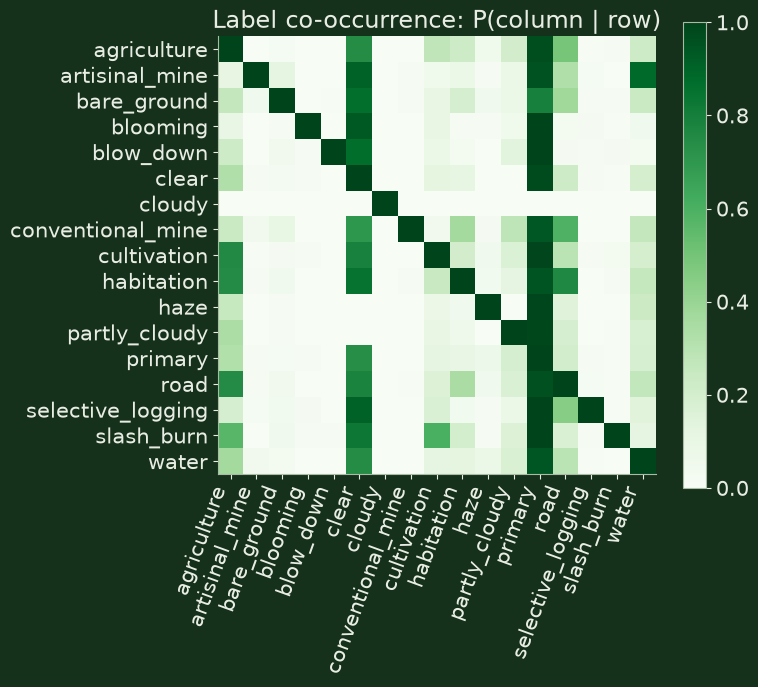

In [86]:
# Set `counts` = pd.Series(y.sum(0), index=labels).sort_values(ascending=False)
counts = pd.Series(y.sum(0), index=labels).sort_values(ascending=False)
# Set `table` = pd.DataFrame({"tiles": counts, "percent": (100 * counts / len(df)).rou…
table = pd.DataFrame({"tiles": counts, "percent": (100 * counts / len(df)).round(2)})
# Export a metrics/label table as CSV
table.to_csv(f"{figDir}/label_counts.csv")
# Create matplotlib figure/axes
fig, ax = plt.subplots(figsize=(10, 5))
# Set `cols` = ["#FF8A3D" if p < 1 else "#3FB6A8" for p in table["percent"]]
cols = ["#FF8A3D" if p < 1 else "#3FB6A8" for p in table["percent"]]
# Draw or configure plot elements
ax.bar(table.index, table["tiles"], color=cols)
# Draw or configure plot elements
ax.set_yscale("log")
# Draw or configure plot elements
ax.set_ylabel("Number of tiles (log scale)")
# Draw or configure plot elements
ax.set_title("Label frequency (orange = under 1% of tiles)")
# Set `plt.xticks(rotation` = 60, ha="right")
plt.xticks(rotation=60, ha="right")
# Run this pipeline step
plt.tight_layout()
# Save figure PNG for the report/deck
plt.savefig(f"{figDir}/fig_label_counts.png", dpi=200)
# Render the figure in the notebook UI
plt.show()
# Close figure to release memory
plt.close()
# Set `co` = y.T.astype(float) @ y.astype(float)
co = y.T.astype(float) @ y.astype(float)
# Set `co` = co / np.diag(co)[:, None]
co = co / np.diag(co)[:, None]
# Create matplotlib figure/axes
fig, ax = plt.subplots(figsize=(8, 7))
# Set `im` = ax.imshow(co, cmap="Greens", vmin=0, vmax=1)
im = ax.imshow(co, cmap="Greens", vmin=0, vmax=1)
# Draw or configure plot elements
ax.set_xticks(range(17))
# Draw or configure plot elements
ax.set_xticklabels(labels, rotation=70, ha="right")
# Draw or configure plot elements
ax.set_yticks(range(17))
# Draw or configure plot elements
ax.set_yticklabels(labels)
# Draw or configure plot elements
ax.set_title("Label co-occurrence: P(column | row)")
# Run this pipeline step
plt.colorbar(im)
# Run this pipeline step
plt.tight_layout()
# Save figure PNG for the report/deck
plt.savefig(f"{figDir}/fig_label_cooccurrence.png", dpi=200)
# Render the figure in the notebook UI
plt.show()
# Close figure to release memory
plt.close()

In [87]:
# Fix RNG seed for reproducibility
rng = np.random.RandomState(seed)
# Set `keep` = np.arange(len(df))
keep = np.arange(len(df))
# Conditional branch
if subset and subset < len(df):
    # Set `rareIdx` = [labels.index(l) for l in labels if counts[l] < 1000]
    rareIdx = [labels.index(l) for l in labels if counts[l] < 1000]
    # Set `isRare` = y[:, rareIdx].any(1)
    isRare = y[:, rareIdx].any(1)
    # Set `others` = np.where(~isRare)[0]
    others = np.where(~isRare)[0]
    # Set `need` = max(subset - int(isRare.sum()), 0)
    need = max(subset - int(isRare.sum()), 0)
    # Set `keep` = np.sort(np.concatenate([np.where(isRare)[0], rng.choice(others, need, …
    keep = np.sort(np.concatenate([np.where(isRare)[0], rng.choice(others, need, False)]))
# Set `y` = y[keep]
y = y[keep]
# Set `names` = [names[i] for i in keep]
names = [names[i] for i in keep]
# Set `nTiles` = len(names)
nTiles = len(names)
# Print status / metrics to the notebook
print("Tiles used:", nTiles)

# Define function `image_path`
def image_path(n):
    # Return result to caller
    return os.path.join(paths["tif_dir"], n + imageExt)

# Define function `read_image`
def read_image(n):
    # Run this pipeline step
    """Return float32 HxWxC. TIF: 4 bands; JPG: 3-band RGB (OpenCV BGR->RGB)."""
    # Set `path` = image_path(n)
    path = image_path(n)
    # Conditional branch
    if jpgMode:
        # OpenCV image operation
        bgr = cv2.imread(path, cv2.IMREAD_COLOR)
        # Conditional branch
        if bgr is None:
            # Stop with an error when setup/data is invalid
            raise FileNotFoundError(path)
        # Return result to caller
        return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32)
    # Use tifffile for GeoTIFF I/O
    a = tifffile.imread(path).astype(np.float32)
    # Conditional branch
    if a.ndim == 3 and a.shape[0] == 4 and a.shape[-1] != 4:
        # Set `a` = np.transpose(a, (1, 2, 0))
        a = np.transpose(a, (1, 2, 0))
    # Return result to caller
    return a

Tiles used: 40479


Chosen band order: BGRN -> forest NDVI should be highest, water lowest


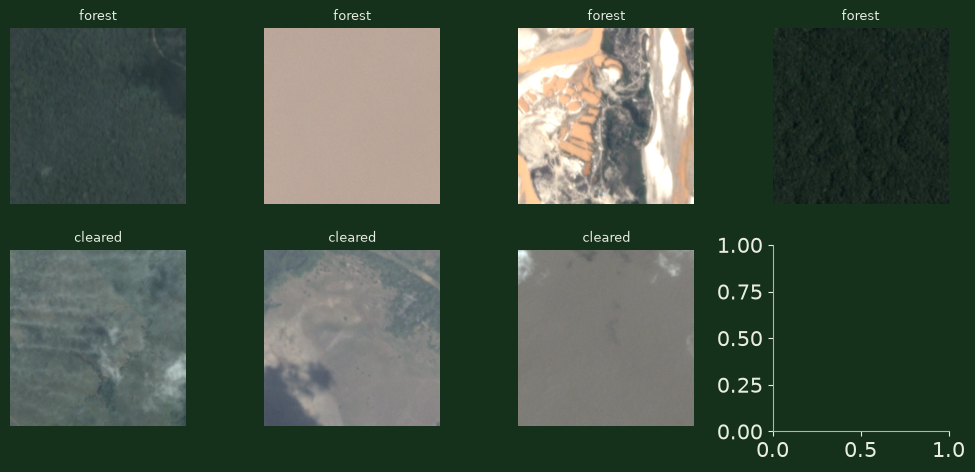

In [88]:
# Set `samp` = rng.choice(nTiles, min(600, nTiles), replace=False)
samp = rng.choice(nTiles, min(600, nTiles), replace=False)
# Set `raw` = np.stack([read_image(names[i]) for i in samp])
raw = np.stack([read_image(names[i]) for i in samp])
# Set `ys` = y[samp]
ys = y[samp]
# Set `prim` = ys[:, labels.index("primary")] == 1
prim = ys[:, labels.index("primary")] == 1
# Set `open_` = (ys[:, labels.index("agriculture")] == 1) | (ys[:, labels.index("bare_…
open_ = (ys[:, labels.index("agriculture")] == 1) | (ys[:, labels.index("bare_ground")] == 1)
# Set `prim, open_` = prim & ~open_, open_ & ~prim
prim, open_ = prim & ~open_, open_ & ~prim

# Conditional branch
if jpgMode:
    # Set `bandOrder` = "RGB_JPG"
    bandOrder = "RGB_JPG"
    # Set `bandMap` = dict(r=0, g=1, b=2, nir=None)
    bandMap = dict(r=0, g=1, b=2, nir=None)
    # Set `nBands` = 3
    nBands = 3
    # Set `tileMean` = raw.reshape(len(samp), -1, nBands).mean(1)
    tileMean = raw.reshape(len(samp), -1, nBands).mean(1)
    # Write JSON metadata to disk
    json.dump({"order": bandOrder, "r": 0, "g": 1, "b": 2, "nir": None, "jpg_mode": True},
              # Continuation of the multi-line expression
              open(f"{cache}/order.json", "w"))
    # Robust band min/max via percentiles
    lo = np.percentile(raw.reshape(-1, nBands), 1, axis=0)
    # Robust band min/max via percentiles
    hi = np.percentile(raw.reshape(-1, nBands), 99, axis=0)
    # Set `lo5` = np.concatenate([lo, [0.0, 0.0]])
    lo5 = np.concatenate([lo, [0.0, 0.0]])
    # Set `hi5` = np.concatenate([hi, [1.0, 1.0]])
    hi5 = np.concatenate([hi, [1.0, 1.0]])
    # Write JSON metadata to disk
    json.dump({"lo": lo5.tolist(), "hi": hi5.tolist(), "jpg_mode": True},
              # Continuation of the multi-line expression
              open(f"{cache}/band_stats.json", "w"))
    # Set `lo, hi` = lo5, hi5
    lo, hi = lo5, hi5
# Fallback when earlier conditions were false
else:
    # Set `nBands` = 4
    nBands = 4
    # Set `tileMean` = raw.reshape(len(samp), -1, 4).mean(1)
    tileMean = raw.reshape(len(samp), -1, 4).mean(1)
    # Set `ratio` = tileMean[open_].mean(0) / tileMean[prim].mean(0)
    ratio = tileMean[open_].mean(0) / tileMean[prim].mean(0)
    # Set `orders` = {"BGRN": dict(b=0, g=1, r=2, nir=3), "RGBN": dict(b=2, g=1, r=0, nir=3…
    orders = {"BGRN": dict(b=0, g=1, r=2, nir=3), "RGBN": dict(b=2, g=1, r=0, nir=3)}
    # Set `bandOrder` = "BGRN"
    bandOrder = "BGRN"
    # Conditional branch
    if ratio[0] > 1.15 * ratio[2]:
        # Set `bandOrder` = "RGBN"
        bandOrder = "RGBN"
    # Set `bandMap` = orders[bandOrder]
    bandMap = orders[bandOrder]
    # Print status / metrics to the notebook
    print("Chosen band order:", bandOrder, "-> forest NDVI should be highest, water lowest")
    # Write JSON metadata to disk
    json.dump({"order": bandOrder, **bandMap, "jpg_mode": False}, open(f"{cache}/order.json", "w"))
    # Robust band min/max via percentiles
    lo = np.percentile(raw.reshape(-1, 4), 1, axis=0)
    # Robust band min/max via percentiles
    hi = np.percentile(raw.reshape(-1, 4), 99, axis=0)
    # Write JSON metadata to disk
    json.dump({"lo": lo.tolist(), "hi": hi.tolist(), "jpg_mode": False},
              # Continuation of the multi-line expression
              open(f"{cache}/band_stats.json", "w"))

# Create matplotlib figure/axes
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
# Iterate over this sequence
for r, grp in enumerate([np.where(prim)[0][:4], np.where(open_)[0][:4]]):
    # Iterate over this sequence
    for c, k in enumerate(grp):
        # Conditional branch
        if jpgMode:
            # Clamp values into a valid range
            img = np.stack([np.clip((raw[k][..., bandMap[x]] - lo[bandMap[x]]) / (hi[bandMap[x]] - lo[bandMap[x]] + 1e-6),
                                    # Continuation of the multi-line expression
                                    0, 1) for x in ("r", "g", "b")], -1) ** 0.8
        # Fallback when earlier conditions were false
        else:
            # Clamp values into a valid range
            img = np.stack([np.clip((raw[k][..., bandMap[x]] - lo[bandMap[x]]) / (hi[bandMap[x]] - lo[bandMap[x]] + 1e-6),
                                    # Continuation of the multi-line expression
                                    0, 1) for x in ("r", "g", "b")], -1) ** 0.8
        # Draw or configure plot elements
        axes[r][c].imshow(img)
        # Draw or configure plot elements
        axes[r][c].axis("off")
        # Draw or configure plot elements
        axes[r][c].set_title(["forest", "cleared"][r], fontsize=9)
# Run this pipeline step
plt.tight_layout()
# Save figure PNG for the report/deck
plt.savefig(f"{figDir}/fig_band_check.png", dpi=150)
# Render the figure in the notebook UI
plt.show()
# Close figure to release memory
plt.close()
# Delete large temporary object to free RAM
del raw

In [89]:
# Memory-map large array without full RAM load
xmm = np.lib.format.open_memmap(f"{cache}/X.npy", mode="w+", dtype=np.float16,
                                # Keyword/field `shape`
                                shape=(nTiles, 5, tileSize, tileSize))

# Define function `process`
def process(i):
    # Set `a` = read_image(names[i])
    a = read_image(names[i])
    # Set `chans` = []
    chans = []
    # Conditional branch
    if jpgMode:
        # Iterate over this sequence
        for src in (0, 1, 2):
            # Clamp values into a valid range
            chans.append(np.clip((a[..., src] - lo[src]) / (hi[src] - lo[src] + 1e-6), 0, 1))
        # Set `chans.append(np.zeros(a.shape[:2], dtype` = np.float32))
        chans.append(np.zeros(a.shape[:2], dtype=np.float32))
        # Set `chans.append(np.zeros(a.shape[:2], dtype` = np.float32))
        chans.append(np.zeros(a.shape[:2], dtype=np.float32))
    # Fallback when earlier conditions were false
    else:
        # Set `red, nir` = a[..., bandMap["r"]], a[..., bandMap["nir"]]
        red, nir = a[..., bandMap["r"]], a[..., bandMap["nir"]]
        # Set `ndvi` = (nir - red) / (nir + red + 1e-6)
        ndvi = (nir - red) / (nir + red + 1e-6)
        # Iterate over this sequence
        for src in (bandMap["r"], bandMap["g"], bandMap["b"], bandMap["nir"]):
            # Clamp values into a valid range
            chans.append(np.clip((a[..., src] - lo[src]) / (hi[src] - lo[src] + 1e-6), 0, 1))
        # Clamp values into a valid range
        chans.append((np.clip(ndvi, -1, 1) + 1) / 2)
    # Set `arr` = np.stack(chans, -1).astype(np.float32)
    arr = np.stack(chans, -1).astype(np.float32)
    # OpenCV image operation
    arr = cv2.resize(arr, (tileSize, tileSize), interpolation=cv2.INTER_AREA)
    # Set `xmm[i]` = np.transpose(arr, (2, 0, 1)).astype(np.float16)
    xmm[i] = np.transpose(arr, (2, 0, 1)).astype(np.float16)

# Enter a context manager (auto-closes resources)
with ThreadPoolExecutor(8) as ex:
    # Iterate over this sequence
    for k, _ in enumerate(ex.map(process, range(nTiles))):
        # Conditional branch
        if k % 2000 == 0:
            # Print status / metrics to the notebook
            print(f"cached {k}/{nTiles}")
# Run this pipeline step
xmm.flush()
# Persist NumPy array(s) to the cache
np.save(f"{cache}/Y.npy", y)
# Write JSON metadata to disk
json.dump(labels, open(f"{cache}/labels.json", "w"))
# Write JSON metadata to disk
json.dump(names, open(f"{cache}/names.json", "w"))
# Write JSON metadata to disk
json.dump({"jpg_mode": jpgMode, "image_ext": imageExt, "channels": ["R", "G", "B", "NIR", "NDVI"],
           # Dict entry for key `"note"`
           "note": "NIR/NDVI are zero placeholders when jpg_mode is true"},
          # Continuation of the multi-line expression
          open(f"{cache}/cache_meta.json", "w"))

cached 0/40479
cached 2000/40479
cached 4000/40479
cached 6000/40479
cached 8000/40479
cached 10000/40479
cached 12000/40479
cached 14000/40479
cached 16000/40479
cached 18000/40479
cached 20000/40479
cached 22000/40479
cached 24000/40479
cached 26000/40479
cached 28000/40479
cached 30000/40479
cached 32000/40479
cached 34000/40479
cached 36000/40479
cached 38000/40479
cached 40000/40479


In [90]:
# Set `freq` = y.sum(0)
freq = y.sum(0)
# Set `strata` = np.array([min(np.where(y == 1)[0], key=lambda j: freq[j]) for y in y])
strata = np.array([min(np.where(y == 1)[0], key=lambda j: freq[j]) for y in y])
# Set `idx` = np.arange(nTiles)
idx = np.arange(nTiles)
# Stratified train/val/test index split
tr, tmp = train_test_split(idx, test_size=0.30, stratify=strata, random_state=seed)
# Stratified train/val/test index split
va, te = train_test_split(tmp, test_size=0.50, stratify=strata[tmp], random_state=seed)
# Persist NumPy array(s) to the cache
np.savez(f"{cache}/splits.npz", train=np.sort(tr), val=np.sort(va), test=np.sort(te))
# Print status / metrics to the notebook
print("train/val/test:", len(tr), len(va), len(te))
# Print status / metrics to the notebook
print("rare-label counts in test:",
      # Dict entry for key `{l`
      {l: int(y[te][:, labels.index(l)].sum()) for l in labels if freq[labels.index(l)] < 400})

train/val/test: 28335 6072 6072
rare-label counts in test: {'artisinal_mine': 51, 'blooming': 51, 'blow_down': 15, 'conventional_mine': 15, 'selective_logging': 51, 'slash_burn': 31}


In [91]:
# Load NumPy array (often memory-mapped)
xr = np.load(f"{cache}/X.npy", mmap_mode="r")
# Set `pick` = np.sort(rng.choice(tr, min(3000, len(tr)), replace=False))
pick = np.sort(rng.choice(tr, min(3000, len(tr)), replace=False))
# Set `sub` = np.asarray(xr[pick]).astype(np.float32)
sub = np.asarray(xr[pick]).astype(np.float32)
# Set `mean, std` = sub.mean((0, 2, 3)), sub.std((0, 2, 3)) + 1e-6
mean, std = sub.mean((0, 2, 3)), sub.std((0, 2, 3)) + 1e-6
# Persist NumPy array(s) to the cache
np.savez(f"{cache}/stats.npz", mean=mean, std=std)

In [92]:
# Import: import matplotlib.cm as cm
import matplotlib.cm as cm

# Read path/config from environment
root = os.environ.get("AMAZON_ROOT", "/mnt/c/Users/legen/amazon_project")

# Set `cache, out` = f"{root}/cache", f"{root}/figs/real"
cache, out = f"{root}/cache", f"{root}/figs/real"
# Ensure output directory exists
os.makedirs(out, exist_ok=True)
# Load JSON metadata from disk
paths = json.load(open(f"{root}/paths.json"))
# Set `imageExt` = paths.get("image_ext", ".tif").lower()
imageExt = paths.get("image_ext", ".tif").lower()
# Load JSON metadata from disk
jpgMode = imageExt in (".jpg", ".jpeg") or json.load(open(f"{cache}/order.json")).get("jpg_mode", False)
# Load JSON metadata from disk
labels = json.load(open(f"{cache}/labels.json"))
# Load JSON metadata from disk
names = json.load(open(f"{cache}/names.json"))
# Load NumPy array (often memory-mapped)
y = np.load(f"{cache}/Y.npy")
# Load JSON metadata from disk
bandMap = json.load(open(f"{cache}/order.json"))
# Load JSON metadata from disk
bandStats = json.load(open(f"{cache}/band_stats.json"))
# Set `lo, hi` = np.array(bandStats["lo"]), np.array(bandStats["hi"])
lo, hi = np.array(bandStats["lo"]), np.array(bandStats["hi"])
# Fix RNG seed for reproducibility
rng = np.random.RandomState(7)

# Define function `read_image`
def read_image(n):
    # Set `path` = os.path.join(paths["tif_dir"], n + imageExt)
    path = os.path.join(paths["tif_dir"], n + imageExt)
    # Conditional branch
    if jpgMode:
        # OpenCV image operation
        bgr = cv2.imread(path, cv2.IMREAD_COLOR)
        # Conditional branch
        if bgr is None:
            # Stop with an error when setup/data is invalid
            raise FileNotFoundError(path)
        # Return result to caller
        return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32)
    # Use tifffile for GeoTIFF I/O
    a = tifffile.imread(path).astype(np.float32)
    # Conditional branch
    if a.ndim == 3 and a.shape[0] == 4 and a.shape[-1] != 4:
        # Set `a` = np.transpose(a, (1, 2, 0))
        a = np.transpose(a, (1, 2, 0))
    # Return result to caller
    return a

# Define function `stretch`
def stretch(a, band):
    # Return result to caller
    return np.clip((a[..., band] - lo[band]) / (hi[band] - lo[band] + 1e-6), 0, 1)

# Define function `rgb`
def rgb(a, gamma=0.8):
    # Conditional branch
    if jpgMode:
        # Set `img` = np.stack([stretch(a, 0), stretch(a, 1), stretch(a, 2)], -1)
        img = np.stack([stretch(a, 0), stretch(a, 1), stretch(a, 2)], -1)
    # Fallback when earlier conditions were false
    else:
        # Set `img` = np.stack([stretch(a, bandMap["r"]), stretch(a, bandMap["g"]), stretch(…
        img = np.stack([stretch(a, bandMap["r"]), stretch(a, bandMap["g"]), stretch(a, bandMap["b"])], -1)
    # Return result to caller
    return (255 * img ** gamma).astype(np.uint8)

# Define function `save`
def save(img, name, size=512):
    # OpenCV image operation
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_CUBIC)
    # OpenCV image operation
    cv2.imwrite(f"{out}/{name}.png", cv2.cvtColor(img, cv2.COLOR_RGB2BGR))

# Define function `pick`
def pick(label, maxTags=None):
    # Set `j` = labels.index(label)
    j = labels.index(label)
    # Set `cand` = np.where(y[:, j] == 1)[0]
    cand = np.where(y[:, j] == 1)[0]
    # Set `cand` = cand[np.argsort(y[cand].sum(1))]
    cand = cand[np.argsort(y[cand].sum(1))]
    # Conditional branch
    if maxTags:
        # Set `cand` = cand[y[cand].sum(1) <= maxTags]
        cand = cand[y[cand].sum(1) <= maxTags]
    # Return result to caller
    return int(rng.choice(cand[: max(10, len(cand) // 10)]))

In [93]:
# Set `show` = {}
show = {}
# Run this pipeline step
for lab in ["primary", "agriculture", "road", "water", "partly_cloudy", "haze",
            # Dict entry for key `"slash_burn", "artisinal_mine", "selective_logging", "cloudy"]`
            "slash_burn", "artisinal_mine", "selective_logging", "cloudy"]:
    # Conditional branch
    if lab not in labels:
        # Skip to next loop iteration
        continue
    # Set `i` = pick(lab, 3 if lab in ("primary", "water", "haze", "partly_cloudy") el…
    i = pick(lab, 3 if lab in ("primary", "water", "haze", "partly_cloudy") else None)
    # Set `show[lab]` = i
    show[lab] = i
    # Run this pipeline step
    save(rgb(read_image(names[i])), f"real_chip_{lab}")

In [94]:
# Set `want` = [labels.index(l) for l in ["agriculture", "road", "primary"]]
want = [labels.index(l) for l in ["agriculture", "road", "primary"]]
# Set `cand` = np.where(y[:, want].all(1))[0]
cand = np.where(y[:, want].all(1))[0]
# Set `i` = int(rng.choice(cand)) if len(cand) else int(rng.randint(0, len(names))…
i = int(rng.choice(cand)) if len(cand) else int(rng.randint(0, len(names)))
# Set `a` = read_image(names[i])
a = read_image(names[i])
# Run this pipeline step
save(rgb(a), "real_rgb")
# Conditional branch
if jpgMode:
    # Run this pipeline step
    open(f"{out}/JPG_NOTE.txt", "w").write(
        # Continuation of the multi-line expression
        "CIR and NDVI panels require 4-band TIFs. Only real_rgb was generated from JPGs.\n")
# Fallback when earlier conditions were false
else:
    # Set `cir` = np.stack([stretch(a, bandMap["nir"]), stretch(a, bandMap["r"]), stretc…
    cir = np.stack([stretch(a, bandMap["nir"]), stretch(a, bandMap["r"]), stretch(a, bandMap["g"])], -1)
    # Run this pipeline step
    save((255 * cir ** 0.8).astype(np.uint8), "real_cir")
    # Set `ndvi` = (a[..., bandMap["nir"]] - a[..., bandMap["r"]]) / (a[..., bandMap["nir…
    ndvi = (a[..., bandMap["nir"]] - a[..., bandMap["r"]]) / (a[..., bandMap["nir"]] + a[..., bandMap["r"]] + 1e-6)
    # Clamp values into a valid range
    col = cm.RdYlGn((np.clip(ndvi, -0.2, 0.9) + 0.2) / 1.1)[..., :3]
    # Run this pipeline step
    save((255 * col).astype(np.uint8), "real_ndvi")

In [95]:
# Set `base` = rgb(read_image(names[show.get("agriculture", i)]))
base = rgb(read_image(names[show.get("agriculture", i)]))
# Set `variants` = [base, np.rot90(base).copy(), base[:, ::-1].copy()
variants = [base, np.rot90(base).copy(), base[:, ::-1].copy(),
            # Dict entry for key `np.clip(base[`
            np.clip(base[::-1].astype(np.float32) * 1.3, 0, 255).astype(np.uint8)]
# Iterate over this sequence
for k, v in enumerate(variants):
    # Run this pipeline step
    save(v, f"real_aug_{k}")

In [96]:
# Set `cand` = np.where(y.sum(1) >= 5)[0]
cand = np.where(y.sum(1) >= 5)[0]
# Set `j` = int(rng.choice(cand)) if len(cand) else i
j = int(rng.choice(cand)) if len(cand) else i
# Run this pipeline step
save(rgb(read_image(names[j])), "real_multilabel")

In [97]:
# Set `chipSize` = 200
chipSize = 200
# Set `prim` = np.where(y[:, labels.index("primary")] == 1)[0]
prim = np.where(y[:, labels.index("primary")] == 1)[0]
# Set `agri` = np.where(y[:, labels.index("agriculture")] == 1)[0]
agri = np.where(y[:, labels.index("agriculture")] == 1)[0]
# Set `tiles` = []
tiles = []
# Iterate over this sequence
for _ in range(8 * 5):
    # Set `pool` = agri if rng.rand() < 0.45 else prim
    pool = agri if rng.rand() < 0.45 else prim
    # OpenCV image operation
    tiles.append(cv2.resize(rgb(read_image(names[int(rng.choice(pool))])), (chipSize, chipSize)))
# Set `rows` = [np.concatenate(tiles[r * 8:(r + 1) * 8], 1) for r in range(5)]
rows = [np.concatenate(tiles[r * 8:(r + 1) * 8], 1) for r in range(5)]
# Set `mosaic` = np.concatenate(rows, 0)[:900]
mosaic = np.concatenate(rows, 0)[:900]
# OpenCV image operation
cv2.imwrite(f"{out}/real_mosaic.png", cv2.cvtColor(mosaic, cv2.COLOR_RGB2BGR))

True

In [98]:
# Import: import time, random
import time, random
# Import: import torch
import torch
# Import: import torch.nn as nn
import torch.nn as nn
# Import: import torchvision
import torchvision
# Import: from sklearn.metrics import fbeta_score
from sklearn.metrics import fbeta_score

# Read path/config from environment
root = os.environ.get("AMAZON_ROOT", "/mnt/c/Users/legen/amazon_project")

# Set `cache, out` = f"{root}/cache", f"{root}/runs"
cache, out = f"{root}/cache", f"{root}/runs"
# Ensure output directory exists
os.makedirs(out, exist_ok=True)
# CUDA / GPU related call
device = "cuda" if torch.cuda.is_available() else "cpu"
# Print status / metrics to the notebook
print("Device:", device)
# Conditional branch
if device != "cuda":
    # Print status / metrics to the notebook
    print("WARNING: no GPU. Training will be extremely slow. Use a CUDA-capable PyTorch build and a GPU-enabled Jupyter kernel.")

# Set `metaPath` = f"{cache}/cache_meta.json"
metaPath = f"{cache}/cache_meta.json"
# Set `jpgMode` = False
jpgMode = False
# Conditional branch
if os.path.exists(metaPath):
    # Load JSON metadata from disk
    jpgMode = json.load(open(metaPath)).get("jpg_mode", False)
# Alternate conditional branch
elif os.path.exists(f"{cache}/order.json"):
    # Load JSON metadata from disk
    jpgMode = json.load(open(f"{cache}/order.json")).get("jpg_mode", False)

# Set `epochs, batch, seed` = 14, 128, 42
epochs, batch, seed = 14, 128, 42
# Set `oversample, tta` = True, True
oversample, tta = True, True
# Set `experiments` = {
experiments = {
    # Dict entry for key `"A_scratch_rgb"`
    "A_scratch_rgb":      dict(arch="scratch", chans=[0, 1, 2], lr=3e-3),
    # Dict entry for key `"B_scratch_nir_ndvi"`
    "B_scratch_nir_ndvi": dict(arch="scratch", chans=[0, 1, 2, 3, 4], lr=3e-3),
    # Dict entry for key `"C_resnet_rgb"`
    "C_resnet_rgb":       dict(arch="resnet", chans=[0, 1, 2], lr=1e-3),
    # Dict entry for key `"D_resnet_nir_ndvi"`
    "D_resnet_nir_ndvi":  dict(arch="resnet", chans=[0, 1, 2, 3, 4], lr=1e-3),
# Continuation of the multi-line expression
}
# Set `skipOnJpg` = {"B_scratch_nir_ndvi", "D_resnet_nir_ndvi"}
skipOnJpg = {"B_scratch_nir_ndvi", "D_resnet_nir_ndvi"}

# Define function `seed_all`
def seed_all(s):
    # Run this pipeline step
    random.seed(s)
    # Run this pipeline step
    np.random.seed(s)
    # Fix RNG seed for reproducibility
    torch.manual_seed(s)
    # Fix RNG seed for reproducibility
    torch.cuda.manual_seed_all(s)

Device: cuda


In [99]:
# Load NumPy array (often memory-mapped)
xAll = np.load(f"{cache}/X.npy", mmap_mode="r")
# Load NumPy array (often memory-mapped)
y = np.load(f"{cache}/Y.npy")
# Load NumPy array (often memory-mapped)
sp = np.load(f"{cache}/splits.npz")
# Set `tr, va, te` = sp["train"], sp["val"], sp["test"]
tr, va, te = sp["train"], sp["val"], sp["test"]
# Load NumPy array (often memory-mapped)
st = np.load(f"{cache}/stats.npz")
# Set `chanMean, chanStd` = st["mean"], st["std"]
chanMean, chanStd = st["mean"], st["std"]
# Load JSON metadata from disk
labels = json.load(open(f"{cache}/labels.json"))
# Set `nLabels` = len(labels)
nLabels = len(labels)

# Define function `load_split`
def load_split(idx, chans, chunk=2000):
    # Run this pipeline step
    """Copy the chosen channels of the chosen tiles into RAM (float16)."""
    # Set `out` = torch.empty((len(idx), len(chans), xAll.shape[2], xAll.shape[3]), dtyp…
    out = torch.empty((len(idx), len(chans), xAll.shape[2], xAll.shape[3]), dtype=torch.float16)
    # Iterate over this sequence
    for s in range(0, len(idx), chunk):
        # Set `part` = np.asarray(xAll[idx[s:s + chunk]])[:, chans]
        part = np.asarray(xAll[idx[s:s + chunk]])[:, chans]
        # Set `out[s:s + chunk]` = torch.from_numpy(part)
        out[s:s + chunk] = torch.from_numpy(part)
    # Return result to caller
    return out

In [100]:
# Define function `block`
def block(i, o):
    # Return result to caller
    return nn.Sequential(
        # Keyword/field `nn.Conv2d(i, o, 3, padding`
        nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
        # Keyword/field `nn.Conv2d(o, o, 3, padding`
        nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
        # Continuation of the multi-line expression
        nn.MaxPool2d(2))

# Define class `ScratchCNN`
class ScratchCNN(nn.Module):
    # Define function `__init__`
    def __init__(self, cIn, nOut):
        # Run this pipeline step
        super().__init__()
        # Set `self.features` = nn.Sequential(block(cIn, 32), block(32, 64)
        self.features = nn.Sequential(block(cIn, 32), block(32, 64),
                                      # Continuation of the multi-line expression
                                      block(64, 128), block(128, 256))
        # Set `self.head` = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten()
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  # Continuation of the multi-line expression
                                  nn.Dropout(0.3), nn.Linear(256, nOut))
    # Define function `forward`
    def forward(self, x):
        # Return result to caller
        return self.head(self.features(x))

# Define function `build_model`
def build_model(arch, cIn, pretrained=True):
    # Conditional branch
    if arch == "scratch":
        # Return result to caller
        return ScratchCNN(cIn, nLabels)
    # Set `w` = torchvision.models.ResNet34_Weights.IMAGENET1K_V1 if pretrained else N…
    w = torchvision.models.ResNet34_Weights.IMAGENET1K_V1 if pretrained else None
    # Set `m` = torchvision.models.resnet34(weights=w)
    m = torchvision.models.resnet34(weights=w)
    # Set `old` = m.conv1
    old = m.conv1
    # Set `new` = nn.Conv2d(cIn, 64, 7, 2, 3, bias=False)
    new = nn.Conv2d(cIn, 64, 7, 2, 3, bias=False)
    # Enter a context manager (auto-closes resources)
    with torch.no_grad():
        # Conditional branch
        if w is not None:
            # Set `new.weight[:, :3]` = old.weight
            new.weight[:, :3] = old.weight
            # Conditional branch
            if cIn > 3:
                # Set `extra` = old.weight.mean(1, keepdim=True).repeat(1, cIn - 3, 1, 1)
                extra = old.weight.mean(1, keepdim=True).repeat(1, cIn - 3, 1, 1)
                # Set `new.weight[:, 3:]` = extra
                new.weight[:, 3:] = extra
    # Set `m.conv1` = new
    m.conv1 = new
    # Set `m.fc` = nn.Linear(m.fc.in_features, nLabels)
    m.fc = nn.Linear(m.fc.in_features, nLabels)
    # Return result to caller
    return m

In [101]:
# Define function `dihedral`
def dihedral(x, k):
    # Conditional branch
    if k >= 4:
        # Set `x` = x.flip(3)
        x = x.flip(3)
    # Return result to caller
    return torch.rot90(x, k % 4, (2, 3))

# Define function `augment`
def augment(x):
    # Set `ks` = torch.randint(0, 8, (x.size(0),), device=x.device)
    ks = torch.randint(0, 8, (x.size(0),), device=x.device)
    # Set `out` = torch.empty_like(x)
    out = torch.empty_like(x)
    # Iterate over this sequence
    for k in range(8):
        # Set `m` = ks == k
        m = ks == k
        # Conditional branch
        if m.any():
            # Set `out[m]` = dihedral(x[m], k)
            out[m] = dihedral(x[m], k)
    # Return result to caller
    return out

# Decorator for the function below
@torch.no_grad()
# Define function `predict`
def predict(model, xs, mean, std, tta=False, bs=256):
    # Run this pipeline step
    model.eval()
    # Set `probs` = []
    probs = []
    # Iterate over this sequence
    for s in range(0, len(xs), bs):
        # Set `xb` = (xs[s:s + bs].to(device).float() - mean) / std
        xb = (xs[s:s + bs].to(device).float() - mean) / std
        # Set `views` = range(8) if tta else [0]
        views = range(8) if tta else [0]
        # Set `p` = 0
        p = 0
        # Iterate over this sequence
        for k in views:
            # Enter a context manager (auto-closes resources)
            with torch.autocast("cuda", dtype=torch.float16, enabled=device == "cuda"):
                # Set `p` = p + torch.sigmoid(model(dihedral(xb, k)).float())
                p = p + torch.sigmoid(model(dihedral(xb, k)).float())
        # Run this pipeline step
        probs.append((p / len(views)).cpu().numpy())
    # Return result to caller
    return np.concatenate(probs)

# Define function `macro_f2`
def macro_f2(y, p, thr=0.2):
    # Return result to caller
    return fbeta_score(y, (p >= thr).astype(int), beta=2, average="macro", zero_division=0)

In [102]:
# Define function `run`
def run(name, cfg):
    # Run this pipeline step
    seed_all(seed)
    # Set `chans` = cfg["chans"]
    chans = cfg["chans"]
    # Set `mean` = torch.tensor(chanMean[chans], device=device).view(1, -1, 1, 1).float()
    mean = torch.tensor(chanMean[chans], device=device).view(1, -1, 1, 1).float()
    # Set `std` = torch.tensor(chanStd[chans], device=device).view(1, -1, 1, 1).float()
    std = torch.tensor(chanStd[chans], device=device).view(1, -1, 1, 1).float()
    # Set `xtr, xva, xte` = (load_split(i, chans) for i in (tr, va, te))
    xtr, xva, xte = (load_split(i, chans) for i in (tr, va, te))
    # Set `ytr, yva, yte` = y[tr].astype(np.float32), y[va], y[te]
    ytr, yva, yte = y[tr].astype(np.float32), y[va], y[te]
    # Set `ytrT` = torch.from_numpy(ytr)
    ytrT = torch.from_numpy(ytr)
    # Set `model` = build_model(cfg["arch"], len(chans), pretrained=cfg.get("pretrained", …
    model = build_model(cfg["arch"], len(chans), pretrained=cfg.get("pretrained", True)).to(device)
    # Set `freq` = ytr.mean(0)
    freq = ytr.mean(0)
    # Clamp values into a valid range
    posW = torch.tensor(np.clip(np.sqrt((1 - freq) / np.maximum(freq, 1e-6)), 1, 10), dtype=torch.float32)
    # Set `crit` = nn.BCEWithLogitsLoss(pos_weight=posW.to(device))
    crit = nn.BCEWithLogitsLoss(pos_weight=posW.to(device))
    # Set `steps` = int(np.ceil(len(tr) / batch))
    steps = int(np.ceil(len(tr) / batch))
    # Set `opt` = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=1e-4)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=1e-4)
    # Set `sched` = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], epochs=epoc…
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], epochs=epochs,
                                                # Keyword/field `steps_per_epoch`
                                                steps_per_epoch=steps)
    # CUDA / GPU related call
    scaler = torch.amp.GradScaler("cuda", enabled=device == "cuda")
    # Set `w` = (ytr * (np.maximum(freq, 1e-6)[None, :] ** -0.5)).max(1)
    w = (ytr * (np.maximum(freq, 1e-6)[None, :] ** -0.5)).max(1)
    # Set `w` = torch.from_numpy(w / w.sum())
    w = torch.from_numpy(w / w.sum())
    # Set `hist, best, bestState` = [], -1.0, None
    hist, best, bestState = [], -1.0, None
    # Iterate over this sequence
    for ep in range(epochs):
        # Run this pipeline step
        model.train()
        # Set `t0` = time.time()
        t0 = time.time()
        # Set `order` = torch.multinomial(w, len(tr), replacement=True) if oversample \
        order = torch.multinomial(w, len(tr), replacement=True) if oversample \
            else torch.randperm(len(tr))  # shuffle all train indices when not oversampling
        # Set `tot` = 0.0
        tot = 0.0
        # Iterate over this sequence
        for s in range(0, len(order), batch):
            # Set `b` = order[s:s + batch]
            b = order[s:s + batch]
            # Set `xb` = (xtr[b].to(device).float() - mean) / std
            xb = (xtr[b].to(device).float() - mean) / std
            # Set `yb` = ytrT[b].to(device)
            yb = ytrT[b].to(device)
            # Set `xb` = augment(xb)
            xb = augment(xb)
            # Reset gradients before the next step
            opt.zero_grad(set_to_none=True)
            # Enter a context manager (auto-closes resources)
            with torch.autocast("cuda", dtype=torch.float16, enabled=device == "cuda"):
                # Set `logits` = model(xb)
                logits = model(xb)
            # Set `loss` = crit(logits.float(), yb)
            loss = crit(logits.float(), yb)
            # Backpropagate loss gradients
            scaler.scale(loss).backward()
            # Apply one optimizer/scheduler step
            scaler.step(opt)
            # Run this pipeline step
            scaler.update()
            # Apply one optimizer/scheduler step
            sched.step()
            # Set `tot +` = loss.item() * len(b)
            tot += loss.item() * len(b)
        # Set `pv` = predict(model, xva, mean, std)
        pv = predict(model, xva, mean, std)
        # Set `f2` = macro_f2(yva, pv)
        f2 = macro_f2(yva, pv)
        # Set `hist.append(dict(epoch` = ep + 1, train_loss=tot / len(tr), val_macro_f2_at_0_2=f2))
        hist.append(dict(epoch=ep + 1, train_loss=tot / len(tr), val_macro_f2_at_0_2=f2))
        # Print status / metrics to the notebook
        print(f"[{name}] epoch {ep + 1}/{epochs} loss {tot / len(tr):.4f} "
              # String entry in this collection
              f"val macroF2@0.2 {f2:.4f} ({time.time() - t0:.0f}s)")
        # Conditional branch
        if f2 > best:
            # Set `best` = f2
            best = f2
            # Set `bestState` = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bestState = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    # Run this pipeline step
    model.load_state_dict(bestState)
    # Run this pipeline step
    torch.save(bestState, f"{out}/{name}.pt")
    # Set `pv, pt` = predict(model, xva, mean, std, tta), predict(model, xte, mean, std, tt…
    pv, pt = predict(model, xva, mean, std, tta), predict(model, xte, mean, std, tta)
    # Persist NumPy array(s) to the cache
    np.savez_compressed(f"{out}/{name}_probs.npz", val_probs=pv, val_y=yva, test_probs=pt,
                        # Keyword/field `test_y`
                        test_y=yte, val_idx=va, test_idx=te)
    # Write JSON metadata to disk
    json.dump(hist, open(f"{out}/{name}_history.json", "w"))
    # Conditional branch
    if globals().get("makeFigs", True):
        # Create matplotlib figure/axes
        fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
        # Run this pipeline step
        ax[0].plot([h["train_loss"] for h in hist])
        # Run this pipeline step
        ax[0].set_title("Training loss")
        # Run this pipeline step
        ax[1].plot([h["val_macro_f2_at_0_2"] for h in hist])
        # Run this pipeline step
        ax[1].set_title("Validation macro F2 (threshold 0.2)")
        # Iterate over this sequence
        for a in ax:
            # Run this pipeline step
            a.set_xlabel("epoch")
        # Run this pipeline step
        plt.tight_layout()
        # Save figure PNG for the report/deck
        plt.savefig(f"{out}/{name}_curves.png", dpi=160)
        # Render the figure in the notebook UI
        plt.show()
        # Close figure to release memory
        plt.close()
    # Print status / metrics to the notebook
    print(f"[{name}] best val macro F2@0.2 = {best:.4f}")
    # Delete large temporary object to free RAM
    del xtr, xva, xte, model
    # Conditional branch
    if device == "cuda":
        # CUDA / GPU related call
        torch.cuda.empty_cache()

In [103]:
# Iterate over this sequence
for name, cfg in experiments.items():
    # Conditional branch
    if jpgMode and name in skipOnJpg:
        # Print status / metrics to the notebook
        print("Skipping", name, "- JPG cache has no real NIR/NDVI (need TIFs for B/D).")
        # Skip to next loop iteration
        continue
    # Conditional branch
    if os.path.exists(f"{out}/{name}_probs.npz"):
        # Print status / metrics to the notebook
        print("Skipping", name, "(already done)")
        # Skip to next loop iteration
        continue
    # Run this pipeline step
    run(name, cfg)

Skipping A_scratch_rgb (already done)
Skipping B_scratch_nir_ndvi (already done)
Skipping C_resnet_rgb (already done)
Skipping D_resnet_nir_ndvi (already done)


In [104]:
# Import: from sklearn.metrics import hamming_loss, recall_score, precision_recall_curve, multilabel_confusion_matrix, average_precision_score
from sklearn.metrics import hamming_loss, recall_score, precision_recall_curve, multilabel_confusion_matrix, average_precision_score

# Read path/config from environment
root = os.environ.get("AMAZON_ROOT", "/mnt/c/Users/legen/amazon_project")

# Set `cache, runs, figDir` = f"{root}/cache", f"{root}/runs", f"{root}/figs"
cache, runs, figDir = f"{root}/cache", f"{root}/runs", f"{root}/figs"
# Ensure output directory exists
os.makedirs(figDir, exist_ok=True)
# Ensure output directory exists
os.makedirs(f"{root}/results", exist_ok=True)
# Load JSON metadata from disk
labels = json.load(open(f"{cache}/labels.json"))
# Set `expNames` = ["A_scratch_rgb", "B_scratch_nir_ndvi", "C_resnet_rgb", "D_resnet_nir_…
expNames = ["A_scratch_rgb", "B_scratch_nir_ndvi", "C_resnet_rgb", "D_resnet_nir_ndvi"]
# Check that this path exists
expNames = [n for n in expNames if os.path.exists(f"{runs}/{n}_probs.npz")]
# Set `rare` = [l for l in ["artisinal_mine", "artisanal_mine", "conventional_mine"
rare = [l for l in ["artisinal_mine", "artisanal_mine", "conventional_mine",
                    # Continuation of the multi-line expression
                    "selective_logging", "slash_burn"] if l in labels]
# Set `rareIdx` = [labels.index(l) for l in rare]
rareIdx = [labels.index(l) for l in rare]
# Print status / metrics to the notebook
print("Experiments found:", expNames, "| rare labels:", rare)
# Conditional branch
if not expNames:
    # Stop with an error when setup/data is invalid
    raise SystemExit("No *_probs.npz found in runs/. Train with 04_train_models first.")

Experiments found: ['A_scratch_rgb', 'B_scratch_nir_ndvi', 'C_resnet_rgb', 'D_resnet_nir_ndvi'] | rare labels: ['artisinal_mine', 'conventional_mine', 'selective_logging', 'slash_burn']


In [105]:
# Define function `best_thresholds`
def best_thresholds(y, p, grid=np.arange(0.02, 0.81, 0.01)):
    # Run this pipeline step
    """Per-label threshold that maximises F2 on the validation set."""
    # Set `thr` = np.zeros(y.shape[1])
    thr = np.zeros(y.shape[1])
    # Iterate over this sequence
    for j in range(y.shape[1]):
        # Set `pred` = p[:, j:j + 1] >= grid[None, :]
        pred = p[:, j:j + 1] >= grid[None, :]
        # Set `pos` = y[:, j:j + 1] == 1
        pos = y[:, j:j + 1] == 1
        # Set `tp` = (pred & pos).sum(0)
        tp = (pred & pos).sum(0)
        # Set `fp` = (pred & ~pos).sum(0)
        fp = (pred & ~pos).sum(0)
        # Set `fn` = (~pred & pos).sum(0)
        fn = (~pred & pos).sum(0)
        # Set `thr[j]` = grid[(5 * tp / (5 * tp + 4 * fn + fp + 1e-9)).argmax()]
        thr[j] = grid[(5 * tp / (5 * tp + 4 * fn + fp + 1e-9)).argmax()]
    # Return result to caller
    return thr

# Define function `f2_per_label`
def f2_per_label(y, pred):
    # Set `tp` = (pred & (y == 1)).sum(0)
    tp = (pred & (y == 1)).sum(0)
    # Set `fp` = (pred & (y == 0)).sum(0)
    fp = (pred & (y == 0)).sum(0)
    # Set `fn` = (~pred & (y == 1)).sum(0)
    fn = (~pred & (y == 1)).sum(0)
    # Return result to caller
    return 5 * tp / (5 * tp + 4 * fn + fp + 1e-9)

# Define function `metrics`
def metrics(y, pred):
    # Set `rec` = recall_score(y, pred.astype(int), average=None, zero_division=0)
    rec = recall_score(y, pred.astype(int), average=None, zero_division=0)
    # Return result to caller
    return {
        # Dict entry for key `"macro_F2"`
        "macro_F2": fbeta_score(y, pred, beta=2, average="macro", zero_division=0),
        # String entry in this collection
        "samples_F2 (Kaggle metric)": fbeta_score(y, pred, beta=2, average="samples",
                                                  # Keyword/field `zero_division`
                                                  zero_division=0),
        # Dict entry for key `"micro_F2"`
        "micro_F2": fbeta_score(y, pred, beta=2, average="micro", zero_division=0),
        # Dict entry for key `"hamming_loss"`
        "hamming_loss": hamming_loss(y, pred),
        # Dict entry for key `"rare_recall_mean"`
        "rare_recall_mean": float(rec[rareIdx].mean()) if rareIdx else float("nan"),
        # Unpack / splat argument
        **{f"recall_{l}": float(rec[labels.index(l)]) for l in rare},
    # Continuation of the multi-line expression
    }

In [106]:
# Set `res, store` = {}, {}
res, store = {}, {}
# Iterate over this sequence
for n in expNames:
    # Load NumPy array (often memory-mapped)
    d = np.load(f"{runs}/{n}_probs.npz")
    # Set `thr` = best_thresholds(d["val_y"], d["val_probs"])
    thr = best_thresholds(d["val_y"], d["val_probs"])
    # Set `pred` = d["test_probs"] >= thr[None, :]
    pred = d["test_probs"] >= thr[None, :]
    # Set `res[n]` = metrics(d["test_y"], pred)
    res[n] = metrics(d["test_y"], pred)
    # Set `store[n]` = dict(y=d["test_y"], pred=pred, probs=d["test_probs"], thr=thr)
    store[n] = dict(y=d["test_y"], pred=pred, probs=d["test_probs"], thr=thr)
    # Write JSON metadata to disk
    json.dump(dict(zip(labels, thr.tolist())), open(f"{runs}/thresholds_{n}.json", "w"))
# Set `table` = pd.DataFrame(res).T
table = pd.DataFrame(res).T
# Export a metrics/label table as CSV
table.to_csv(f"{figDir}/results_table.csv")
# Print status / metrics to the notebook
print(table.round(4).to_string())

                    macro_F2  samples_F2 (Kaggle metric)  micro_F2  hamming_loss  rare_recall_mean  recall_artisinal_mine  recall_conventional_mine  recall_selective_logging  recall_slash_burn
A_scratch_rgb         0.6817                      0.9139    0.9015        0.0609            0.6147                 0.8235                    0.6000                    0.7451             0.2903
B_scratch_nir_ndvi    0.6701                      0.9006    0.8904        0.0696            0.6293                 0.7451                    0.6667                    0.6863             0.4194
C_resnet_rgb          0.7113                      0.9222    0.9122        0.0529            0.6521                 0.9608                    0.6667                    0.5294             0.4516
D_resnet_nir_ndvi     0.6812                      0.9129    0.9030        0.0548            0.5901                 0.9412                    0.8000                    0.4902             0.1290


In [107]:
# Set `rows` = ["| Experiment | Macro F2 | Rare-class recall | Hamming loss | Kaggle-…
rows = ["| Experiment | Macro F2 | Rare-class recall | Hamming loss | Kaggle-style F2 |",
        # Continuation of the multi-line expression
        "|---|---|---|---|---|"]
# Iterate over this sequence
for n in expNames:
    # Set `r` = res[n]
    r = res[n]
    # Run this pipeline step
    rows.append(f"| {n} | {r['macro_F2']:.3f} | {r['rare_recall_mean']:.3f} | "
                # String entry in this collection
                f"{r['hamming_loss']:.4f} | {r['samples_F2 (Kaggle metric)']:.3f} |")
# Run this pipeline step
open(f"{figDir}/slide14_table.md", "w").write("\n".join(rows))

312

In [108]:
# Read path/config from environment
root = os.environ.get("AMAZON_ROOT", "/mnt/c/Users/legen/amazon_project")

# Fix RNG seed for reproducibility
rng = np.random.RandomState(0)

# Define function `boot_diff`
def boot_diff(a, b, reps=1000):
    # Set `y, pa, pb` = store[a]["y"], store[a]["pred"], store[b]["pred"]
    y, pa, pb = store[a]["y"], store[a]["pred"], store[b]["pred"]
    # Set `diffs` = []
    diffs = []
    # Iterate over this sequence
    for _ in range(reps):
        # Set `i` = rng.randint(0, len(y), len(y))
        i = rng.randint(0, len(y), len(y))
        # Run this pipeline step
        diffs.append(f2_per_label(y[i], pb[i]).mean() - f2_per_label(y[i], pa[i]).mean())
    # Return result to caller
    return np.mean(diffs), np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)

# Set `pairs` = [
pairs = [
    # Continuation of the multi-line expression
    ("A_scratch_rgb", "B_scratch_nir_ndvi", "NDVI effect, scratch CNN (B - A)"),
    # Continuation of the multi-line expression
    ("C_resnet_rgb", "D_resnet_nir_ndvi", "NDVI effect, ResNet (D - C)"),
    # Continuation of the multi-line expression
    ("A_scratch_rgb", "C_resnet_rgb", "Transfer learning, RGB (C - A)"),
    # Continuation of the multi-line expression
    ("B_scratch_nir_ndvi", "D_resnet_nir_ndvi", "Transfer learning, +NDVI (D - B)"),
# Continuation of the multi-line expression
]
# Set `bootRows` = []
bootRows = []
# Iterate over this sequence
for a, b, label in pairs:
    # Conditional branch
    if a in store and b in store:
        # Set `m, lo, hi` = boot_diff(a, b)
        m, lo, hi = boot_diff(a, b)
        # Set `verdict` = "clear gain" if lo > 0 else ("clear loss" if hi < 0 else "not signific…
        verdict = "clear gain" if lo > 0 else ("clear loss" if hi < 0 else "not significant")
        # Run this pipeline step
        bootRows.append(dict(
            # Keyword/field `comparison`
            comparison=label, mean_macro_F2_diff=m, ci_low=lo, ci_high=hi, verdict=verdict
        # Continuation of the multi-line expression
        ))
# Set `boot` = pd.DataFrame(bootRows)
boot = pd.DataFrame(bootRows)
# Conditional branch
if len(boot):
    # Ensure output directory exists
    os.makedirs(f"{root}/results", exist_ok=True)
    # Export a metrics/label table as CSV
    boot.to_csv(f"{root}/results/bootstrap_pairs.csv", index=False)
    # Export a metrics/label table as CSV
    boot.to_csv(f"{figDir}/bootstrap_differences.csv", index=False)
    # Print status / metrics to the notebook
    print(boot.round(4).to_string(index=False))

                      comparison  mean_macro_F2_diff  ci_low  ci_high         verdict
NDVI effect, scratch CNN (B - A)             -0.0117 -0.0265   0.0032 not significant
     NDVI effect, ResNet (D - C)             -0.0304 -0.0482  -0.0110      clear loss
  Transfer learning, RGB (C - A)              0.0301  0.0111   0.0493      clear gain
Transfer learning, +NDVI (D - B)              0.0118 -0.0049   0.0286 not significant


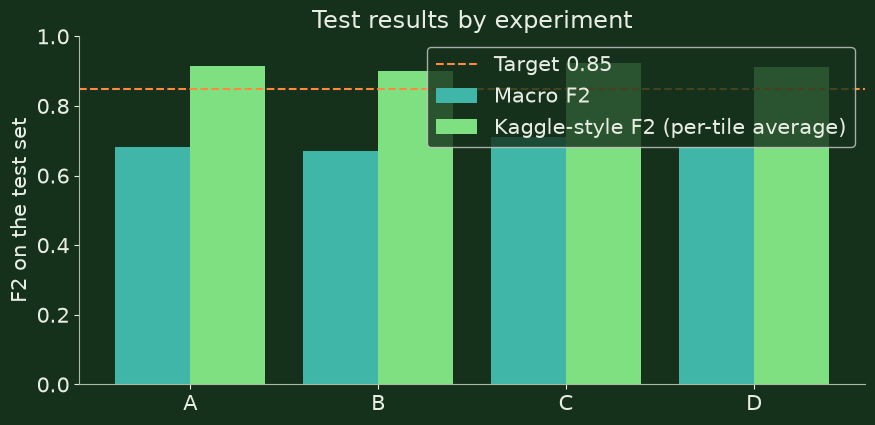

In [109]:
# Create matplotlib figure/axes
fig, ax = plt.subplots(figsize=(9, 4.5))
# Set `x` = np.arange(len(expNames))
x = np.arange(len(expNames))
# Draw or configure plot elements
ax.bar(x - 0.2, [res[n]["macro_F2"] for n in expNames], 0.4, label="Macro F2", color="#3FB6A8")
# Draw or configure plot elements
ax.bar(x + 0.2, [res[n]["samples_F2 (Kaggle metric)"] for n in expNames], 0.4,
       # Keyword/field `label`
       label="Kaggle-style F2 (per-tile average)", color="#7EE081")
# Draw or configure plot elements
ax.axhline(0.85, color="#FF8A3D", ls="--", label="Target 0.85")
# Draw or configure plot elements
ax.set_xticks(x)
# Draw or configure plot elements
ax.set_xticklabels([n.split("_", 1)[0] for n in expNames])
# Draw or configure plot elements
ax.set_ylim(0, 1)
# Draw or configure plot elements
ax.set_ylabel("F2 on the test set")
# Draw or configure plot elements
ax.legend()
# Draw or configure plot elements
ax.set_title("Test results by experiment")
# Run this pipeline step
plt.tight_layout()
# Save figure PNG for the report/deck
plt.savefig(f"{figDir}/fig_results.png", dpi=200)
# Render the figure in the notebook UI
plt.show()
# Close figure to release memory
plt.close()

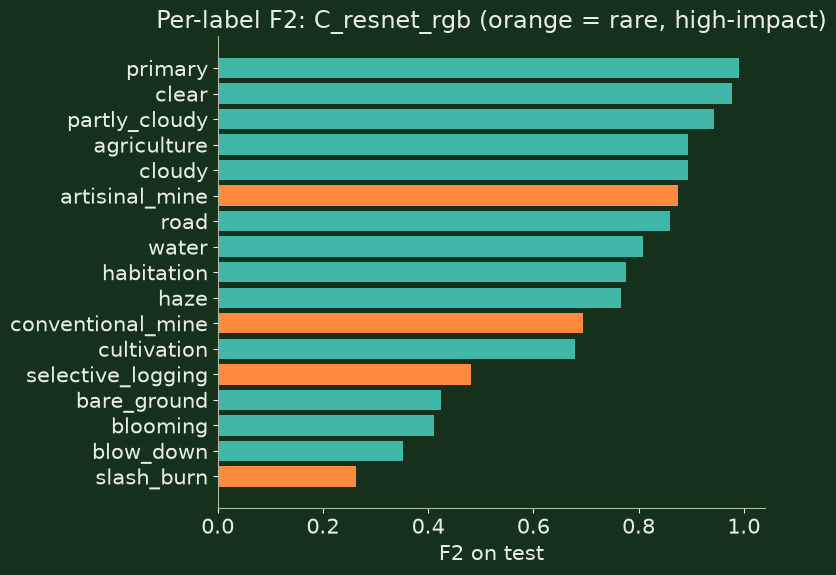

In [110]:
# Set `best` = max(expNames, key=lambda n: res[n]["macro_F2"])
best = max(expNames, key=lambda n: res[n]["macro_F2"])
# Set `f2l` = f2_per_label(store[best]["y"], store[best]["pred"])
f2l = f2_per_label(store[best]["y"], store[best]["pred"])
# Set `order` = np.argsort(f2l)
order = np.argsort(f2l)
# Create matplotlib figure/axes
fig, ax = plt.subplots(figsize=(8, 6))
# Draw or configure plot elements
ax.barh([labels[i] for i in order], f2l[order],
        # Keyword/field `color`
        color=["#FF8A3D" if i in rareIdx else "#3FB6A8" for i in order])
# Draw or configure plot elements
ax.set_xlabel("F2 on test")
# Draw or configure plot elements
ax.set_title(f"Per-label F2: {best} (orange = rare, high-impact)")
# Run this pipeline step
plt.tight_layout()
# Save figure PNG for the report/deck
plt.savefig(f"{figDir}/fig_per_label_f2.png", dpi=200)
# Render the figure in the notebook UI
plt.show()
# Close figure to release memory
plt.close()
# Export a metrics/label table as CSV
pd.DataFrame({"label": labels, "F2": f2l}).sort_values("F2").to_csv(
    # String entry in this collection
    f"{figDir}/per_label_f2_{best}.csv", index=False)

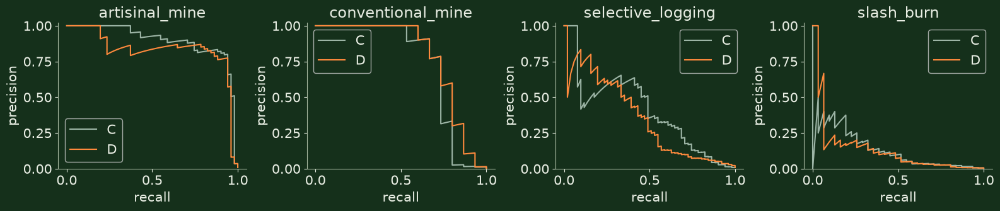

In [111]:
# Conditional branch
if "C_resnet_rgb" in store and "D_resnet_nir_ndvi" in store:
    # Set `pair` = ("C_resnet_rgb", "D_resnet_nir_ndvi")
    pair = ("C_resnet_rgb", "D_resnet_nir_ndvi")
# Alternate conditional branch
elif len(expNames) >= 2:
    # Set `pair` = (expNames[0], expNames[-1])
    pair = (expNames[0], expNames[-1])
# Fallback when earlier conditions were false
else:
    # Set `pair` = (expNames[0], expNames[0])
    pair = (expNames[0], expNames[0])
# Conditional branch
if rare:
    # Create matplotlib figure/axes
    fig, axes = plt.subplots(1, len(rare), figsize=(4 * len(rare), 3.6), squeeze=False)
    # Iterate over this sequence
    for ax, l in zip(axes[0], rare):
        # Set `j` = labels.index(l)
        j = labels.index(l)
        # Iterate over this sequence
        for n, c in zip(dict.fromkeys(pair), ["#9DB5A6", "#FF8A3D"]):
            # Set `p, r, _` = precision_recall_curve(store[n]["y"][:, j], store[n]["probs"][:, j])
            p, r, _ = precision_recall_curve(store[n]["y"][:, j], store[n]["probs"][:, j])
            # Draw or configure plot elements
            ax.plot(r, p, color=c, label=n.split("_", 1)[0])
        # Draw or configure plot elements
        ax.set_title(l)
        # Draw or configure plot elements
        ax.set_xlabel("recall")
        # Draw or configure plot elements
        ax.set_ylabel("precision")
        # Draw or configure plot elements
        ax.set_ylim(0, 1.02)
        # Draw or configure plot elements
        ax.legend()
    # Run this pipeline step
    plt.tight_layout()
    # Save figure PNG for the report/deck
    plt.savefig(f"{figDir}/fig_pr_rare.png", dpi=200)
    # Render the figure in the notebook UI
    plt.show()
    # Close figure to release memory
    plt.close()
# Fallback when earlier conditions were false
else:
    # Print status / metrics to the notebook
    print("No rare labels found for PR curves.")

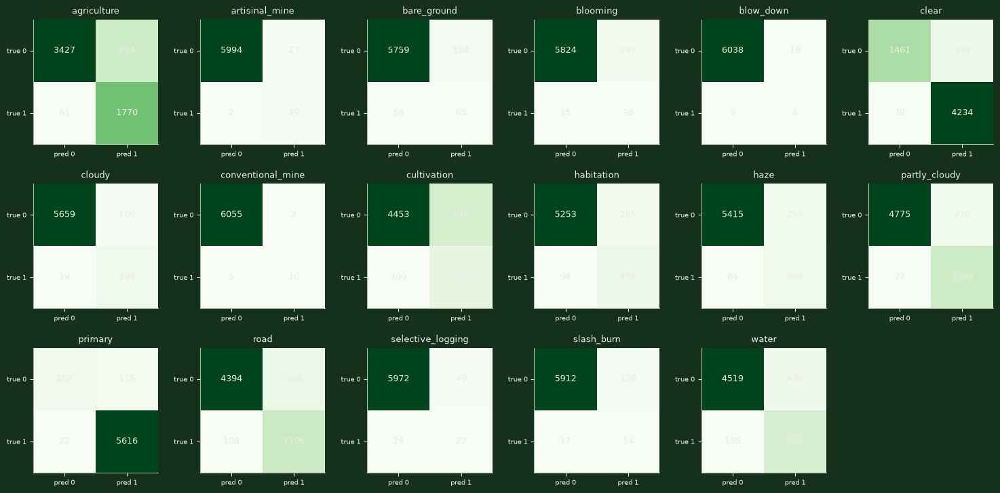

In [112]:
# Set `cms` = multilabel_confusion_matrix(store[best]["y"], store[best]["pred"].asty…
cms = multilabel_confusion_matrix(store[best]["y"], store[best]["pred"].astype(int))
# Create matplotlib figure/axes
fig, axes = plt.subplots(3, 6, figsize=(15, 7.5))
# Iterate over this sequence
for ax in axes.ravel():
    # Draw or configure plot elements
    ax.axis("off")
# Iterate over this sequence
for j, ax in enumerate(axes.ravel()[:17]):
    # Draw or configure plot elements
    ax.axis("on")
    # Draw or configure plot elements
    ax.imshow(cms[j], cmap="Greens")
    # Iterate over this sequence
    for (a, b), v in np.ndenumerate(cms[j]):
        # Draw or configure plot elements
        ax.text(b, a, int(v), ha="center", va="center", fontsize=9)
    # Draw or configure plot elements
    ax.set_title(labels[j], fontsize=9)
    # Draw or configure plot elements
    ax.set_xticks([0, 1])
    # Draw or configure plot elements
    ax.set_xticklabels(["pred 0", "pred 1"], fontsize=7)
    # Draw or configure plot elements
    ax.set_yticks([0, 1])
    # Draw or configure plot elements
    ax.set_yticklabels(["true 0", "true 1"], fontsize=7)
# Run this pipeline step
plt.tight_layout()
# Save figure PNG for the report/deck
plt.savefig(f"{figDir}/fig_confusion_matrices.png", dpi=200)
# Render the figure in the notebook UI
plt.show()
# Close figure to release memory
plt.close()

In [113]:
# Print status / metrics to the notebook
print("\nBest experiment by macro F2:", best)
# Iterate over this sequence
for n in expNames:
    # Set `r` = res[n]
    r = res[n]
    # Print status / metrics to the notebook
    print(f"{n}: macro F2 {r['macro_F2']:.3f} | Kaggle-style F2 "
          # String entry in this collection
          f"{r['samples_F2 (Kaggle metric)']:.3f} | rare recall {r['rare_recall_mean']:.3f}")
# Print status / metrics to the notebook
print("Targets: macro F2 >= 0.85, rare recall >= 0.60. Report honestly if you miss them.")
# Print status / metrics to the notebook
print("Figures saved in", figDir)


Best experiment by macro F2: C_resnet_rgb
A_scratch_rgb: macro F2 0.682 | Kaggle-style F2 0.914 | rare recall 0.615
B_scratch_nir_ndvi: macro F2 0.670 | Kaggle-style F2 0.901 | rare recall 0.629
C_resnet_rgb: macro F2 0.711 | Kaggle-style F2 0.922 | rare recall 0.652
D_resnet_nir_ndvi: macro F2 0.681 | Kaggle-style F2 0.913 | rare recall 0.590
Targets: macro F2 >= 0.85, rare recall >= 0.60. Report honestly if you miss them.
Figures saved in /mnt/c/Users/legen/amazon_project/figs


In [114]:
# Import: import torch.nn.functional as F
import torch.nn.functional as F

# Read path/config from environment
root = os.environ.get("AMAZON_ROOT", "/mnt/c/Users/legen/amazon_project")

# Set `cache, runs, figDir` = f"{root}/cache", f"{root}/runs", f"{root}/figs"
cache, runs, figDir = f"{root}/cache", f"{root}/runs", f"{root}/figs"
# Ensure output directory exists
os.makedirs(figDir, exist_ok=True)
# CUDA / GPU related call
device = "cuda" if torch.cuda.is_available() else "cpu"
# Load JSON metadata from disk
labels = json.load(open(f"{cache}/labels.json"))
# Set `nLabels` = len(labels)
nLabels = len(labels)
# Load NumPy array (often memory-mapped)
xAll = np.load(f"{cache}/X.npy", mmap_mode="r")
# Load NumPy array (often memory-mapped)
st = np.load(f"{cache}/stats.npz")
# Set `chanMean, chanStd` = st["mean"], st["std"]
chanMean, chanStd = st["mean"], st["std"]
# Set `expChans` = {"C_resnet_rgb": [0, 1, 2], "D_resnet_nir_ndvi": [0, 1, 2, 3, 4]}
expChans = {"C_resnet_rgb": [0, 1, 2], "D_resnet_nir_ndvi": [0, 1, 2, 3, 4]}
# Check that this path exists
expChans = {n: ch for n, ch in expChans.items() if os.path.exists(f"{runs}/{n}.pt")}
# Set `targets` = [l for l in ["selective_logging", "slash_burn", "artisinal_mine", "agr…
targets = [l for l in ["selective_logging", "slash_burn", "artisinal_mine", "agriculture"]
           # Continuation of the multi-line expression
           if l in labels]
# Conditional branch
if not expChans:
    # Stop with an error when setup/data is invalid
    raise SystemExit("No ResNet checkpoints found. Train C (and D if TIFs) in 04 first.")

In [115]:
# Define function `build_resnet`
def build_resnet(cIn):
    # Set `m` = torchvision.models.resnet34(weights=None)
    m = torchvision.models.resnet34(weights=None)
    # Set `m.conv1` = nn.Conv2d(cIn, 64, 7, 2, 3, bias=False)
    m.conv1 = nn.Conv2d(cIn, 64, 7, 2, 3, bias=False)
    # Set `m.fc` = nn.Linear(m.fc.in_features, nLabels)
    m.fc = nn.Linear(m.fc.in_features, nLabels)
    # Return result to caller
    return m

# Set `models, data` = {}, {}
models, data = {}, {}
# Iterate over this sequence
for n, ch in expChans.items():
    # Set `m` = build_resnet(len(ch))
    m = build_resnet(len(ch))
    # Try block — catch failures below
    try:
        # Set `state` = torch.load(f"{runs}/{n}.pt", map_location="cpu", weights_only=True)
        state = torch.load(f"{runs}/{n}.pt", map_location="cpu", weights_only=True)
    # Handle exception from the try block
    except TypeError:
        # Set `state` = torch.load(f"{runs}/{n}.pt", map_location="cpu")
        state = torch.load(f"{runs}/{n}.pt", map_location="cpu")
    # Run this pipeline step
    m.load_state_dict(state)
    # Set `models[n]` = m.to(device).eval()
    models[n] = m.to(device).eval()
    # Load NumPy array (often memory-mapped)
    d = np.load(f"{runs}/{n}_probs.npz")
    # Load JSON metadata from disk
    thr = np.array([json.load(open(f"{runs}/thresholds_{n}.json"))[l] for l in labels])
    # Set `data[n]` = dict(pred=d["test_probs"] >= thr[None, :], y=d["test_y"], idx=d["test_…
    data[n] = dict(pred=d["test_probs"] >= thr[None, :], y=d["test_y"], idx=d["test_idx"])

# Set `ref` = "C_resnet_rgb" if "C_resnet_rgb" in data else next(iter(data))
ref = "C_resnet_rgb" if "C_resnet_rgb" in data else next(iter(data))
# Set `testIdx` = data[ref]["idx"]
testIdx = data[ref]["idx"]
# Set `y` = data[ref]["y"]
y = data[ref]["y"]
# Conditional branch
if "C_resnet_rgb" in data and "D_resnet_nir_ndvi" in data:
    # Assert an invariant (fail fast if violated)
    assert (data["C_resnet_rgb"]["idx"] == data["D_resnet_nir_ndvi"]["idx"]).all()

In [116]:
# Define function `gradcam`
def gradcam(model, x, labelJ):
    # Set `acts, grads` = [], []
    acts, grads = [], []
    # Define function `save_act`
    def save_act(mod, inp, out):
        # Run this pipeline step
        acts.append(out)
        # Run this pipeline step
        out.register_hook(lambda g: grads.append(g))
    # Set `h` = model.layer4.register_forward_hook(save_act)
    h = model.layer4.register_forward_hook(save_act)
    # Reset gradients before the next step
    model.zero_grad()
    # Set `out` = model(x)
    out = model(x)
    # Backpropagate loss gradients
    out[0, labelJ].backward()
    # Run this pipeline step
    h.remove()
    # Set `w` = grads[0].mean((2, 3), keepdim=True)
    w = grads[0].mean((2, 3), keepdim=True)
    # Set `cam` = F.relu((w * acts[0]).sum(1, keepdim=True))
    cam = F.relu((w * acts[0]).sum(1, keepdim=True))
    # Set `cam` = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=F…
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    # Set `cam` = cam - cam.min()
    cam = cam - cam.min()
    # Return result to caller
    return (cam / (cam.max() + 1e-8)).detach().cpu().numpy()

# Define function `prep`
def prep(gi, n):
    # Set `ch` = expChans[n]
    ch = expChans[n]
    # Set `x` = torch.from_numpy(np.asarray(xAll[gi])[ch].astype(np.float32))[None].to…
    x = torch.from_numpy(np.asarray(xAll[gi])[ch].astype(np.float32))[None].to(device)
    # Set `mean` = torch.tensor(chanMean[ch], device=device).view(1, -1, 1, 1).float()
    mean = torch.tensor(chanMean[ch], device=device).view(1, -1, 1, 1).float()
    # Set `std` = torch.tensor(chanStd[ch], device=device).view(1, -1, 1, 1).float()
    std = torch.tensor(chanStd[ch], device=device).view(1, -1, 1, 1).float()
    # Return result to caller
    return (x - mean) / std

# Define function `rgb_view`
def rgb_view(gi):
    # Return result to caller
    return np.clip(np.transpose(np.asarray(xAll[gi])[:3].astype(np.float32), (1, 2, 0)) ** 0.8, 0, 1)

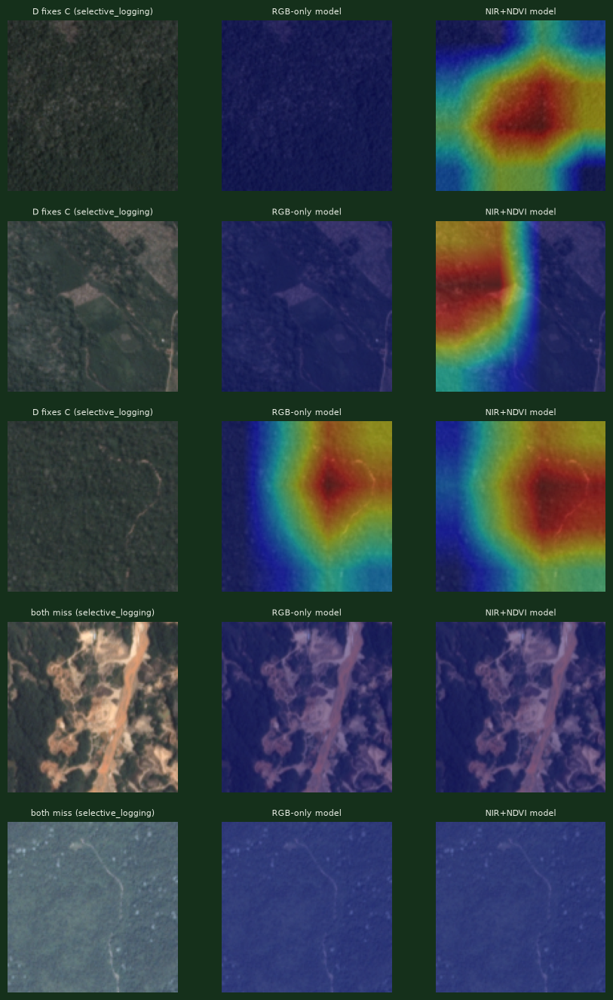

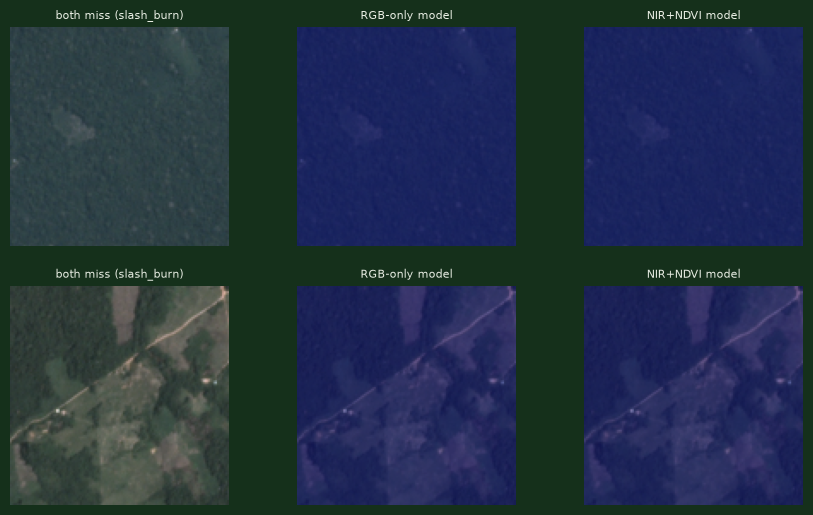

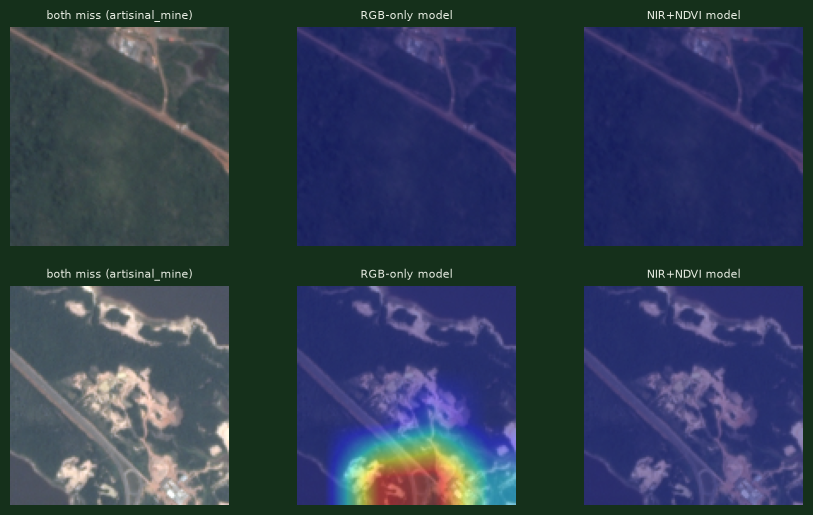

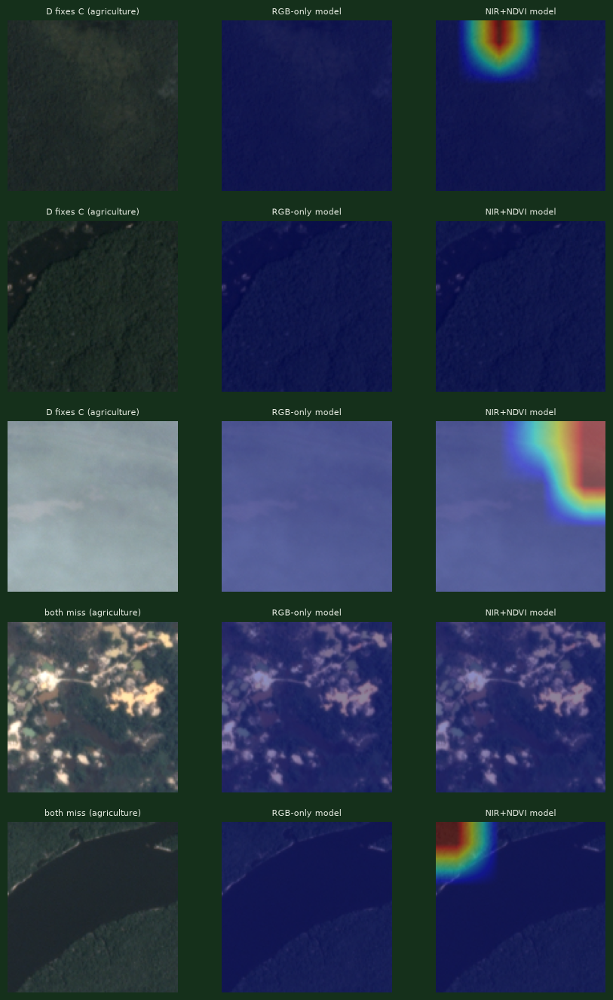

In [117]:
# Set `hasBoth` = "C_resnet_rgb" in data and "D_resnet_nir_ndvi" in data
hasBoth = "C_resnet_rgb" in data and "D_resnet_nir_ndvi" in data
# Iterate over this sequence
for lab in targets:
    # Set `j` = labels.index(lab)
    j = labels.index(lab)
    # Set `truth` = y[:, j] == 1
    truth = y[:, j] == 1
    # Conditional branch
    if hasBoth:
        # Set `cData, dData` = data["C_resnet_rgb"], data["D_resnet_nir_ndvi"]
        cData, dData = data["C_resnet_rgb"], data["D_resnet_nir_ndvi"]
        # Set `fixed` = np.where(truth & ~cData["pred"][:, j] & dData["pred"][:, j])[0][:3]
        fixed = np.where(truth & ~cData["pred"][:, j] & dData["pred"][:, j])[0][:3]
        # Set `both` = np.where(truth & ~cData["pred"][:, j] & ~dData["pred"][:, j])[0][:2]
        both = np.where(truth & ~cData["pred"][:, j] & ~dData["pred"][:, j])[0][:2]
        # Set `picks` = [("D fixes C", i) for i in fixed] + [("both miss", i) for i in both]
        picks = [("D fixes C", i) for i in fixed] + [("both miss", i) for i in both]
        # Set `modelNames` = ["C_resnet_rgb", "D_resnet_nir_ndvi"]
        modelNames = ["C_resnet_rgb", "D_resnet_nir_ndvi"]
        # Set `titles` = ["RGB-only model", "NIR+NDVI model"]
        titles = ["RGB-only model", "NIR+NDVI model"]
        # Set `ncols` = 3
        ncols = 3
    # Fallback when earlier conditions were false
    else:
        # Set `n0` = ref
        n0 = ref
        # Set `miss` = np.where(truth & ~data[n0]["pred"][:, j])[0][:3]
        miss = np.where(truth & ~data[n0]["pred"][:, j])[0][:3]
        # Set `hit` = np.where(truth & data[n0]["pred"][:, j])[0][:2]
        hit = np.where(truth & data[n0]["pred"][:, j])[0][:2]
        # Set `picks` = [("model miss", i) for i in miss] + [("model hit", i) for i in hit]
        picks = [("model miss", i) for i in miss] + [("model hit", i) for i in hit]
        # Set `modelNames` = [n0]
        modelNames = [n0]
        # Set `titles` = ["RGB Grad-CAM"]
        titles = ["RGB Grad-CAM"]
        # Set `ncols` = 2
        ncols = 2
    # Conditional branch
    if not picks:
        # Skip to next loop iteration
        continue
    # Create matplotlib figure/axes
    fig, axes = plt.subplots(len(picks), ncols, figsize=(3 * ncols, 2.7 * len(picks)),
                             # Keyword/field `squeeze`
                             squeeze=False)
    # Iterate over this sequence
    for r, (kind, i) in enumerate(picks):
        # Set `gi` = int(testIdx[i])
        gi = int(testIdx[i])
        # Set `base` = rgb_view(gi)
        base = rgb_view(gi)
        # Draw or configure plot elements
        axes[r][0].imshow(base)
        # Draw or configure plot elements
        axes[r][0].set_title(f"{kind} ({lab})", fontsize=8)
        # Iterate over this sequence
        for c, n in enumerate(modelNames, start=1):
            # Set `cam` = gradcam(models[n], prep(gi, n), j)
            cam = gradcam(models[n], prep(gi, n), j)
            # Draw or configure plot elements
            axes[r][c].imshow(base)
            # Draw or configure plot elements
            axes[r][c].imshow(cam, cmap="jet", alpha=0.45)
            # Draw or configure plot elements
            axes[r][c].set_title(titles[c - 1], fontsize=8)
        # Iterate over this sequence
        for a in axes[r]:
            # Run this pipeline step
            a.axis("off")
    # Run this pipeline step
    plt.tight_layout()
    # Save figure PNG for the report/deck
    plt.savefig(f"{figDir}/fig_gradcam_{lab}.png", dpi=200)
    # Render the figure in the notebook UI
    plt.show()
    # Close figure to release memory
    plt.close()

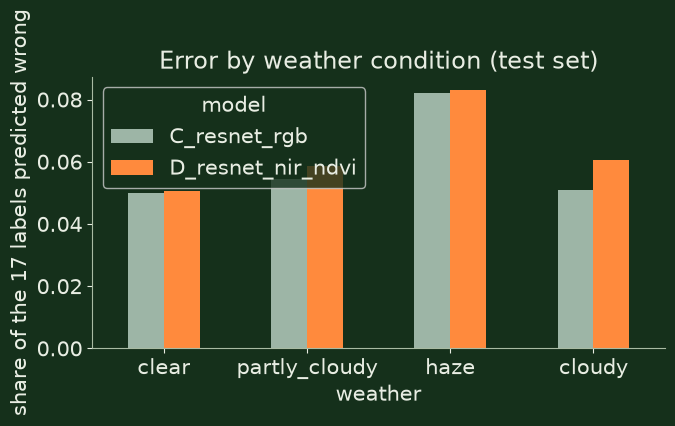

In [118]:
# Set `weather` = [w for w in ["clear", "partly_cloudy", "haze", "cloudy"] if w in label…
weather = [w for w in ["clear", "partly_cloudy", "haze", "cloudy"] if w in labels]
# Set `rows` = []
rows = []
# Iterate over this sequence
for n in expChans:
    # Set `wrong` = (data[n]["pred"].astype(int) != y).mean(1)
    wrong = (data[n]["pred"].astype(int) != y).mean(1)
    # Iterate over this sequence
    for w in weather:
        # Set `m` = y[:, labels.index(w)] == 1
        m = y[:, labels.index(w)] == 1
        # Set `rows.append(dict(model` = n, weather=w, tiles=int(m.sum())
        rows.append(dict(model=n, weather=w, tiles=int(m.sum()),
                         # Keyword/field `mean_label_error`
                         mean_label_error=float(wrong[m].mean())))
# Set `err` = pd.DataFrame(rows)
err = pd.DataFrame(rows)
# Export a metrics/label table as CSV
err.to_csv(f"{figDir}/error_by_weather.csv", index=False)
# Set `pv` = err.pivot(index="weather", columns="model", values="mean_label_error")…
pv = err.pivot(index="weather", columns="model", values="mean_label_error").loc[weather]
# Set `colors` = ["#9DB5A6", "#FF8A3D"][: len(pv.columns)]
colors = ["#9DB5A6", "#FF8A3D"][: len(pv.columns)]
# Set `pv.plot.bar(figsize` = (7, 4), color=colors)
pv.plot.bar(figsize=(7, 4), color=colors)
# Run this pipeline step
plt.ylabel("share of the 17 labels predicted wrong")
# Run this pipeline step
plt.title("Error by weather condition (test set)")
# Set `plt.xticks(rotation` = 0)
plt.xticks(rotation=0)
# Run this pipeline step
plt.tight_layout()
# Save figure PNG for the report/deck
plt.savefig(f"{figDir}/fig_error_by_weather.png", dpi=200)
# Render the figure in the notebook UI
plt.show()
# Close figure to release memory
plt.close()

In [119]:
# Default env path if unset
os.environ.setdefault("AMAZON_ROOT", "/mnt/c/Users/legen/amazon_project")
# Default env path if unset
os.environ.setdefault("AMAZON_RAW", "/mnt/c/Users/legen/amazon_data")
# Default env path if unset
os.environ.setdefault("AMAZON_ROOT_TIF", "/mnt/c/Users/legen/amazon_project_tif")

# Set `raw` = os.environ["AMAZON_RAW"]
raw = os.environ["AMAZON_RAW"]
# Set `jpgRoot` = os.environ["AMAZON_ROOT"]
jpgRoot = os.environ["AMAZON_ROOT"]
# Set `tifRoot` = os.environ["AMAZON_ROOT_TIF"]
tifRoot = os.environ["AMAZON_ROOT_TIF"]

# Set `exps` = ["A", "B", "C", "D", "E"]
exps = ["A", "B", "C", "D", "E"]
# Set `batchSize` = 128
batchSize = 128
# Set `epochsBd` = 14
epochsBd = 14
# Set `tileSizeBd` = 128
tileSizeBd = 128
# Set `seedBd` = 42
seedBd = 42
# Set `rebuildCache` = False
rebuildCache = False
# Set `noPretrained` = False
noPretrained = False
# Set `subsetBd` = 0
subsetBd = 0
# Set `makeFigs` = True
makeFigs = True
# Set `allowJpgReuse` = False
allowJpgReuse = False
# Set `retrainBd` = False
retrainBd = False

# Set `root` = tifRoot
root = tifRoot
# Set `cache, runs, figDir` = f"{root}/cache", f"{root}/runs", f"{root}/figs"
cache, runs, figDir = f"{root}/cache", f"{root}/runs", f"{root}/figs"
# Iterate over this sequence
for d in (root, cache, runs, figDir):
    # Ensure output directory exists
    os.makedirs(d, exist_ok=True)

# CUDA / GPU related call
device = "cuda" if torch.cuda.is_available() else "cpu"
# Print status / metrics to the notebook
print("Device:", device)
# Conditional branch
if device != "cuda":
    # Print status / metrics to the notebook
    print("WARNING: no GPU. Training will be extremely slow.")

# Conditional branch
if retrainBd:
    # Iterate over this sequence
    for n in ["B_scratch_nir_ndvi", "D_resnet_nir_ndvi"]:
        # Iterate over this sequence
        for p in glob.glob(f"{runs}/{n}*") + glob.glob(f"{runs}/thresholds_{n}.json"):
            # Run this pipeline step
            os.remove(p)
            # Print status / metrics to the notebook
            print("removed", p)

# Set `LOG` = []
LOG = []
# Define function `say`
def say(*a):
    # Set `s` = " ".join(str(x) for x in a)
    s = " ".join(str(x) for x in a)
    # Print status / metrics to the notebook
    print(s)
    # Run this pipeline step
    LOG.append(s)

# Find matching files under the data root
tifs = sorted(glob.glob(f"{raw}/**/*.tif", recursive=True))
# Set `csvs` = [
csvs = [
    # Continuation of the multi-line expression
    p for p in (
        # Keyword/field `glob.glob(f"{raw}/**/labels_train_v2.csv", recursive`
        glob.glob(f"{raw}/**/labels_train_v2.csv", recursive=True)
        # Keyword/field `+ glob.glob(f"{raw}/**/train_v2.csv", recursive`
        + glob.glob(f"{raw}/**/train_v2.csv", recursive=True)
        # Keyword/field `+ glob.glob(f"{raw}/**/train_classes.csv", recursive`
        + glob.glob(f"{raw}/**/train_classes.csv", recursive=True)
    # Continuation of the multi-line expression
    )
    # Continuation of the multi-line expression
    if os.path.isfile(p)
# Continuation of the multi-line expression
]
# Conditional branch
if len(tifs) < 100 or not csvs:
    # Stop with an error when setup/data is invalid
    raise SystemExit(
        # String entry in this collection
        f"TIF data not ready under {raw}: {len(tifs)} .tif, {len(csvs)} csv. "
        # String entry in this collection
        "Unpack train-tif-v2 + train_v2.csv first (see HOW_TO_RUN_B_AND_D.md)."
    # Continuation of the multi-line expression
    )

# Set `tifDir` = os.path.dirname(tifs[0])
tifDir = os.path.dirname(tifs[0])
# Load the Planet label CSV
df = pd.read_csv(csvs[0])
# Check that this path exists
df = df[df["image_name"].map(lambda n: os.path.exists(os.path.join(tifDir, n + ".tif")))].reset_index(drop=True)
# Conditional branch
if subsetBd:
    # Set `df` = df.sample(subsetBd, random_state=seedBd).reset_index(drop=True)
    df = df.sample(subsetBd, random_state=seedBd).reset_index(drop=True)
# Set `tagLists` = df["tags"].str.split()
tagLists = df["tags"].str.split()
# Set `labels` = sorted({t for tl in tagLists for t in tl})
labels = sorted({t for tl in tagLists for t in tl})
# Set `nLabels` = len(labels)
nLabels = len(labels)
# Set `y` = np.zeros((len(df), nLabels), dtype=np.uint8)
y = np.zeros((len(df), nLabels), dtype=np.uint8)
# Iterate over this sequence
for i, tl in enumerate(tagLists):
    # Iterate over this sequence
    for t in tl:
        # Set `y[i, labels.index(t)]` = 1
        y[i, labels.index(t)] = 1
# Set `names` = df["image_name"].tolist()
names = df["image_name"].tolist()
# Set `nTiles` = len(names)
nTiles = len(names)
# Print status / metrics to the notebook
say(f"Tiles with a TIF: {nTiles} | labels: {nLabels}")

# Define function `read_tif`
def read_tif(n):
    # Use tifffile for GeoTIFF I/O
    a = tifffile.imread(os.path.join(tifDir, n + ".tif")).astype(np.float32)
    # Conditional branch
    if a.ndim == 3 and a.shape[0] == 4 and a.shape[-1] != 4:
        # Set `a` = np.transpose(a, (1, 2, 0))
        a = np.transpose(a, (1, 2, 0))
    # Return result to caller
    return a

Device: cuda
Tiles with a TIF: 40479 | labels: 17


In [120]:
# Set `metaPath` = f"{cache}/cache_meta.json"
metaPath = f"{cache}/cache_meta.json"
# Set `metaOk` = (
metaOk = (
    # Continuation of the multi-line expression
    os.path.exists(metaPath) and not rebuildCache and os.path.exists(f"{cache}/X.npy")
    # Keyword/field `and json.load(open(metaPath)).get("n")`
    and json.load(open(metaPath)).get("n") == nTiles
    # Keyword/field `and json.load(open(metaPath)).get("tile")`
    and json.load(open(metaPath)).get("tile") == tileSizeBd
# Continuation of the multi-line expression
)
# Conditional branch
if not metaOk:
    # Fix RNG seed for reproducibility
    rng = np.random.RandomState(seedBd)
    # Set `samp` = rng.choice(nTiles, min(600, nTiles), replace=False)
    samp = rng.choice(nTiles, min(600, nTiles), replace=False)
    # Set `rawSamp` = np.stack([read_tif(names[i]) for i in samp])
    rawSamp = np.stack([read_tif(names[i]) for i in samp])
    # Set `ys` = y[samp]
    ys = y[samp]
    # Set `prim` = ys[:, labels.index("primary")] == 1
    prim = ys[:, labels.index("primary")] == 1
    # Set `open_` = (ys[:, labels.index("agriculture")] == 1) | (ys[:, labels.index("bare_…
    open_ = (ys[:, labels.index("agriculture")] == 1) | (ys[:, labels.index("bare_ground")] == 1)
    # Set `prim, open_` = prim & ~open_, open_ & ~prim
    prim, open_ = prim & ~open_, open_ & ~prim
    # Set `tileMean` = rawSamp.reshape(len(samp), -1, 4).mean(1)
    tileMean = rawSamp.reshape(len(samp), -1, 4).mean(1)
    # Conditional branch
    if prim.sum() and open_.sum():
        # Set `ratio` = tileMean[open_].mean(0) / tileMean[prim].mean(0)
        ratio = tileMean[open_].mean(0) / tileMean[prim].mean(0)
        # Set `bandOrder` = "RGBN" if ratio[0] > 1.15 * ratio[2] else "BGRN"
        bandOrder = "RGBN" if ratio[0] > 1.15 * ratio[2] else "BGRN"
    # Fallback when earlier conditions were false
    else:
        # Set `bandOrder` = "BGRN"
        bandOrder = "BGRN"
    # Set `orders` = {"BGRN": dict(b=0, g=1, r=2, nir=3), "RGBN": dict(b=2, g=1, r=0, nir=3…
    orders = {"BGRN": dict(b=0, g=1, r=2, nir=3), "RGBN": dict(b=2, g=1, r=0, nir=3)}
    # Set `bandMap` = orders[bandOrder]
    bandMap = orders[bandOrder]
    # Set `ndviT` = (tileMean[:, bandMap["nir"]] - tileMean[:, bandMap["r"]]) / (
    ndviT = (tileMean[:, bandMap["nir"]] - tileMean[:, bandMap["r"]]) / (
        # Dict entry for key `tileMean[`
        tileMean[:, bandMap["nir"]] + tileMean[:, bandMap["r"]] + 1e-6)
    # Iterate over this sequence
    for labName in ("primary", "agriculture", "water"):
        # Set `m` = ys[:, labels.index(labName)] == 1
        m = ys[:, labels.index(labName)] == 1
        # Conditional branch
        if m.sum():
            # Print status / metrics to the notebook
            say(f"mean NDVI for {labName}: {ndviT[m].mean():.3f}")
    # Print status / metrics to the notebook
    say("Chosen band order:", bandOrder, "(forest NDVI should be highest, water lowest)")
    # Robust band min/max via percentiles
    lo = np.percentile(rawSamp.reshape(-1, 4), 1, axis=0)
    # Robust band min/max via percentiles
    hi = np.percentile(rawSamp.reshape(-1, 4), 99, axis=0)
    # Write JSON metadata to disk
    json.dump({"order": bandOrder, **bandMap}, open(f"{cache}/order.json", "w"))
    # Write JSON metadata to disk
    json.dump({"lo": lo.tolist(), "hi": hi.tolist()}, open(f"{cache}/band_stats.json", "w"))
    # Delete large temporary object to free RAM
    del rawSamp

    # Memory-map large array without full RAM load
    xmm = np.lib.format.open_memmap(
        # String entry in this collection
        f"{cache}/X.npy", mode="w+", dtype=np.float16, shape=(nTiles, 5, tileSizeBd, tileSizeBd))
    # Define function `process`
    def process(i):
        # Set `a` = read_tif(names[i])
        a = read_tif(names[i])
        # Set `red, nir` = a[..., bandMap["r"]], a[..., bandMap["nir"]]
        red, nir = a[..., bandMap["r"]], a[..., bandMap["nir"]]
        # Set `ndvi` = (nir - red) / (nir + red + 1e-6)
        ndvi = (nir - red) / (nir + red + 1e-6)
        # Clamp values into a valid range
        chans = [np.clip((a[..., src] - lo[src]) / (hi[src] - lo[src] + 1e-6), 0, 1)
                 # Continuation of the multi-line expression
                 for src in (bandMap["r"], bandMap["g"], bandMap["b"], bandMap["nir"])]
        # Clamp values into a valid range
        chans.append((np.clip(ndvi, -1, 1) + 1) / 2)
        # Set `arr` = np.stack(chans, -1).astype(np.float32)
        arr = np.stack(chans, -1).astype(np.float32)
        # OpenCV image operation
        arr = cv2.resize(arr, (tileSizeBd, tileSizeBd), interpolation=cv2.INTER_AREA)
        # Set `xmm[i]` = np.transpose(arr, (2, 0, 1)).astype(np.float16)
        xmm[i] = np.transpose(arr, (2, 0, 1)).astype(np.float16)
    # Enter a context manager (auto-closes resources)
    with ThreadPoolExecutor(8) as ex:
        # Iterate over this sequence
        for k, _ in enumerate(ex.map(process, range(nTiles))):
            # Conditional branch
            if k % 2000 == 0:
                # Print status / metrics to the notebook
                print(f"cached {k}/{nTiles}")
    # Run this pipeline step
    xmm.flush()
    # Persist NumPy array(s) to the cache
    np.save(f"{cache}/Y.npy", y)
    # Write JSON metadata to disk
    json.dump(labels, open(f"{cache}/labels.json", "w"))
    # Write JSON metadata to disk
    json.dump(names, open(f"{cache}/names.json", "w"))
    # Write JSON metadata to disk
    json.dump({"n": nTiles, "tile": tileSizeBd, "jpg_mode": False,
               # Dict entry for key `"channels"`
               "channels": ["R", "G", "B", "NIR", "NDVI"]}, open(metaPath, "w"))

    # Set `freq` = y.sum(0)
    freq = y.sum(0)
    # Set `strata` = np.array([min(np.where(row == 1)[0], key=lambda j: freq[j]) for row in…
    strata = np.array([min(np.where(row == 1)[0], key=lambda j: freq[j]) for row in y])
    # Set `idx` = np.arange(nTiles)
    idx = np.arange(nTiles)
    # Stratified train/val/test index split
    tr, tmp = train_test_split(idx, test_size=0.30, stratify=strata, random_state=seedBd)
    # Stratified train/val/test index split
    va, te = train_test_split(tmp, test_size=0.50, stratify=strata[tmp], random_state=seedBd)
    # Persist NumPy array(s) to the cache
    np.savez(f"{cache}/splits.npz", train=np.sort(tr), val=np.sort(va), test=np.sort(te))
    # Load NumPy array (often memory-mapped)
    xr = np.load(f"{cache}/X.npy", mmap_mode="r")
    # Set `pick` = np.sort(rng.choice(np.sort(tr), min(3000, len(tr)), replace=False))
    pick = np.sort(rng.choice(np.sort(tr), min(3000, len(tr)), replace=False))
    # Set `sub` = np.asarray(xr[pick]).astype(np.float32)
    sub = np.asarray(xr[pick]).astype(np.float32)
    # Persist NumPy array(s) to the cache
    np.savez(f"{cache}/stats.npz", mean=sub.mean((0, 2, 3)), std=sub.std((0, 2, 3)) + 1e-6)
    # Print status / metrics to the notebook
    say("Built TIF cache at", cache)
# Fallback when earlier conditions were false
else:
    # Print status / metrics to the notebook
    say("Reusing TIF cache at", cache)

# Load NumPy array (often memory-mapped)
xAll = np.load(f"{cache}/X.npy", mmap_mode="r")
# Load NumPy array (often memory-mapped)
y = np.load(f"{cache}/Y.npy")
# Load JSON metadata from disk
labels = json.load(open(f"{cache}/labels.json"))
# Set `nLabels` = len(labels)
nLabels = len(labels)
# Load NumPy array (often memory-mapped)
sp = np.load(f"{cache}/splits.npz")
# Set `tr, va, te` = sp["train"], sp["val"], sp["test"]
tr, va, te = sp["train"], sp["val"], sp["test"]
# Load NumPy array (often memory-mapped)
st = np.load(f"{cache}/stats.npz")
# Set `chanMean, chanStd` = st["mean"], st["std"]
chanMean, chanStd = st["mean"], st["std"]
# Print status / metrics to the notebook
say("train/val/test:", len(tr), len(va), len(te))

Reusing TIF cache at /mnt/c/Users/legen/amazon_project_tif/cache
train/val/test: 28335 6072 6072


In [121]:
# Set `EXPS` = {
EXPS = {
    # Dict entry for key `"A"`
    "A": ("A_scratch_rgb",      dict(arch="scratch", chans=[0, 1, 2],       lr=3e-3)),
    # Dict entry for key `"B"`
    "B": ("B_scratch_nir_ndvi", dict(arch="scratch", chans=[0, 1, 2, 3, 4], lr=3e-3)),
    # Dict entry for key `"C"`
    "C": ("C_resnet_rgb",       dict(arch="resnet",  chans=[0, 1, 2],       lr=1e-3)),
    # Dict entry for key `"D"`
    "D": ("D_resnet_nir_ndvi",  dict(arch="resnet",  chans=[0, 1, 2, 3, 4], lr=1e-3)),
    # Dict entry for key `"E"`
    "E": ("E_resnet_nir",       dict(arch="resnet",  chans=[0, 1, 2, 3],    lr=1e-3)),
    # Dict entry for key `"F"`
    "F": ("F_scratch_nir",      dict(arch="scratch", chans=[0, 1, 2, 3],    lr=3e-3)),
# Continuation of the multi-line expression
}

# Set `seed, batch, epochs, out` = seedBd, batchSize, epochsBd, runs
seed, batch, epochs, out = seedBd, batchSize, epochsBd, runs
# Set `oversample, tta` = True, True
oversample, tta = True, True

# Iterate over this sequence
for key in exps:
    # Set `name, cfg` = EXPS[key]
    name, cfg = EXPS[key]
    # Set `cfg` = {**cfg, "pretrained": not noPretrained}
    cfg = {**cfg, "pretrained": not noPretrained}
    # Conditional branch
    if os.path.exists(f"{runs}/{name}_probs.npz"):
        # Print status / metrics to the notebook
        print("Skipping", name, "(already trained; delete its files in runs/ to retrain)")
        # Skip to next loop iteration
        continue
    # Run this pipeline step
    run(name, cfg)
    # Load JSON metadata from disk
    hist = json.load(open(f"{runs}/{name}_history.json"))
    # Print status / metrics to the notebook
    say(f"[{name}] best val macro F2@0.2 = {max(h['val_macro_f2_at_0_2'] for h in hist):.4f}")

Skipping A_scratch_rgb (already trained; delete its files in runs/ to retrain)
Skipping B_scratch_nir_ndvi (already trained; delete its files in runs/ to retrain)
Skipping C_resnet_rgb (already trained; delete its files in runs/ to retrain)
Skipping D_resnet_nir_ndvi (already trained; delete its files in runs/ to retrain)
Skipping E_resnet_nir (already trained; delete its files in runs/ to retrain)


In [122]:
# Define function `probs_path`
def probs_path(n):
    # Set `p` = f"{runs}/{n}_probs.npz"
    p = f"{runs}/{n}_probs.npz"
    # Conditional branch
    if os.path.exists(p):
        # Return result to caller
        return p, "TIF run"
    # Set `q` = f"{jpgRoot}/runs/{n}_probs.npz"
    q = f"{jpgRoot}/runs/{n}_probs.npz"
    # Conditional branch
    if allowJpgReuse and os.path.exists(q):
        # Return result to caller
        return q, "reused from your JPG notebook run"
    # Return result to caller
    return None, None

# Set `expNames, src` = [], {}
expNames, src = [], {}
# Iterate over this sequence
for key in "ABCDEF":
    # Set `n` = EXPS[key][0]
    n = EXPS[key][0]
    # Set `p, how` = probs_path(n)
    p, how = probs_path(n)
    # Conditional branch
    if not p:
        # Skip to next loop iteration
        continue
    # Load NumPy array (often memory-mapped)
    d = np.load(p)
    # Conditional branch
    if len(d["test_idx"]) != len(te) or not (d["test_idx"] == te).all():
        # Print status / metrics to the notebook
        say(f"NOTE: {n} from {how} uses a different test split; skipped.")
        # Skip to next loop iteration
        continue
    # Run this pipeline step
    expNames.append(n)
    # Set `src[n]` = how
    src[n] = how
# Print status / metrics to the notebook
say("Experiments evaluated:", {n: src[n] for n in expNames})
# Conditional branch
if not expNames:
    # Stop with an error when setup/data is invalid
    raise SystemExit(
        # String entry in this collection
        "No trained experiments found to evaluate. "
        # String entry in this collection
        "Set exps = [\"A\", \"B\", \"C\", \"D\", \"E\"] and retrain (allowJpgReuse stays False)."
    # Continuation of the multi-line expression
    )

# Set `rareNames` = [l for l in ["artisinal_mine", "artisanal_mine", "conventional_mine"
rareNames = [l for l in ["artisinal_mine", "artisanal_mine", "conventional_mine",
                         # Continuation of the multi-line expression
                         "selective_logging", "slash_burn"] if l in labels]
# Set `rare` = rareNames
rare = rareNames
# Set `rareIdx` = [labels.index(l) for l in rare]
rareIdx = [labels.index(l) for l in rare]

# Set `res, store` = {}, {}
res, store = {}, {}
# Iterate over this sequence
for n in expNames:
    # Load NumPy array (often memory-mapped)
    d = np.load(probs_path(n)[0])
    # Set `thr` = best_thresholds(d["val_y"], d["val_probs"])
    thr = best_thresholds(d["val_y"], d["val_probs"])
    # Set `pred` = d["test_probs"] >= thr[None, :]
    pred = d["test_probs"] >= thr[None, :]
    # Set `res[n]` = metrics(d["test_y"], pred)
    res[n] = metrics(d["test_y"], pred)
    # Set `store[n]` = dict(y=d["test_y"], pred=pred, probs=d["test_probs"], thr=thr)
    store[n] = dict(y=d["test_y"], pred=pred, probs=d["test_probs"], thr=thr)
    # Write JSON metadata to disk
    json.dump(dict(zip(labels, thr.tolist())), open(f"{runs}/thresholds_{n}.json", "w"))
# Set `table` = pd.DataFrame(res).T
table = pd.DataFrame(res).T
# Export a metrics/label table as CSV
table.to_csv(f"{figDir}/results_table.csv")
# Print status / metrics to the notebook
say("\n===== RESULTS TABLE (test set) =====")
# Print status / metrics to the notebook
say(table.round(4).to_string())

# Fix RNG seed for reproducibility
rng = np.random.RandomState(0)
# Set `pairs` = [
pairs = [
    # Continuation of the multi-line expression
    ("A_scratch_rgb", "B_scratch_nir_ndvi", "NDVI effect, scratch CNN (B - A)"),
    # Continuation of the multi-line expression
    ("C_resnet_rgb", "D_resnet_nir_ndvi", "NDVI effect, ResNet (D - C)"),
    # Continuation of the multi-line expression
    ("A_scratch_rgb", "C_resnet_rgb", "Transfer learning, RGB (C - A)"),
    # Continuation of the multi-line expression
    ("B_scratch_nir_ndvi", "D_resnet_nir_ndvi", "Transfer learning, +NDVI (D - B)"),
    # Continuation of the multi-line expression
    ("C_resnet_rgb", "E_resnet_nir", "NIR effect, ResNet (E - C)"),
    # Continuation of the multi-line expression
    ("E_resnet_nir", "D_resnet_nir_ndvi", "NDVI on top of NIR, ResNet (D - E)"),
    # Continuation of the multi-line expression
    ("A_scratch_rgb", "F_scratch_nir", "NIR effect, scratch CNN (F - A)"),
    # Continuation of the multi-line expression
    ("F_scratch_nir", "B_scratch_nir_ndvi", "NDVI on top of NIR, scratch CNN (B - F)"),
# Continuation of the multi-line expression
]
# Set `rows` = []
rows = []
# Iterate over this sequence
for a, b, lab in pairs:
    # Conditional branch
    if a in store and b in store:
        # Set `m, lo_, hi_` = boot_diff(a, b)
        m, lo_, hi_ = boot_diff(a, b)
        # Run this pipeline step
        rows.append(dict(
            # Keyword/field `comparison`
            comparison=lab, mean_macro_F2_diff=m, ci_low=lo_, ci_high=hi_,
            # Keyword/field `verdict`
            verdict="clear gain" if lo_ > 0 else ("clear loss" if hi_ < 0 else "not significant")))
# Set `boot` = pd.DataFrame(rows)
boot = pd.DataFrame(rows)
# Conditional branch
if len(boot):
    # Export a metrics/label table as CSV
    boot.to_csv(f"{figDir}/bootstrap_differences.csv", index=False)
    # Print status / metrics to the notebook
    say("\n===== BOOTSTRAP (1000 resamples, macro F2 difference) =====")
    # Print status / metrics to the notebook
    say(boot.round(4).to_string(index=False))

# Print status / metrics to the notebook
say("\n===== PER-LABEL F2 (test) =====")
# Set `pl` = pd.DataFrame({n: f2_per_label(store[n]["y"], store[n]["pred"]) for n i…
pl = pd.DataFrame({n: f2_per_label(store[n]["y"], store[n]["pred"]) for n in expNames}, index=labels)
# Export a metrics/label table as CSV
pl.to_csv(f"{figDir}/per_label_f2_all.csv")
# Print status / metrics to the notebook
say(pl.round(3).to_string())

# Print status / metrics to the notebook
say("\n===== ERROR BY WEATHER (share of the 17 labels predicted wrong) =====")
# Set `wx` = [w for w in ["clear", "partly_cloudy", "haze", "cloudy"] if w in label…
wx = [w for w in ["clear", "partly_cloudy", "haze", "cloudy"] if w in labels]
# Set `wrows` = []
wrows = []
# Iterate over this sequence
for n in expNames:
    # Set `wrong` = (store[n]["pred"].astype(int) != store[n]["y"]).mean(1)
    wrong = (store[n]["pred"].astype(int) != store[n]["y"]).mean(1)
    # Iterate over this sequence
    for w in wx:
        # Set `m` = store[n]["y"][:, labels.index(w)] == 1
        m = store[n]["y"][:, labels.index(w)] == 1
        # Set `wrows.append(dict(model` = n, weather=w, tiles=int(m.sum())
        wrows.append(dict(model=n, weather=w, tiles=int(m.sum()),
                          # Keyword/field `mean_label_error`
                          mean_label_error=float(wrong[m].mean())))
# Set `werr` = pd.DataFrame(wrows)
werr = pd.DataFrame(wrows)
# Export a metrics/label table as CSV
werr.to_csv(f"{figDir}/error_by_weather.csv", index=False)
# Conditional branch
if len(wx):
    # Print status / metrics to the notebook
    say(werr.pivot(index="weather", columns="model", values="mean_label_error").loc[wx].round(4).to_string())

# Set `mixed` = any("reused" in v for v in src.values())
mixed = any("reused" in v for v in src.values())
# Write JSON metadata to disk
json.dump({
    # Dict entry for key `"sources"`
    "sources": src,
    # Dict entry for key `"results"`
    "results": table.round(4).to_dict(orient="index"),
    # Dict entry for key `"bootstrap"`
    "bootstrap": boot.round(4).to_dict(orient="records") if len(boot) else [],
    # Dict entry for key `"per_label_f2"`
    "per_label_f2": pl.round(4).to_dict(),
    # Dict entry for key `"error_by_weather"`
    "error_by_weather": werr.round(4).to_dict(orient="records"),
    # Dict entry for key `"thresholds"`
    "thresholds": {n: dict(zip(labels, store[n]["thr"].round(2).tolist())) for n in expNames},
# Keyword/field `}, open(f"{root}/results.json", "w"), indent`
}, open(f"{root}/results.json", "w"), indent=1)
# Enter a context manager (auto-closes resources)
with open(f"{root}/results_to_paste.txt", "w") as f:
    # Run this pipeline step
    f.write("\n".join(LOG))
    # Conditional branch
    if mixed:
        # Run this pipeline step
        f.write(
            # String entry in this collection
            "\n\nNOTE: some rows were reused from the JPG notebook run, so the RGB source differs "
            # String entry in this collection
            "from the TIF-based rows. For the cleanest comparison keep allowJpgReuse = False "
            # Continuation of the multi-line expression
            "and train A/C/E on this TIF cache.\n")

Experiments evaluated: {'A_scratch_rgb': 'TIF run', 'B_scratch_nir_ndvi': 'TIF run', 'C_resnet_rgb': 'TIF run', 'D_resnet_nir_ndvi': 'TIF run', 'E_resnet_nir': 'TIF run'}

===== RESULTS TABLE (test set) =====
                    macro_F2  samples_F2 (Kaggle metric)  micro_F2  hamming_loss  rare_recall_mean  recall_artisinal_mine  recall_conventional_mine  recall_selective_logging  recall_slash_burn
A_scratch_rgb         0.6877                      0.9023    0.8902        0.0678            0.6835                 0.7843                    0.7333                    0.7647             0.4516
B_scratch_nir_ndvi    0.6733                      0.9028    0.8922        0.0665            0.6556                 0.8431                    0.6667                    0.7255             0.3871
C_resnet_rgb          0.6955                      0.9106    0.9011        0.0614            0.5998                 0.9412                    0.5333                    0.6667             0.2581
D_resnet_nir_ndvi  

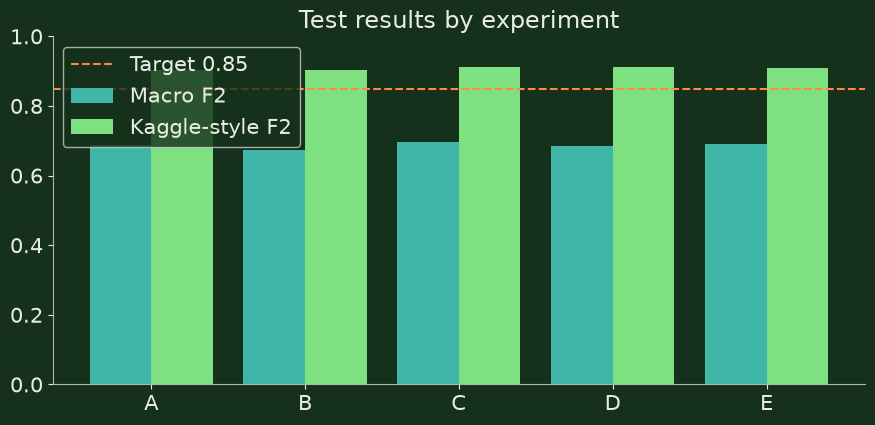

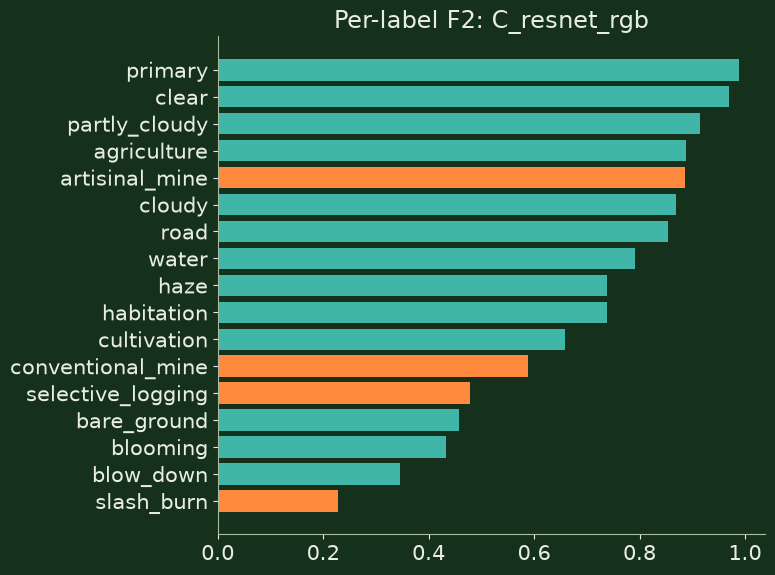

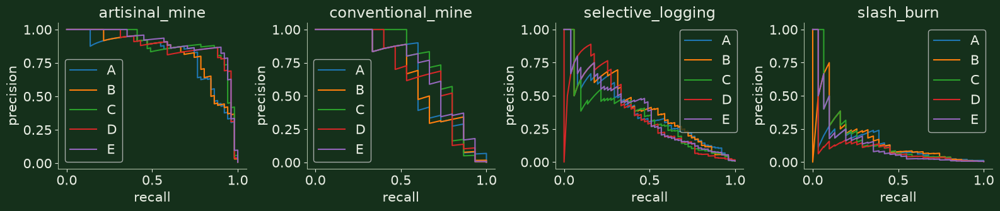

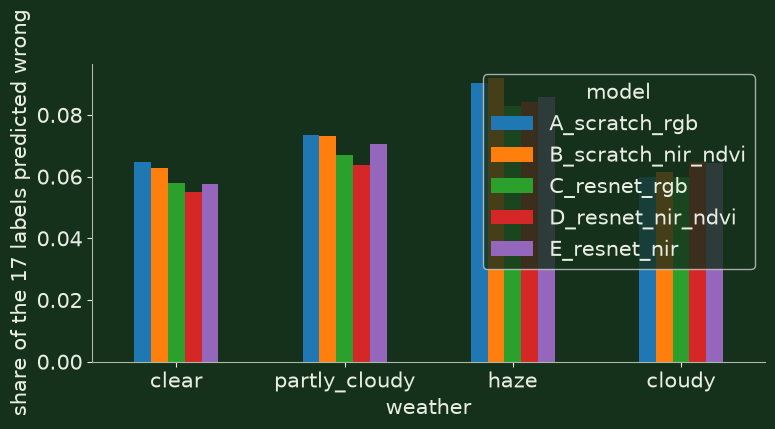

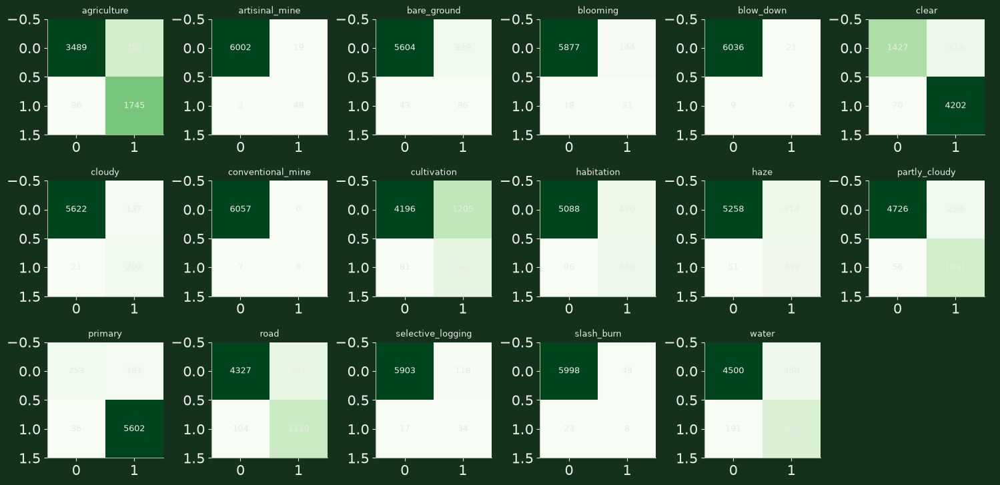

...

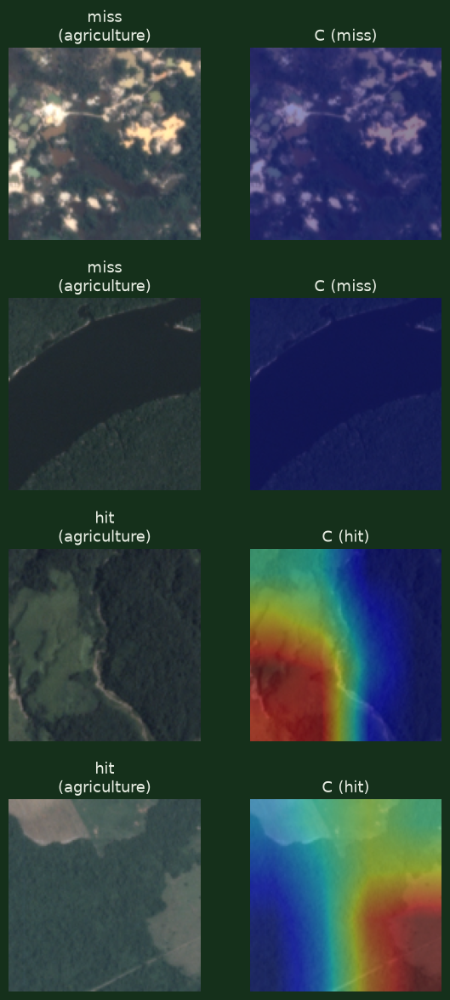

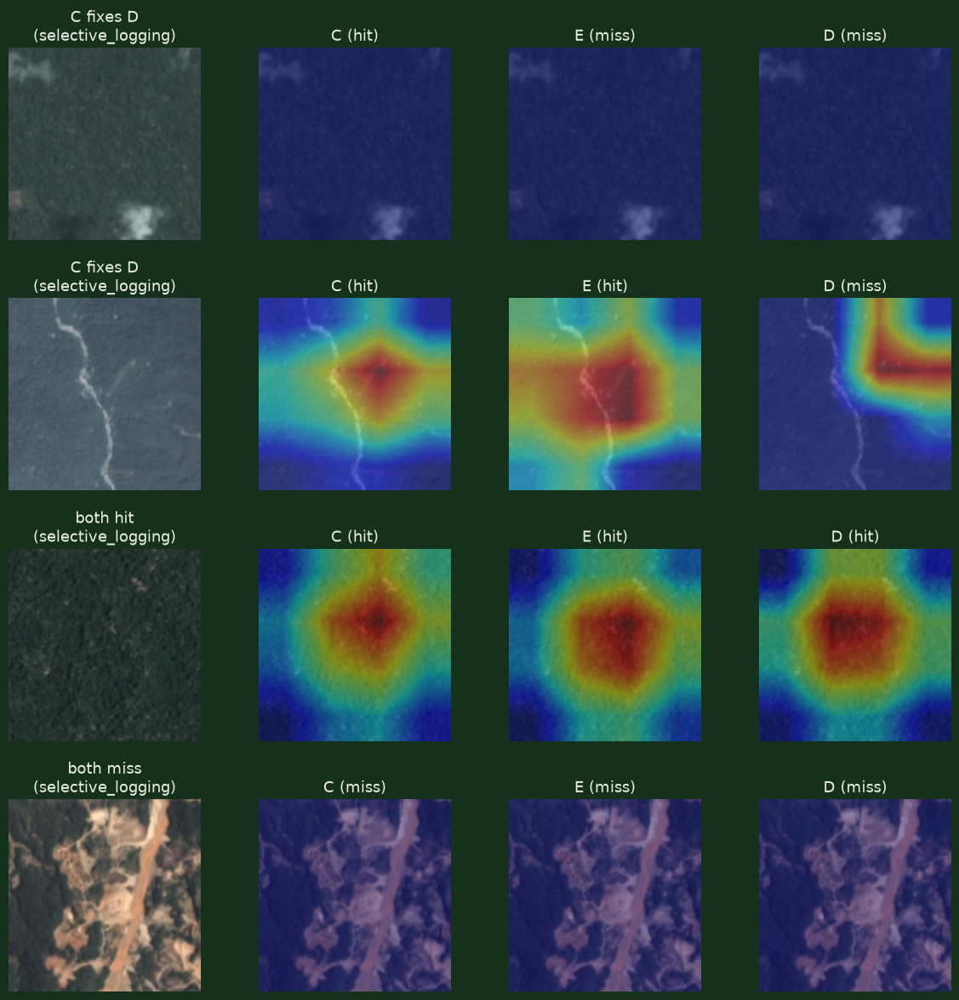

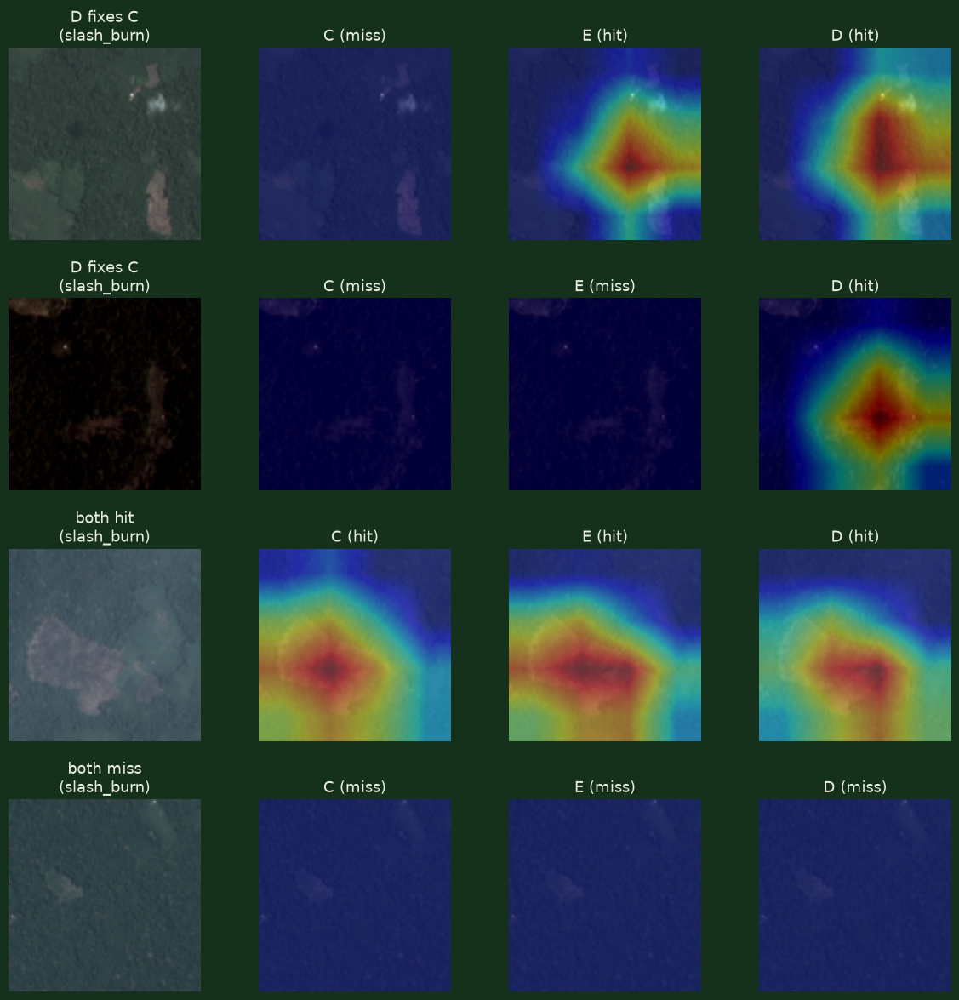

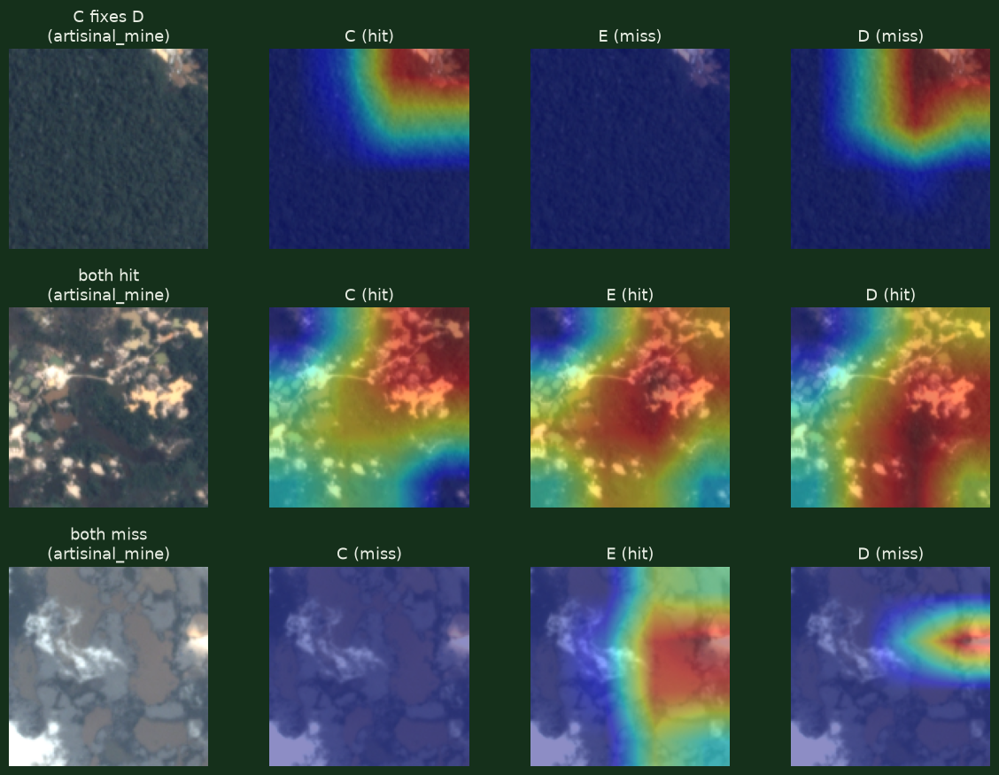

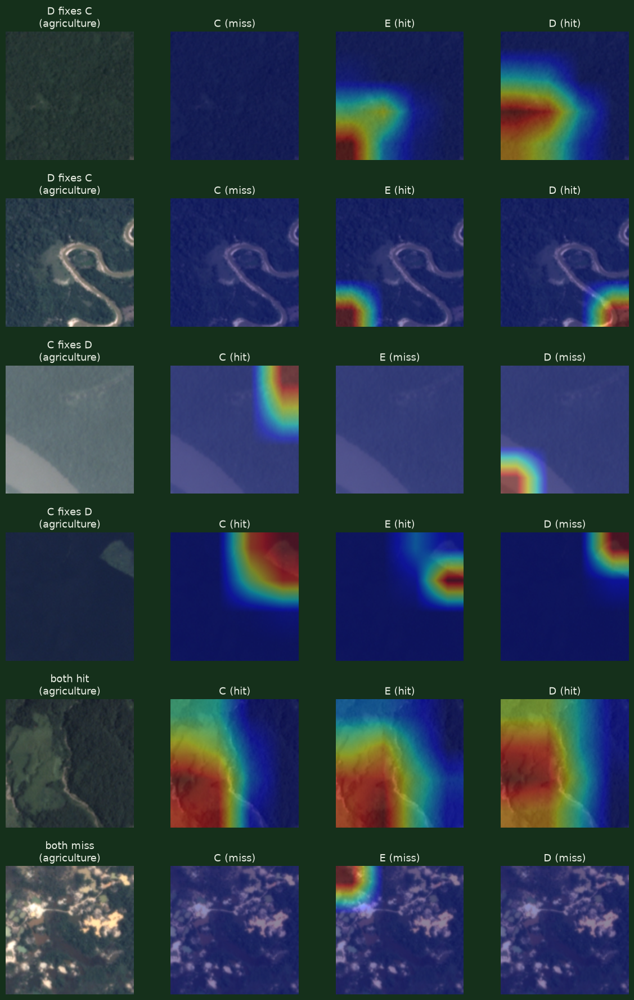

Grad-CAM figures written for: ['C_resnet_rgb', 'D_resnet_nir_ndvi', 'E_resnet_nir']
DONE. Results: /mnt/c/Users/legen/amazon_project_tif/results_to_paste.txt
JSON: /mnt/c/Users/legen/amazon_project_tif/results.json
Figures/CSVs: /mnt/c/Users/legen/amazon_project_tif/figs


In [123]:
# Conditional branch
if makeFigs and expNames:
    # Try block — catch failures below
    try:
        # Create matplotlib figure/axes
        fig, ax = plt.subplots(figsize=(9, 4.5))
        # Set `x` = np.arange(len(expNames))
        x = np.arange(len(expNames))
        # Draw or configure plot elements
        ax.bar(x - 0.2, [res[n]["macro_F2"] for n in expNames], 0.4, label="Macro F2", color="#3FB6A8")
        # Draw or configure plot elements
        ax.bar(x + 0.2, [res[n]["samples_F2 (Kaggle metric)"] for n in expNames], 0.4,
               # Keyword/field `label`
               label="Kaggle-style F2", color="#7EE081")
        # Draw or configure plot elements
        ax.axhline(0.85, color="#FF8A3D", ls="--", label="Target 0.85")
        # Draw or configure plot elements
        ax.set_xticks(x)
        # Draw or configure plot elements
        ax.set_xticklabels([n.split("_", 1)[0] for n in expNames])
        # Draw or configure plot elements
        ax.set_ylim(0, 1)
        # Draw or configure plot elements
        ax.legend()
        # Draw or configure plot elements
        ax.set_title("Test results by experiment")
        # Run this pipeline step
        plt.tight_layout()
        # Save figure PNG for the report/deck
        plt.savefig(f"{figDir}/fig_results.png", dpi=200)
        # Render the figure in the notebook UI
        plt.show()
        # Close figure to release memory
        plt.close()

        # Set `bestN` = max(expNames, key=lambda n: res[n]["macro_F2"])
        bestN = max(expNames, key=lambda n: res[n]["macro_F2"])
        # Set `f2l` = f2_per_label(store[bestN]["y"], store[bestN]["pred"])
        f2l = f2_per_label(store[bestN]["y"], store[bestN]["pred"])
        # Set `order` = np.argsort(f2l)
        order = np.argsort(f2l)
        # Create matplotlib figure/axes
        fig, ax = plt.subplots(figsize=(8, 6))
        # Draw or configure plot elements
        ax.barh([labels[i] for i in order], f2l[order],
                # Keyword/field `color`
                color=["#FF8A3D" if i in rareIdx else "#3FB6A8" for i in order])
        # Draw or configure plot elements
        ax.set_title(f"Per-label F2: {bestN}")
        # Run this pipeline step
        plt.tight_layout()
        # Save figure PNG for the report/deck
        plt.savefig(f"{figDir}/fig_per_label_f2.png", dpi=200)
        # Render the figure in the notebook UI
        plt.show()
        # Close figure to release memory
        plt.close()

        # Conditional branch
        if rareNames:
            # Create matplotlib figure/axes
            fig, axes = plt.subplots(1, len(rareNames), figsize=(4 * len(rareNames), 3.6), squeeze=False)
            # Iterate over this sequence
            for ax, l in zip(axes[0], rareNames):
                # Set `j` = labels.index(l)
                j = labels.index(l)
                # Iterate over this sequence
                for n in expNames:
                    # Set `p_, r_, _` = precision_recall_curve(store[n]["y"][:, j], store[n]["probs"][:, j])
                    p_, r_, _ = precision_recall_curve(store[n]["y"][:, j], store[n]["probs"][:, j])
                    # Draw or configure plot elements
                    ax.plot(r_, p_, label=n.split("_", 1)[0])
                # Draw or configure plot elements
                ax.set_title(l)
                # Draw or configure plot elements
                ax.set_xlabel("recall")
                # Draw or configure plot elements
                ax.set_ylabel("precision")
                # Draw or configure plot elements
                ax.legend()
            # Run this pipeline step
            plt.tight_layout()
            # Save figure PNG for the report/deck
            plt.savefig(f"{figDir}/fig_pr_rare.png", dpi=200)
            # Render the figure in the notebook UI
            plt.show()
            # Close figure to release memory
            plt.close()

        # Conditional branch
        if len(wx):
            # Set `werr.pivot(index` = "weather", columns="model", values="mean_label_error").loc[wx].plot.ba…
            werr.pivot(index="weather", columns="model", values="mean_label_error").loc[wx].plot.bar(figsize=(8, 4))
            # Run this pipeline step
            plt.ylabel("share of the 17 labels predicted wrong")
            # Set `plt.xticks(rotation` = 0)
            plt.xticks(rotation=0)
            # Run this pipeline step
            plt.tight_layout()
            # Save figure PNG for the report/deck
            plt.savefig(f"{figDir}/fig_error_by_weather.png", dpi=200)
            # Render the figure in the notebook UI
            plt.show()
            # Close figure to release memory
            plt.close()

        # Set `cms` = multilabel_confusion_matrix(store[bestN]["y"], store[bestN]["pred"].as…
        cms = multilabel_confusion_matrix(store[bestN]["y"], store[bestN]["pred"].astype(int))
        # Create matplotlib figure/axes
        fig, axes = plt.subplots(3, 6, figsize=(15, 7.5))
        # Iterate over this sequence
        for a in axes.ravel():
            # Run this pipeline step
            a.axis("off")
        # Iterate over this sequence
        for j, a in enumerate(axes.ravel()[:nLabels]):
            # Run this pipeline step
            a.axis("on")
            # Set `a.imshow(cms[j], cmap` = "Greens")
            a.imshow(cms[j], cmap="Greens")
            # Iterate over this sequence
            for (r_, c_), v in np.ndenumerate(cms[j]):
                # Set `a.text(c_, r_, int(v), ha` = "center", va="center", fontsize=9)
                a.text(c_, r_, int(v), ha="center", va="center", fontsize=9)
            # Set `a.set_title(labels[j], fontsize` = 9)
            a.set_title(labels[j], fontsize=9)
        # Run this pipeline step
        plt.tight_layout()
        # Save figure PNG for the report/deck
        plt.savefig(f"{figDir}/fig_confusion_matrices.png", dpi=200)
        # Render the figure in the notebook UI
        plt.show()
        # Close figure to release memory
        plt.close()
    # Handle exception from the try block
    except Exception as e:
        # Print status / metrics to the notebook
        say("Figure step skipped:", repr(e))

    # Try block — catch failures below
    try:
        # Create matplotlib figure/axes
        fig, ax = plt.subplots(1, 2, figsize=(12, 4))
        # Iterate over this sequence
        for n in expNames:
            # Set `hp` = f"{runs}/{n}_history.json"
            hp = f"{runs}/{n}_history.json"
            # Conditional branch
            if os.path.exists(hp):
                # Load JSON metadata from disk
                h = json.load(open(hp))
                # Set `ax[0].plot([e["train_loss"] for e in h], label` = n.split("_", 1)[0])
                ax[0].plot([e["train_loss"] for e in h], label=n.split("_", 1)[0])
                # Set `ax[1].plot([e["val_macro_f2_at_0_2"] for e in h], label` = n.split("_", 1)[0])
                ax[1].plot([e["val_macro_f2_at_0_2"] for e in h], label=n.split("_", 1)[0])
        # Run this pipeline step
        ax[0].set_title("Training loss")
        # Run this pipeline step
        ax[1].set_title("Validation macro F2 (threshold 0.2)")
        # Iterate over this sequence
        for a in ax:
            # Run this pipeline step
            a.set_xlabel("epoch")
            # Run this pipeline step
            a.legend()
        # Run this pipeline step
        plt.tight_layout()
        # Save figure PNG for the report/deck
        plt.savefig(f"{figDir}/fig_curves_all.png", dpi=200)
        # Render the figure in the notebook UI
        plt.show()
        # Close figure to release memory
        plt.close()
    # Handle exception from the try block
    except Exception as e:
        # Print status / metrics to the notebook
        say("Curve figure skipped:", repr(e))

    # Try block — catch failures below
    try:
        # Conditional branch
        if "build_resnet" not in globals():
            # Define function `build_resnet`
            def build_resnet(cIn):
                # Set `m` = torchvision.models.resnet34(weights=None)
                m = torchvision.models.resnet34(weights=None)
                # Set `m.conv1` = nn.Conv2d(cIn, 64, 7, 2, 3, bias=False)
                m.conv1 = nn.Conv2d(cIn, 64, 7, 2, 3, bias=False)
                # Set `m.fc` = nn.Linear(m.fc.in_features, nLabels)
                m.fc = nn.Linear(m.fc.in_features, nLabels)
                # Return result to caller
                return m
        # Conditional branch
        if "gradcam" not in globals():
            # Define function `gradcam`
            def gradcam(model, x, labelJ):
                # Set `acts, grads` = [], []
                acts, grads = [], []
                # Define function `save_act`
                def save_act(mod, inp, out):
                    # Run this pipeline step
                    acts.append(out)
                    # Run this pipeline step
                    out.register_hook(lambda g: grads.append(g))
                # Set `h` = model.layer4.register_forward_hook(save_act)
                h = model.layer4.register_forward_hook(save_act)
                # Reset gradients before the next step
                model.zero_grad()
                # Set `out` = model(x)
                out = model(x)
                # Backpropagate loss gradients
                out[0, labelJ].backward()
                # Run this pipeline step
                h.remove()
                # Set `w` = grads[0].mean((2, 3), keepdim=True)
                w = grads[0].mean((2, 3), keepdim=True)
                # Set `cam` = F.relu((w * acts[0]).sum(1, keepdim=True))
                cam = F.relu((w * acts[0]).sum(1, keepdim=True))
                # Set `cam` = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=F…
                cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
                # Set `cam` = cam - cam.min()
                cam = cam - cam.min()
                # Return result to caller
                return (cam / (cam.max() + 1e-8)).detach().cpu().numpy()
        # Set `expChans` = {EXPS[k][0]: EXPS[k][1]["chans"] for k in EXPS if EXPS[k][1]["arch"] =…
        expChans = {EXPS[k][0]: EXPS[k][1]["chans"] for k in EXPS if EXPS[k][1]["arch"] == "resnet"}
        # Set `expChans` = {n: c for n, c in expChans.items()
        expChans = {n: c for n, c in expChans.items()
                    # Continuation of the multi-line expression
                    if n in store and os.path.exists(f"{runs}/{n}.pt")}
        # Conditional branch
        if not expChans:
            # Stop with an error when setup/data is invalid
            raise RuntimeError("no ResNet checkpoints in TIF runs/")
        # Conditional branch
        if "prep" not in globals():
            # Define function `prep`
            def prep(gi, n):
                # Set `ch` = expChans[n]
                ch = expChans[n]
                # Set `x` = torch.from_numpy(np.asarray(xAll[gi])[ch].astype(np.float32))[None].to…
                x = torch.from_numpy(np.asarray(xAll[gi])[ch].astype(np.float32))[None].to(device)
                # Set `mean` = torch.tensor(chanMean[ch], device=device).view(1, -1, 1, 1).float()
                mean = torch.tensor(chanMean[ch], device=device).view(1, -1, 1, 1).float()
                # Set `std` = torch.tensor(chanStd[ch], device=device).view(1, -1, 1, 1).float()
                std = torch.tensor(chanStd[ch], device=device).view(1, -1, 1, 1).float()
                # Return result to caller
                return (x - mean) / std

        # Set `nets` = {}
        nets = {}
        # Iterate over this sequence
        for n, ch in expChans.items():
            # Set `m` = build_resnet(len(ch))
            m = build_resnet(len(ch))
            # Try block — catch failures below
            try:
                # Set `state` = torch.load(f"{runs}/{n}.pt", map_location="cpu", weights_only=True)
                state = torch.load(f"{runs}/{n}.pt", map_location="cpu", weights_only=True)
            # Handle exception from the try block
            except TypeError:
                # Set `state` = torch.load(f"{runs}/{n}.pt", map_location="cpu")
                state = torch.load(f"{runs}/{n}.pt", map_location="cpu")
            # Run this pipeline step
            m.load_state_dict(state)
            # Set `nets[n]` = m.to(device).eval()
            nets[n] = m.to(device).eval()

        # Define function `rgb_tile`
        def rgb_tile(gi):
            # Return result to caller
            return np.clip(np.transpose(np.asarray(xAll[gi])[:3].astype(np.float32), (1, 2, 0)) ** 0.8, 0, 1)

        # Define function `panel`
        def panel(picks, modelNames, lab, fname):
            # Conditional branch
            if not picks:
                # Run this pipeline step
                return
            # Create matplotlib figure/axes
            fig, axes = plt.subplots(
                # Continuation of the multi-line expression
                len(picks), 1 + len(modelNames),
                # Keyword/field `figsize`
                figsize=(3 * (1 + len(modelNames)), 3.0 * len(picks)), squeeze=False)
            # Set `j` = labels.index(lab)
            j = labels.index(lab)
            # Iterate over this sequence
            for r_, (kind, i) in enumerate(picks):
                # Set `gi` = int(te[i])
                gi = int(te[i])
                # Set `base` = rgb_tile(gi)
                base = rgb_tile(gi)
                # Draw or configure plot elements
                axes[r_][0].imshow(base)
                # Draw or configure plot elements
                axes[r_][0].set_title(f"{kind}\n({lab})", fontsize=13)
                # Iterate over this sequence
                for c_, n in enumerate(modelNames, start=1):
                    # Draw or configure plot elements
                    axes[r_][c_].imshow(base)
                    # Draw or configure plot elements
                    axes[r_][c_].imshow(gradcam(nets[n], prep(gi, n), j), cmap="jet", alpha=0.45)
                    # Set `hitTxt` = "hit" if store[n]["pred"][i, j] else "miss"
                    hitTxt = "hit" if store[n]["pred"][i, j] else "miss"
                    # Draw or configure plot elements
                    axes[r_][c_].set_title(f"{n.split('_', 1)[0]} ({hitTxt})", fontsize=13)
                # Iterate over this sequence
                for a in axes[r_]:
                    # Run this pipeline step
                    a.axis("off")
            # Run this pipeline step
            plt.tight_layout()
            # Save figure PNG for the report/deck
            plt.savefig(f"{figDir}/{fname}", dpi=200)
            # Render the figure in the notebook UI
            plt.show()
            # Close figure to release memory
            plt.close()

        # Set `targetsG` = [l for l in ["selective_logging", "slash_burn", "artisinal_mine", "agr…
        targetsG = [l for l in ["selective_logging", "slash_burn", "artisinal_mine", "agriculture"]
                    # Continuation of the multi-line expression
                    if l in labels]
        # Conditional branch
        if "C_resnet_rgb" in expChans:
            # Set `cD` = store["C_resnet_rgb"]
            cD = store["C_resnet_rgb"]
            # Iterate over this sequence
            for lab in targetsG:
                # Set `j` = labels.index(lab)
                j = labels.index(lab)
                # Set `truth` = cD["y"][:, j] == 1
                truth = cD["y"][:, j] == 1
                # Set `miss` = np.where(truth & ~cD["pred"][:, j])[0][:2]
                miss = np.where(truth & ~cD["pred"][:, j])[0][:2]
                # Set `hit` = np.where(truth & cD["pred"][:, j])[0][:2]
                hit = np.where(truth & cD["pred"][:, j])[0][:2]
                # Run this pipeline step
                panel([("miss", i) for i in miss] + [("hit", i) for i in hit],
                      # Continuation of the multi-line expression
                      ["C_resnet_rgb"], lab, f"fig_gradcam_C_{lab}.png")
        # Conditional branch
        if "C_resnet_rgb" in expChans and "D_resnet_nir_ndvi" in expChans:
            # Set `cD, dD` = store["C_resnet_rgb"], store["D_resnet_nir_ndvi"]
            cD, dD = store["C_resnet_rgb"], store["D_resnet_nir_ndvi"]
            # Set `modelNames` = [n for n in ["C_resnet_rgb", "E_resnet_nir", "D_resnet_nir_ndvi"] if n…
            modelNames = [n for n in ["C_resnet_rgb", "E_resnet_nir", "D_resnet_nir_ndvi"] if n in expChans]
            # Iterate over this sequence
            for lab in targetsG:
                # Set `j` = labels.index(lab)
                j = labels.index(lab)
                # Set `truth` = cD["y"][:, j] == 1
                truth = cD["y"][:, j] == 1
                # Set `cp, dp` = cD["pred"][:, j], dD["pred"][:, j]
                cp, dp = cD["pred"][:, j], dD["pred"][:, j]
                # Set `picks` = (
                picks = (
                    # Dict entry for key `[("D fixes C", i) for i in np.where(truth & ~cp & dp)[0][`
                    [("D fixes C", i) for i in np.where(truth & ~cp & dp)[0][:2]]
                    # Dict entry for key `+ [("C fixes D", i) for i in np.where(truth & cp & ~dp)[0][`
                    + [("C fixes D", i) for i in np.where(truth & cp & ~dp)[0][:2]]
                    # Dict entry for key `+ [("both hit", i) for i in np.where(truth & cp & dp)[0][`
                    + [("both hit", i) for i in np.where(truth & cp & dp)[0][:1]]
                    # Dict entry for key `+ [("both miss", i) for i in np.where(truth & ~cp & ~dp)[0][`
                    + [("both miss", i) for i in np.where(truth & ~cp & ~dp)[0][:1]]
                # Continuation of the multi-line expression
                )
                # Run this pipeline step
                panel(picks, modelNames, lab, f"fig_gradcam_compare_{lab}.png")
        # Print status / metrics to the notebook
        say("Grad-CAM figures written for:", list(expChans))
    # Handle exception from the try block
    except Exception as e:
        # Print status / metrics to the notebook
        say("Grad-CAM step skipped:", repr(e))

# Print status / metrics to the notebook
print(f"DONE. Results: {root}/results_to_paste.txt")
# Print status / metrics to the notebook
print(f"JSON: {root}/results.json")
# Print status / metrics to the notebook
print(f"Figures/CSVs: {figDir}")

In [124]:
# Optional Fix-kit settings (matched TIF packaging)
# Path to the TIF-matched project root (same as matched section / Fix notebook ROOT)
matchedRoot = os.environ.get("AMAZON_ROOT_TIF", os.environ.get("AMAZON_ROOT", "/mnt/c/Users/legen/amazon_project"))
# Path to raw Planet data (train-tif-v2 + CSV)
matchedRaw = os.environ.get("AMAZON_RAW", "/mnt/c/Users/legen/amazon_data")
# If True, delete old B/D checkpoints so they retrain with A/C/E in one fresh 2x2
retrainBd = False

In [125]:
# Environment and data check (from Fix_Matched_Rerun)
# Packages the matched TIF pipeline needs
for pkg in ["torch", "torchvision", "tifffile", "cv2", "sklearn", "pandas", "matplotlib"]:
    # Try the following operations
    try:
        # Try importing the module by name
        importlib.import_module(pkg)
        # Report success for this dependency
        print("ok     ", pkg)
    # Catch import/runtime errors
    except ImportError:
        # Tell the user which pip package to install
        print("MISSING", pkg, "-> install it, e.g.  pip install tifffile  (torch: use your CUDA build)")

# Confirm GPU visibility for training
# Log to notebook output
print("CUDA available:", torch.cuda.is_available(), "|",
      # Continues prior expression: torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU (trainin
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU (training will be very slow)")

# Count TIF files under the raw data root
tifsFix = glob.glob(f"{matchedRaw}/**/*.tif", recursive=True)
# Log to notebook output
print("TIF files found:", len(tifsFix), "(expect 40479)")

# List finished experiment probability files
runsFix = f"{matchedRoot}/runs"
# Log to notebook output
print("Existing runs:", sorted(os.path.basename(p) for p in glob.glob(f"{runsFix}/*_probs.npz")))
# Log to notebook output
print("Cache present:", os.path.exists(f"{matchedRoot}/cache/X.npy"))

ok      torch
ok      torchvision
ok      tifffile
ok      cv2
ok      sklearn
ok      pandas
ok      matplotlib
CUDA available: True | NVIDIA GeForce RTX 5080
TIF files found: 40479 (expect 40479)
Existing runs: ['A_scratch_rgb_probs.npz', 'B_scratch_nir_ndvi_probs.npz', 'C_resnet_rgb_probs.npz', 'D_resnet_nir_ndvi_probs.npz', 'E_resnet_nir_probs.npz']
Cache present: True


In [126]:
# Optional: remove old B/D results so every model is retrained fresh
if retrainBd:
    # Wipe B and D artifacts (weights, probs, thresholds, histories)
    for n in ["B_scratch_nir_ndvi", "D_resnet_nir_ndvi"]:
        # Loop over items
        for p in glob.glob(f"{runsFix}/{n}*") + glob.glob(f"{runsFix}/thresholds_{n}.json"):
            # Delete one checkpoint/result file
            os.remove(p)
            # Log to notebook output
            print("removed", p)
# Else branch
else:
    # Log to notebook output
    print("retrainBd=False — keeping existing B/D runs (matched section will skip them if present)")

retrainBd=False — keeping existing B/D runs (matched section will skip them if present)


Tiles with a TIF: 40479 | labels: 17
Reusing TIF cache at /mnt/c/Users/legen/amazon_project_tif/cache
train/val/test: 28335 6072 6072
Experiments evaluated: {'A_scratch_rgb': 'TIF run', 'B_scratch_nir_ndvi': 'TIF run', 'C_resnet_rgb': 'TIF run', 'D_resnet_nir_ndvi': 'TIF run', 'E_resnet_nir': 'TIF run'}

===== RESULTS TABLE (test set) =====
                    macro_F2  samples_F2 (Kaggle metric)  micro_F2  hamming_loss  rare_recall_mean  recall_artisinal_mine  recall_conventional_mine  recall_selective_logging  recall_slash_burn
A_scratch_rgb         0.6877                      0.9023    0.8902        0.0678            0.6835                 0.7843                    0.7333                    0.7647             0.4516
B_scratch_nir_ndvi    0.6733                      0.9028    0.8922        0.0665            0.6556                 0.8431                    0.6667                    0.7255             0.3871
C_resnet_rgb          0.6955                      0.9106    0.9011        0.06

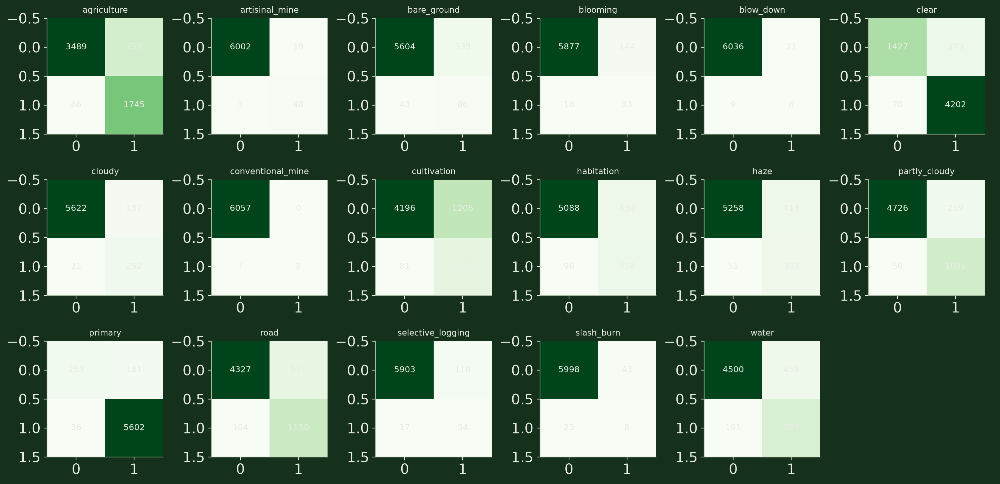

fig_curves_A_scratch_rgb.png


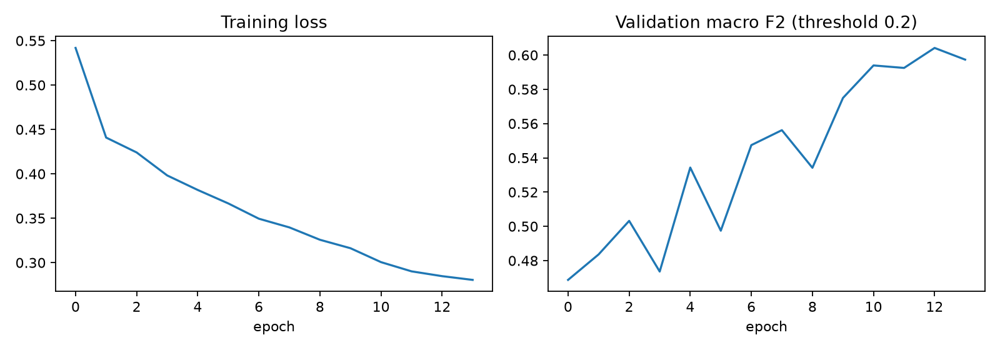

fig_curves_C_resnet_rgb.png


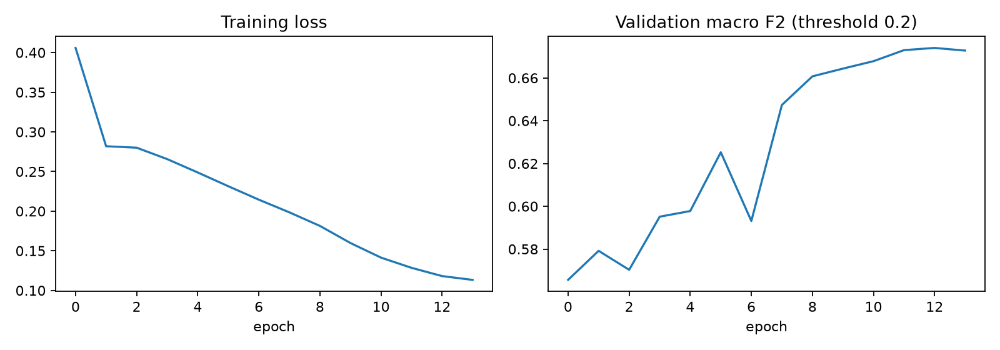

fig_curves_E_resnet_nir.png


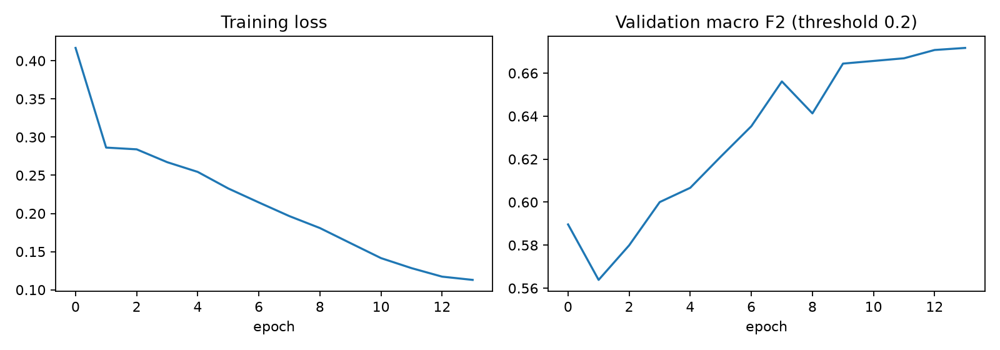

fig_curves_all.png


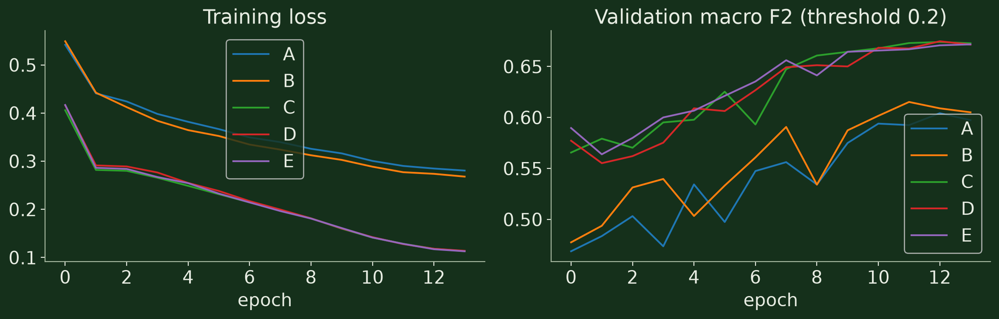

fig_error_by_weather.png


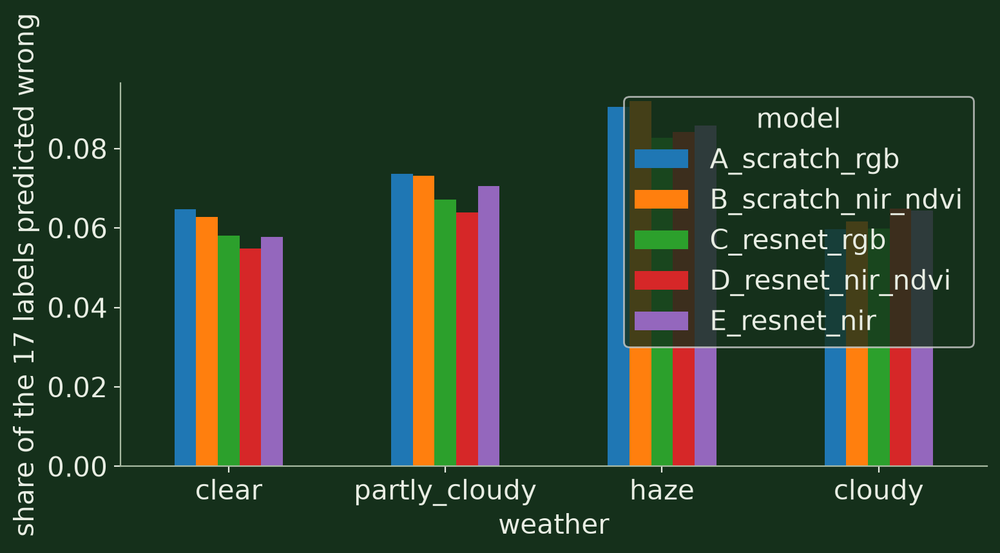

fig_gradcam_C_agriculture.png


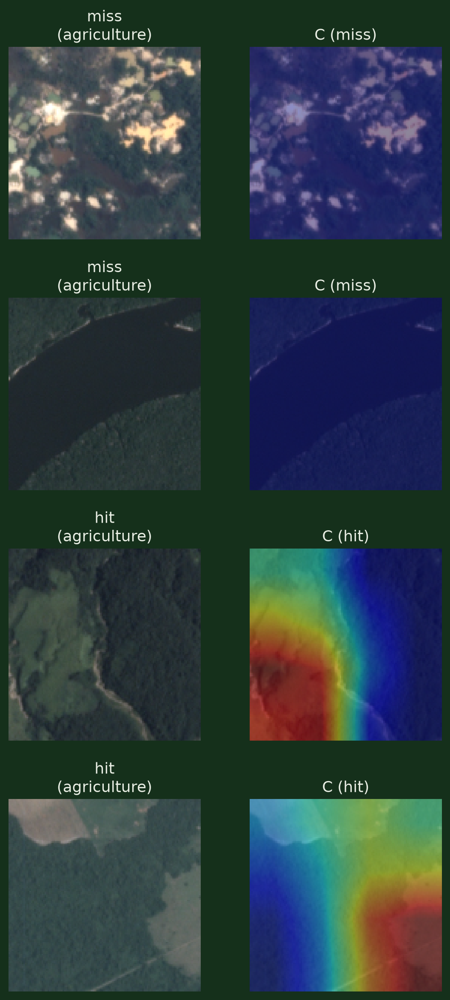

fig_gradcam_C_artisinal_mine.png


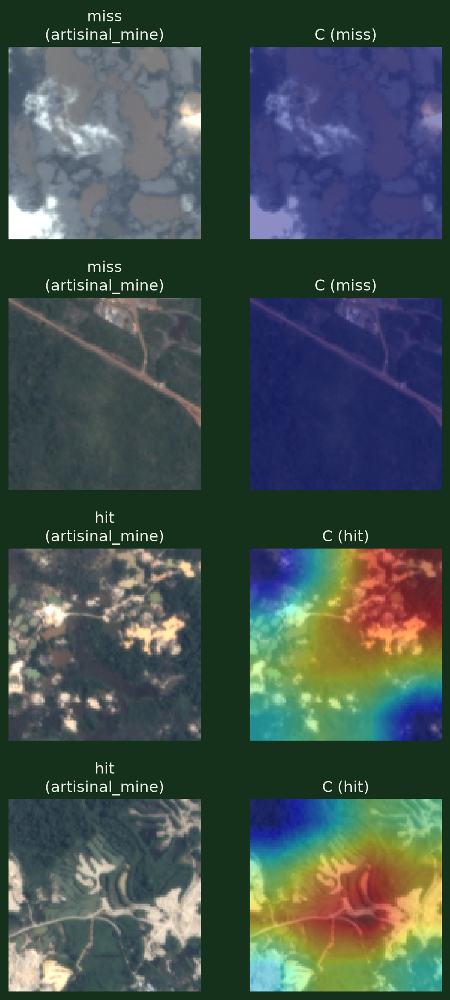

fig_gradcam_C_selective_logging.png


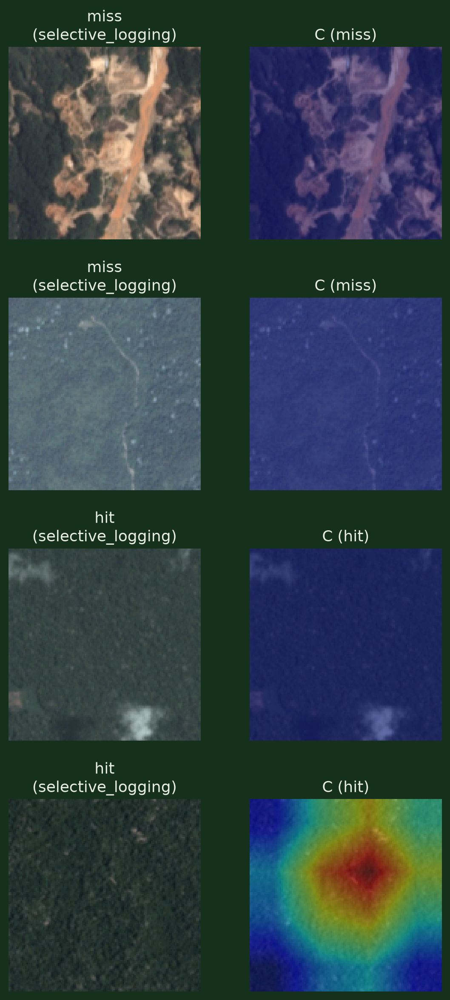

fig_gradcam_C_slash_burn.png


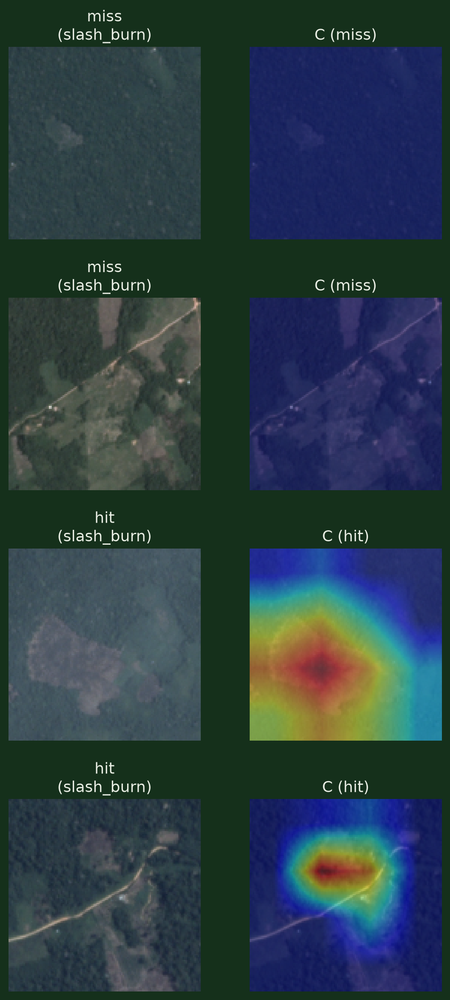

fig_gradcam_compare_agriculture.png


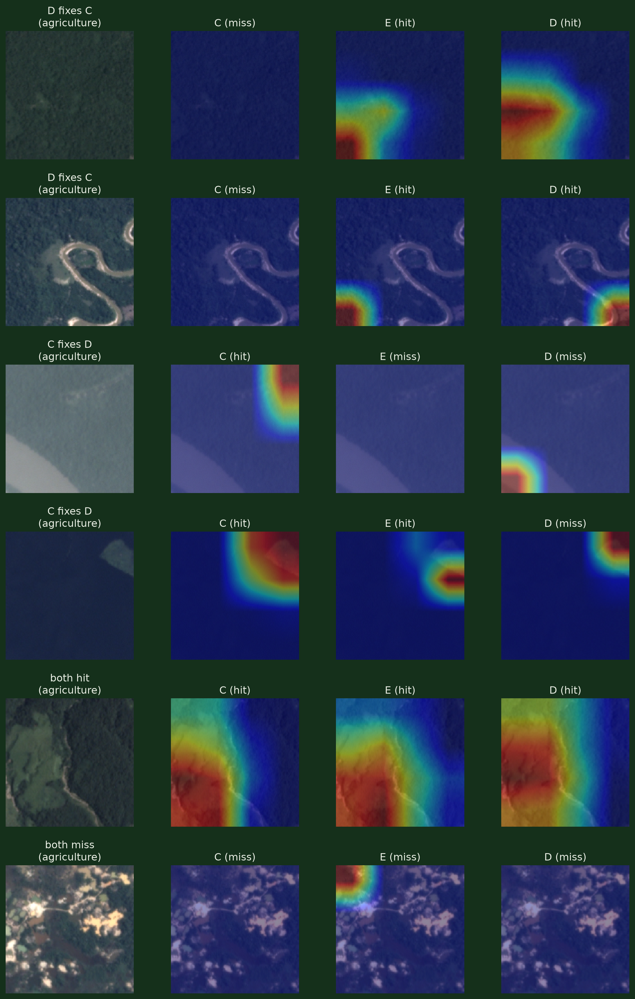

fig_gradcam_compare_artisinal_mine.png


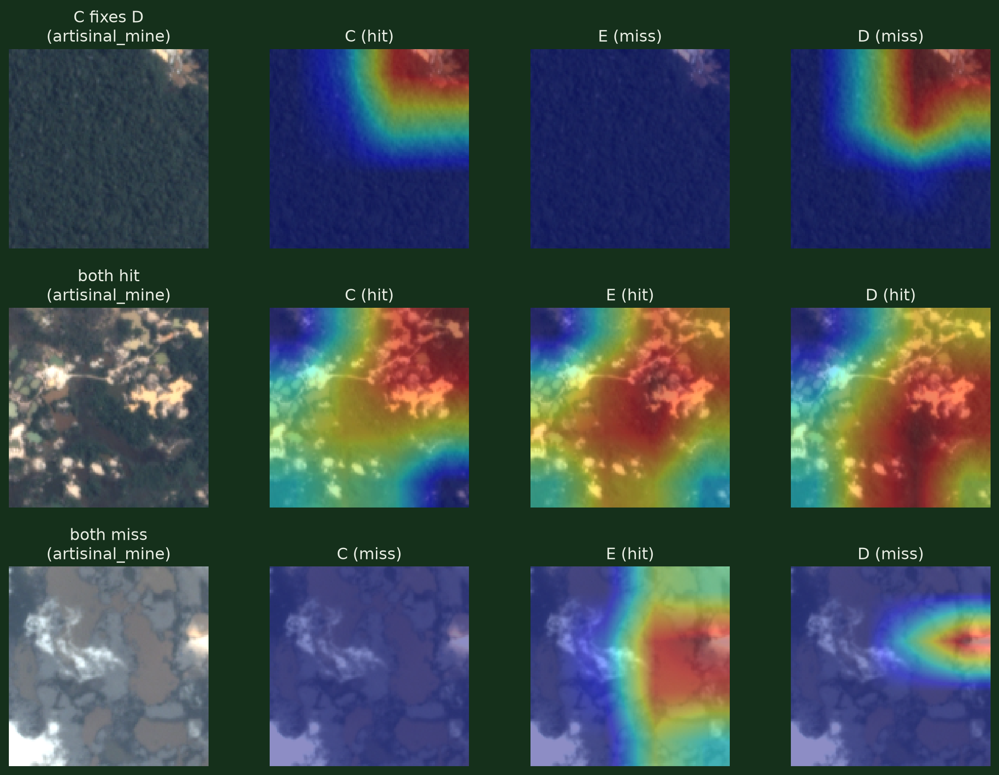

fig_gradcam_compare_selective_logging.png


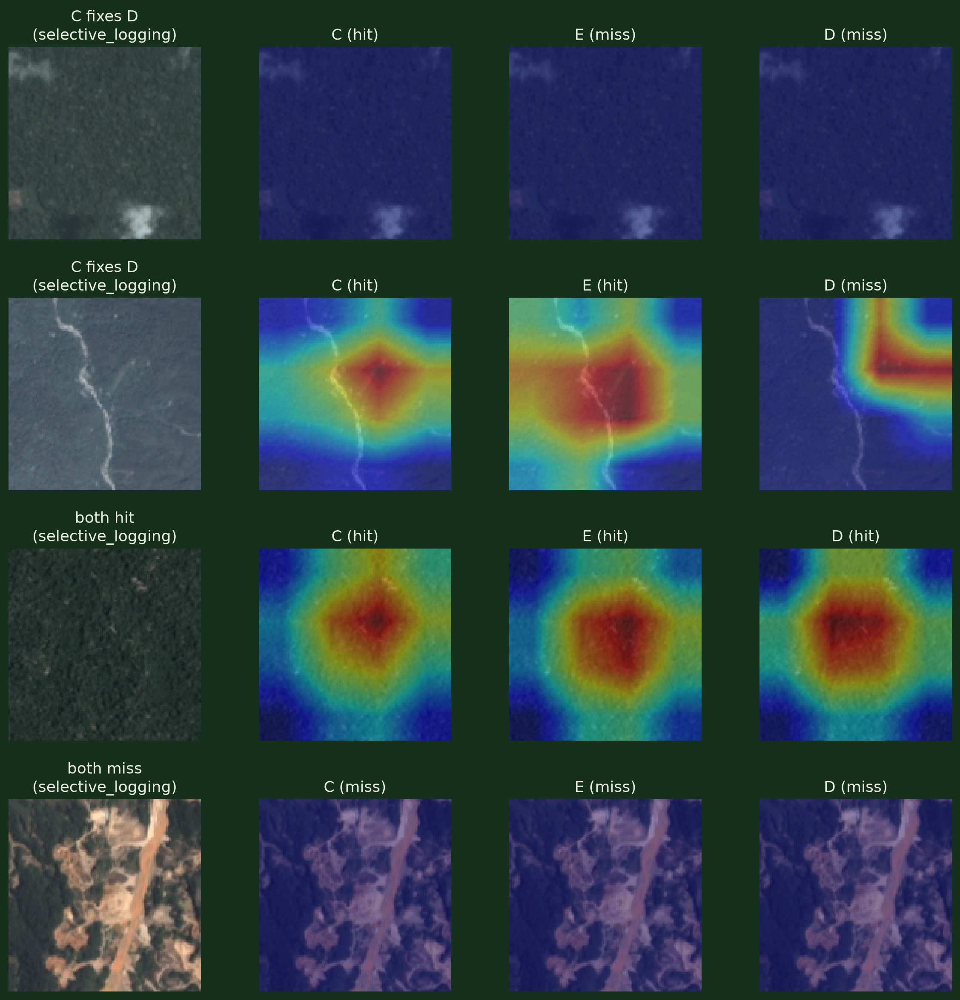

fig_gradcam_compare_slash_burn.png


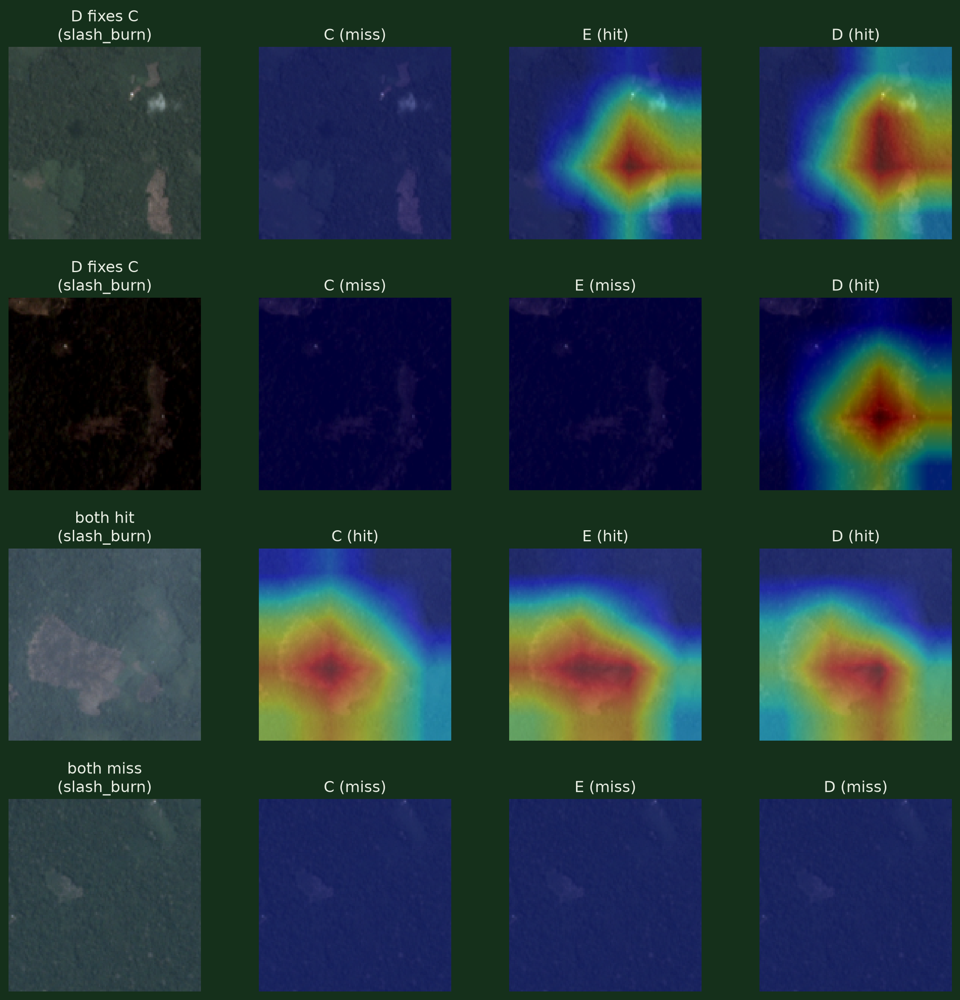

fig_per_label_f2.png


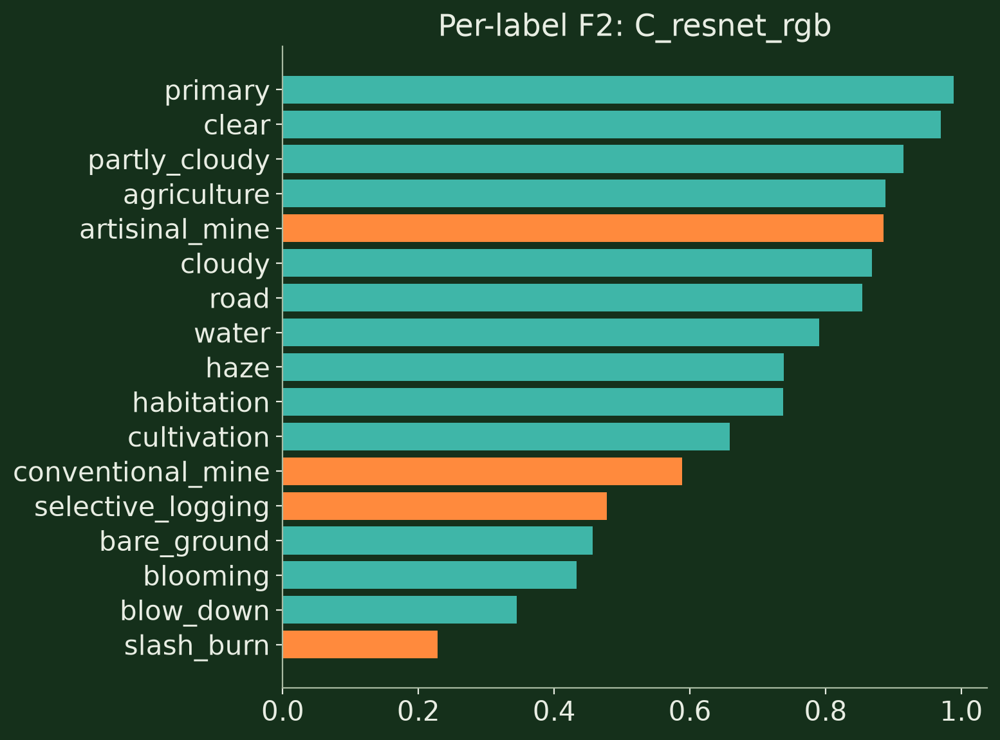

fig_pr_rare.png


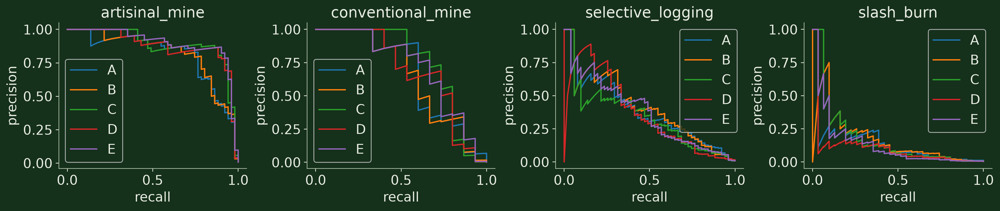

fig_results.png


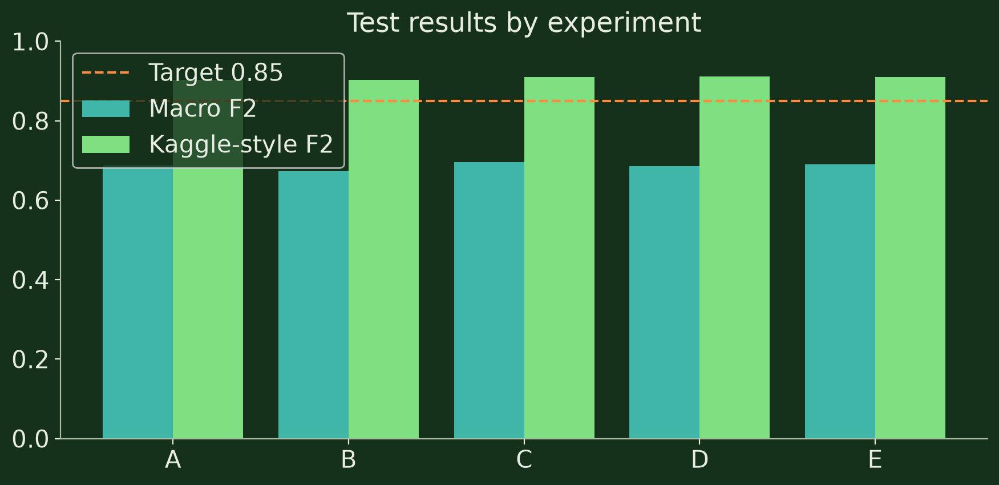

In [127]:
# Show matched figures and results_to_paste.txt (Fix kit step 5)
from IPython.display import Image, display  # inline image display in Jupyter

# Path to the human-readable results dump written by the matched section / run_matched.py
pastePath = f"{matchedRoot}/results_to_paste.txt"
# If-branch
if os.path.exists(pastePath):
    # Read the full paste file
    txt = open(pastePath).read()
    # Warn if this still looks like a JPG-reuse run (comparisons would be contaminated)
    if "reused from your JPG" in txt or "JPG notebook run" in txt:
        # Log to notebook output
        print("WARNING: results still look like a JPG-reuse run. Re-run matched TIF A/C/E without allowJpgReuse.")
    # Log to notebook output
    print(txt)
# Else branch
else:
    # Log to notebook output
    print("No results_to_paste.txt yet — run the matched TIF section first.")

# Display every fig_*.png produced by the matched evaluation
figsFix = sorted(glob.glob(f"{matchedRoot}/figs/fig_*.png"))
# Loop over items
for f in figsFix:
    # Log to notebook output
    print(os.path.basename(f))
    # Show rich output in Jupyter
    display(Image(filename=f, width=900))

In [128]:
# Package matched results into a zip for the deck (Fix kit step 6)
import zipfile  # stdlib zip writer

# Output zip path next to the matched project root
zipOut = f"{matchedRoot}/matched_results_for_deck.zip"
# Open context manager
with zipfile.ZipFile(zipOut, "w", zipfile.ZIP_DEFLATED) as z:
    # Files to include: paste text, JSON summary, and all figures
    for f in [f"{matchedRoot}/results_to_paste.txt", f"{matchedRoot}/results.json"] + glob.glob(f"{matchedRoot}/figs/*"):
        # If-branch
        if os.path.exists(f):
            # Store each file with a path relative to matchedRoot
            z.write(f, os.path.relpath(f, matchedRoot))
# Log to notebook output
print("Send this file back:", zipOut, f"({os.path.getsize(zipOut)/1e6:.1f} MB)" if os.path.exists(zipOut) else "")

Send this file back: /mnt/c/Users/legen/amazon_project_tif/matched_results_for_deck.zip (5.2 MB)


In [129]:
# Dual 128+256 cache build (local, adapted from 01_Build_Caches_Colab)
# Writes both caches in one pass over the TIFs so splits/band scaling match.
# Paths: AMAZON_RAW (TIFs+CSV), AMAZON_ROOT_TIF or AMAZON_ROOT (128), AMAZON_ROOT_256 (256).
# Default env path if unset
os.environ.setdefault("AMAZON_RAW", "/mnt/c/Users/legen/amazon_data")
# Default env path if unset
os.environ.setdefault("AMAZON_ROOT", "/mnt/c/Users/legen/amazon_project")
# Default env path if unset
os.environ.setdefault("AMAZON_ROOT_TIF", "/mnt/c/Users/legen/amazon_project_tif")
# Default env path if unset
os.environ.setdefault("AMAZON_ROOT_256", "/mnt/c/Users/legen/amazon_project_tif_256")

# Set `cacheRaw` = os.environ["AMAZON_RAW"]
cacheRaw = os.environ["AMAZON_RAW"]
# Set `cacheRoot128` = os.environ.get("AMAZON_ROOT_TIF", os.environ["AMAZON_ROOT"])
cacheRoot128 = os.environ.get("AMAZON_ROOT_TIF", os.environ["AMAZON_ROOT"])
# Set `cacheRoot256` = os.environ["AMAZON_ROOT_256"]
cacheRoot256 = os.environ["AMAZON_ROOT_256"]
# Set True once when TIFs exist and you need (re)built caches; False keeps Run-All safe
runCacheBuild = False
# Set `leakFree` = True
leakFree = True
# Set `rgbOnly256` = False
rgbOnly256 = False
# Set `cacheThreads` = 8
cacheThreads = 8

# Print status / metrics to the notebook
print("RAW:", cacheRaw)
# Print status / metrics to the notebook
print("ROOT128:", cacheRoot128)
# Print status / metrics to the notebook
print("ROOT256:", cacheRoot256)
# Print status / metrics to the notebook
print("runCacheBuild=", runCacheBuild, "| leakFree=", leakFree)

RAW: /mnt/c/Users/legen/amazon_data
ROOT128: /mnt/c/Users/legen/amazon_project_tif
ROOT256: /mnt/c/Users/legen/amazon_project_tif_256
runCacheBuild= False | leakFree= True


In [130]:
# Build 128 px and 256 px caches in one TIF pass (skip unless runCacheBuild)

# Define function `build_dual_caches`
def build_dual_caches(rawDir, root128, root256, leakFree=True, rgbOnly256=False, threads=8, seed=42):
    # Find TIFs and label CSV (isfile filter kept intact)
    tifs = sorted(glob.glob(f"{rawDir}/**/*.tif", recursive=True))
    # Set `csvs` = [p for p in glob.glob(f"{rawDir}/**/train_v2.csv", recurs...
    csvs = [p for p in glob.glob(f"{rawDir}/**/train_v2.csv", recursive=True) if os.path.isfile(p)]
    # Conditional branch
    if len(tifs) < 100 or not csvs:
        # Stop with an error when setup/data is invalid
        raise FileNotFoundError(
            # Continuation of the multi-line expression
            f"Found {len(tifs)} TIFs and {len(csvs)} train_v2.csv under {rawDir}. Unpack data first.")
    # Set `tifDir` = os.path.dirname(tifs[0])
    tifDir = os.path.dirname(tifs[0])
    # Set `df` = pd.read_csv(csvs[0])
    df = pd.read_csv(csvs[0])
    # Keep only rows whose TIF is actually on disk
    df = df[df["image_name"].map(lambda n: os.path.exists(os.path.join(tifDir, n + ".tif")))].reset_index(drop=True)

    # Set `tagLists` = df["tags"].str.split()
    tagLists = df["tags"].str.split()
    # Set `labels` = sorted({t for tl in tagLists for t in tl})
    labels = sorted({t for tl in tagLists for t in tl})
    # Set `y` = np.zeros((len(df), len(labels)), dtype=np.uint8)
    y = np.zeros((len(df), len(labels)), dtype=np.uint8)
    # Iterate over this sequence
    for i, tl in enumerate(tagLists):
        # Iterate over this sequence
        for t in tl:
            # Run this pipeline step
            y[i, labels.index(t)] = 1
    # Set `names` = df["image_name"].tolist()
    names = df["image_name"].tolist()
    # Set `nTiles` = len(names)
    nTiles = len(names)
    # Print status / metrics to the notebook
    print(f"{nTiles} chips with a TIF, {len(labels)} labels")

    # Define function `read_tif`
    def read_tif(n):
        # Set `a` = tifffile.imread(os.path.join(tifDir, n + ".tif")).astype(...
        a = tifffile.imread(os.path.join(tifDir, n + ".tif")).astype(np.float32)
        # Conditional branch
        if a.ndim == 3 and a.shape[0] == 4 and a.shape[-1] != 4:
            # Set `a` = np.transpose(a, (1, 2, 0))
            a = np.transpose(a, (1, 2, 0))
        # Return result to caller
        return a

    # Stratified 70/15/15 split (same seed / rarest-label strata as matched pipeline)
    freq = y.sum(0)
    # Set `strata` = np.array([min(np.where(row == 1)[0], key=lambda j: freq[j...
    strata = np.array([min(np.where(row == 1)[0], key=lambda j: freq[j]) for row in y])
    # Set `idx` = np.arange(nTiles)
    idx = np.arange(nTiles)
    # Set `tr, tmp` = train_test_split(idx, test_size=0.30, stratify=strata, ra...
    tr, tmp = train_test_split(idx, test_size=0.30, stratify=strata, random_state=seed)
    # Set `va, te` = train_test_split(tmp, test_size=0.50, stratify=strata[tmp...
    va, te = train_test_split(tmp, test_size=0.50, stratify=strata[tmp], random_state=seed)

    # Define function `band_stats`
    def band_stats(sampleIdx):
        # Set `raw` = np.stack([read_tif(names[i]) for i in sampleIdx])
        raw = np.stack([read_tif(names[i]) for i in sampleIdx])
        # Set `ys` = y[sampleIdx]
        ys = y[sampleIdx]
        # Set `prim` = ys[:, labels.index("primary")] == 1
        prim = ys[:, labels.index("primary")] == 1
        # Set `open_` = (ys[:, labels.index("agriculture")] == 1) | (ys[:, labels...
        open_ = (ys[:, labels.index("agriculture")] == 1) | (ys[:, labels.index("bare_ground")] == 1)
        # Set `prim, open_` = prim & ~open_, open_ & ~prim
        prim, open_ = prim & ~open_, open_ & ~prim
        # Set `tileMean` = raw.reshape(len(sampleIdx), -1, 4).mean(1)
        tileMean = raw.reshape(len(sampleIdx), -1, 4).mean(1)
        # Set `ratio` = tileMean[open_].mean(0) / tileMean[prim].mean(0)
        ratio = tileMean[open_].mean(0) / tileMean[prim].mean(0)
        # Set `order` = "RGBN" if ratio[0] > 1.15 * ratio[2] else "BGRN"
        order = "RGBN" if ratio[0] > 1.15 * ratio[2] else "BGRN"
        # Return result to caller
        return order, np.percentile(raw.reshape(-1, 4), 1, axis=0), np.percentile(raw.reshape(-1, 4), 99, axis=0)

    # Set `rng` = np.random.RandomState(seed)
    rng = np.random.RandomState(seed)
    # Set `sampAll` = rng.choice(nTiles, min(600, nTiles), replace=False)
    sampAll = rng.choice(nTiles, min(600, nTiles), replace=False)
    # Set `orderAll, loAll, hiAll` = band_stats(sampAll)
    orderAll, loAll, hiAll = band_stats(sampAll)
    # Conditional branch
    if leakFree:
        # Set `sampTr` = np.random.RandomState(seed + 1).choice(tr, min(600, len(t...
        sampTr = np.random.RandomState(seed + 1).choice(tr, min(600, len(tr)), replace=False)
        # Set `bandOrder, lo, hi` = band_stats(sampTr)
        bandOrder, lo, hi = band_stats(sampTr)
        # Set `rel` = np.abs(np.concatenate([lo - loAll, hi - hiAll])) / (np.co...
        rel = np.abs(np.concatenate([lo - loAll, hi - hiAll])) / (np.concatenate([hiAll - loAll] * 2) + 1e-6)
        # Print status / metrics to the notebook
        print(f"Leak-free bounds differ from all-data by at most {rel.max():.2%} "
              # Continuation of the multi-line expression
              f"(band order: {bandOrder} vs {orderAll})")
    # Else branch
    else:
        # Set `bandOrder, lo, hi` = orderAll, loAll, hiAll
        bandOrder, lo, hi = orderAll, loAll, hiAll
    # Set `bandMap` = {"BGRN": dict(b=0, g=1, r=2, nir=3), "RGBN": dict(b=2, g=...
    bandMap = {"BGRN": dict(b=0, g=1, r=2, nir=3), "RGBN": dict(b=2, g=1, r=0, nir=3)}[bandOrder]
    # Print status / metrics to the notebook
    print("Band order:", bandOrder, "| bounds from", "training only" if leakFree else "all chips")

    # Set `caches` = {128: os.path.join(root128, "cache"), 256: os.path.join(r...
    caches = {128: os.path.join(root128, "cache"), 256: os.path.join(root256, "cache")}
    # Set `nCh` = {128: 5, 256: 3 if rgbOnly256 else 5}
    nCh = {128: 5, 256: 3 if rgbOnly256 else 5}
    # Set `chanNames` = ["R", "G", "B", "NIR", "NDVI"]
    chanNames = ["R", "G", "B", "NIR", "NDVI"]
    # Iterate over this sequence
    for size, c in caches.items():
        # Ensure output directory exists
        os.makedirs(c, exist_ok=True)
        # Ensure output directory exists
        os.makedirs(os.path.join(os.path.dirname(c), "runs"), exist_ok=True)
        # Ensure output directory exists
        os.makedirs(os.path.join(os.path.dirname(c), "figs"), exist_ok=True)
    # Set `X` = {size: np.lib.format.open_memmap(
    X = {size: np.lib.format.open_memmap(
            # Continuation of the multi-line expression
            os.path.join(c, "X.npy"), mode="w+", dtype=np.float16,
            # Set `shape` = (nTiles, nCh[size], size, size))
            shape=(nTiles, nCh[size], size, size))
         # Iterate over this sequence
         for size, c in caches.items()}

    # Set `t0` = time.time()
    t0 = time.time()

    # Define function `process`
    def process(i):
        # Set `a` = read_tif(names[i])
        a = read_tif(names[i])
        # Set `red, nir` = a[..., bandMap["r"]], a[..., bandMap["nir"]]
        red, nir = a[..., bandMap["r"]], a[..., bandMap["nir"]]
        # Set `ndvi` = (nir - red) / (nir + red + 1e-6)
        ndvi = (nir - red) / (nir + red + 1e-6)
        # Set `chans` = [np.clip((a[..., src] - lo[src]) / (hi[src] - lo[src] + 1...
        chans = [np.clip((a[..., src] - lo[src]) / (hi[src] - lo[src] + 1e-6), 0, 1)
                 # Iterate over this sequence
                 for src in (bandMap["r"], bandMap["g"], bandMap["b"], bandMap["nir"])]
        # Run this pipeline step
        chans.append((np.clip(ndvi, -1, 1) + 1) / 2)
        # Set `full` = np.stack(chans, -1).astype(np.float32)
        full = np.stack(chans, -1).astype(np.float32)
        # Conditional branch
        if full.shape[0] != 256 or full.shape[1] != 256:
            # Set `full` = cv2.resize(full, (256, 256), interpolation=cv2.INTER_AREA)
            full = cv2.resize(full, (256, 256), interpolation=cv2.INTER_AREA)
        # Run this pipeline step
        X[256][i] = np.transpose(full[..., :nCh[256]], (2, 0, 1)).astype(np.float16)
        # Set `small` = cv2.resize(full, (128, 128), interpolation=cv2.INTER_AREA)
        small = cv2.resize(full, (128, 128), interpolation=cv2.INTER_AREA)
        # Run this pipeline step
        X[128][i] = np.transpose(small, (2, 0, 1)).astype(np.float16)

    # Open context manager
    with ThreadPoolExecutor(threads) as ex:
        # Iterate over this sequence
        for k, _ in enumerate(ex.map(process, range(nTiles))):
            # Conditional branch
            if k % 2000 == 0:
                # Print status / metrics to the notebook
                print(f"  {k}/{nTiles} chips  [{time.time() - t0:.0f}s]")
    # Iterate over this sequence
    for m in X.values():
        # Run this pipeline step
        m.flush()

    # Set `pick` = np.sort(rng.choice(np.sort(tr), min(3000, len(tr)), repla...
    pick = np.sort(rng.choice(np.sort(tr), min(3000, len(tr)), replace=False))
    # Iterate over this sequence
    for size, c in caches.items():
        # Persist NumPy array(s) to the cache
        np.save(os.path.join(c, "Y.npy"), y)
        # Persist JSON metadata to the cache
        json.dump(labels, open(os.path.join(c, "labels.json"), "w"))
        # Persist JSON metadata to the cache
        json.dump(names, open(os.path.join(c, "names.json"), "w"))
        # Persist JSON metadata to the cache
        json.dump({"order": bandOrder, **bandMap}, open(os.path.join(c, "order.json"), "w"))
        # Persist JSON metadata to the cache
        json.dump({"lo": lo.tolist(), "hi": hi.tolist(), "leak_free": bool(leakFree),
                   # Continuation of the multi-line expression
                   "lo_alldata": loAll.tolist(), "hi_alldata": hiAll.tolist()},
                  # Run this pipeline step
                  open(os.path.join(c, "band_stats.json"), "w"))
        # Persist NumPy array(s) to the cache
        np.savez(os.path.join(c, "splits.npz"), train=np.sort(tr), val=np.sort(va), test=np.sort(te))
        # Set `sub` = np.asarray(np.load(os.path.join(c, "X.npy"), mmap_mode="r...
        sub = np.asarray(np.load(os.path.join(c, "X.npy"), mmap_mode="r")[pick]).astype(np.float32)
        # Persist NumPy array(s) to the cache
        np.savez(os.path.join(c, "stats.npz"), mean=sub.mean((0, 2, 3)), std=sub.std((0, 2, 3)) + 1e-6)
        # Persist JSON metadata to the cache
        json.dump({"n": nTiles, "tile": size, "jpg_mode": False, "channels": chanNames[:nCh[size]]},
                  # Continuation of the multi-line expression
                  open(os.path.join(c, "cache_meta.json"), "w"))
        # Set `gb` = os.path.getsize(os.path.join(c, "X.npy")) / 1e9
        gb = os.path.getsize(os.path.join(c, "X.npy")) / 1e9
        # Print status / metrics to the notebook
        print(f"{size} px cache: {c}  ({nCh[size]} channels, {gb:.1f} GB)")
    # Print status / metrics to the notebook
    print(f"Done in {(time.time() - t0) / 60:.1f} min. train/val/test = {len(tr)}/{len(va)}/{len(te)}")

# Conditional branch
if runCacheBuild:
    # Run this pipeline step
    build_dual_caches(cacheRaw, cacheRoot128, cacheRoot256,
                      # Keyword/field `leakFree`
                      leakFree=leakFree, rgbOnly256=rgbOnly256, threads=cacheThreads)
# Else branch
else:
    # Print status / metrics to the notebook
    print("Skipped dual cache build (set runCacheBuild=True to build when TIFs are present).")

Skipped dual cache build (set runCacheBuild=True to build when TIFs are present).


In [131]:
# Verify 128 and 256 caches line up (same names/splits; 256 pooled ≈ 128)
# Set `c128` = f"{cacheRoot128}/cache"
c128 = f"{cacheRoot128}/cache"
# Set `c256` = f"{cacheRoot256}/cache"
c256 = f"{cacheRoot256}/cache"
# Conditional branch
if not (os.path.exists(f"{c128}/X.npy") and os.path.exists(f"{c256}/X.npy")):
    # Print status / metrics to the notebook
    print(f"Caches not both present yet:\n  {c128}/X.npy\n  {c256}/X.npy")
# Else branch
else:
    # Iterate over this sequence
    for f in ["names.json", "band_stats.json", "order.json", "labels.json"]:
        # Set `same` = open(f"{c128}/{f}").read() == open(f"{c256}/{f}").read()
        same = open(f"{c128}/{f}").read() == open(f"{c256}/{f}").read()
        # Print status / metrics to the notebook
        print(f"{f:<16} identical:", same)
    # Set `s1, s2` = np.load(f"{c128}/splits.npz"), np.load(f"{c256}/splits.npz")
    s1, s2 = np.load(f"{c128}/splits.npz"), np.load(f"{c256}/splits.npz")
    # Print status / metrics to the notebook
    print("splits.npz       identical:", all((s1[k] == s2[k]).all() for k in s1.files))
    # Print status / metrics to the notebook
    print("leak-free scaling:", json.load(open(f"{c128}/band_stats.json")).get("leak_free"))
    # Set `x128` = np.load(f"{c128}/X.npy", mmap_mode="r")
    x128 = np.load(f"{c128}/X.npy", mmap_mode="r")
    # Set `x256` = np.load(f"{c256}/X.npy", mmap_mode="r")
    x256 = np.load(f"{c256}/X.npy", mmap_mode="r")
    # Print status / metrics to the notebook
    print("shapes:", x128.shape, x256.shape)
    # Set `rows` = np.arange(0, len(x128), 4000)
    rows = np.arange(0, len(x128), 4000)
    # Set `k` = x256.shape[1]
    k = x256.shape[1]
    # Set `a` = np.asarray(x256[rows]).astype(np.float32)
    a = np.asarray(x256[rows]).astype(np.float32)
    # Set `pooled` = a.reshape(len(rows), k, 128, 2, 128, 2).mean((3, 5))
    pooled = a.reshape(len(rows), k, 128, 2, 128, 2).mean((3, 5))
    # Print status / metrics to the notebook
    print("max |pooled 256 - 128|:", float(np.abs(pooled - np.asarray(x128[rows, :k]).astype(np.float32)).max()))

Caches not both present yet:
  /mnt/c/Users/legen/amazon_project_tif/cache/X.npy
  /mnt/c/Users/legen/amazon_project_tif_256/cache/X.npy


In [132]:
# Extended EDA setup — reuse the unified notebook cache
# Prefer TIF cache (128) when present; fall back to AMAZON_ROOT (JPG/shared)
edaRootTif = os.environ.get("AMAZON_ROOT_TIF", "/mnt/c/Users/legen/amazon_project_tif")
# Set `edaRootJpg` = os.environ.get("AMAZON_ROOT", "/mnt/c/Users/leg...
edaRootJpg = os.environ.get("AMAZON_ROOT", "/mnt/c/Users/legen/amazon_project")
# Set `edaRoot` = edaRootTif if os.path.exists(f"{edaRootTif}/cac...
edaRoot = edaRootTif if os.path.exists(f"{edaRootTif}/cache/Y.npy") else edaRootJpg
# Assign `edaCache` ← f"{edaRoot}/cache"
edaCache = f"{edaRoot}/cache"
# Assign `edaOut` ← f"{edaRoot}/figs/eda"
edaOut = f"{edaRoot}/figs/eda"
# Assign `os.makedirs(edaOut, exist_ok` ← True)
os.makedirs(edaOut, exist_ok=True)

# Optional 256 px cache (ladder / resolution figures); skip quietly if missing
edaRoot256 = os.environ.get("AMAZON_ROOT_256", f"{edaRoot}_256")
# Assign `has256` ← os.path.exists(f"{edaRoot256}/cache/X.npy")
has256 = os.path.exists(f"{edaRoot256}/cache/X.npy")

# Deck color palette for presentation-style figures
DECK = dict(bg="#15301B", panel="#1F4426", text="#E8EDE3", muted="#A9BBA3", grid="#3A5E40",
            # Continuation of the multi-line expression
            moss="#97BC62", orange="#E8923A", sky="#8FB8C9", sand="#D8C9A3")

# Import: import matplotlib as mpl
import matplotlib as mpl

# Define `deck_style`
def deck_style():
    # Execute: """Dark background, light text — readable when projected."""
    """Dark background, light text — readable when projected."""
    # Execute: mpl.rcParams.update({
    mpl.rcParams.update({
        # Continues prior expression: "figure.facecolor": DECK["bg"], "axes.facecolor": DECK["bg"], "savefig.facecolor
        "figure.facecolor": DECK["bg"], "axes.facecolor": DECK["bg"], "savefig.facecolor": DECK["bg"],
        # Continues prior expression: "text.color": DECK["text"], "axes.labelcolor": DECK["text"], "axes.edgecolor": D
        "text.color": DECK["text"], "axes.labelcolor": DECK["text"], "axes.edgecolor": DECK["muted"],
        # Continues prior expression: "xtick.color": DECK["text"], "ytick.color": DECK["text"], "axes.titlecolor": DEC
        "xtick.color": DECK["text"], "ytick.color": DECK["text"], "axes.titlecolor": DECK["text"],
        # Continues prior expression: "grid.color": DECK["grid"], "font.size": 15, "axes.titlesize": 17
        "grid.color": DECK["grid"], "font.size": 15, "axes.titlesize": 17,
        # Continues prior expression: "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 200, "savef
        "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 200, "savefig.bbox": "tight",
    # Continues prior expression: })
    })

# Load label matrix and metadata from the shared cache
Yeda = np.load(f"{edaCache}/Y.npy")
# Assign `labelsEda` ← json.load(open(f"{edaCache}/labels.json"))
labelsEda = json.load(open(f"{edaCache}/labels.json"))
# Assign `namesEda` ← json.load(open(f"{edaCache}/names.json"))
namesEda = json.load(open(f"{edaCache}/names.json"))
# Assign `spEda` ← np.load(f"{edaCache}/splits.npz")
spEda = np.load(f"{edaCache}/splits.npz")
# Assign `Xeda` ← np.load(f"{edaCache}/X.npy", mmap_mode="r")
Xeda = np.load(f"{edaCache}/X.npy", mmap_mode="r")
# Assign `Neda` ← len(Yeda)
Neda = len(Yeda)
# Assign `Leda` ← {l: i for i, l in enumerate(labelsEda)}
Leda = {l: i for i, l in enumerate(labelsEda)}
# Assign `freqEda` ← Yeda.sum(0).astype(np.int64)
freqEda = Yeda.sum(0).astype(np.int64)

# Label groups used for coloring
WEATHER_EDA = [l for l in ["clear", "partly_cloudy", "haze", "cloudy"] if l in Leda]
# Assign `RARE_EDA` ← [l for l in ["selective_logging", "slash_burn", "artisinal_mine",…
RARE_EDA = [l for l in ["selective_logging", "slash_burn", "artisinal_mine", "conventional_mine", "blooming", "blow_down"] if l in Leda]
# Assign `DEFOR_EDA` ← [l for l in ["selective_logging", "slash_burn", "artisinal_mine",…
DEFOR_EDA = [l for l in ["selective_logging", "slash_burn", "artisinal_mine", "conventional_mine"] if l in Leda]
# Assign `COMMON_EDA` ← [l for l in labelsEda if l not in WEATHER_EDA + RARE_EDA]
COMMON_EDA = [l for l in labelsEda if l not in WEATHER_EDA + RARE_EDA]
# Set `GROUP_COLOR` = {"weather": "#7A8B99", "common": "#2C5F2D", "ra...
GROUP_COLOR = {"weather": "#7A8B99", "common": "#2C5F2D", "rare": "#D9822B"}

# Define `group_eda`
def group_eda(l):
    # Execute: """Map a label name to weather / rare / common."""
    """Map a label name to weather / rare / common."""
    # Return value to caller
    return "weather" if l in WEATHER_EDA else "rare" if l in RARE_EDA else "common"

# Define `save_eda`
def save_eda(fig, name):
    # Execute: """Save an EDA figure under figs/eda/."""
    """Save an EDA figure under figs/eda/."""
    # Execute: fig.savefig(os.path.join(edaOut, name))
    fig.savefig(os.path.join(edaOut, name))
    # Log to notebook output
    print("saved", name)

# Define `rgb_chip`
def rgb_chip(x):
    # Execute: """(C,H,W) cache chip -> HxWx3 RGB float array."""
    """(C,H,W) cache chip -> HxWx3 RGB float array."""
    # Return value to caller
    return np.transpose(np.asarray(x[:3], dtype=np.float32), (1, 2, 0))

# Define `ndvi_chip`
def ndvi_chip(x):
    # Execute: """Recover NDVI in [-1, 1] from the 0–1 cached NDVI channel."""
    """Recover NDVI in [-1, 1] from the 0–1 cached NDVI channel."""
    # Return value to caller
    return np.asarray(x[4], dtype=np.float32) * 2 - 1

# Log to notebook output
print(f"EDA chips: {Neda}, labels: {len(labelsEda)}, 256 cache: {has256}")

# Stretch RGB for display (percentile + gamma); optional shared ref chip
def stretch_eda(img, ref=None, gamma=0.8):
    # Use img itself as the stretch reference when ref is omitted
    refImg = img if ref is None else ref
    # Percentile bounds avoid outlier-dominated contrast
    lo, hi = np.percentile(refImg, 2), np.percentile(refImg, 98)
    # Return clipped, gamma-corrected display RGB
    return np.clip((img - lo) / (hi - lo + 1e-6), 0, 1) ** gamma

# Best-available chip i as (5, H, W): prefer 256 px cache when present
def chip_eda(i, full=True):
    # Load 256 cache lazily once
    global Xeda256
    # Conditional branch
    if full and has256:
        # Conditional branch
        if "Xeda256" not in globals() or Xeda256 is None:
            # Set `Xeda256` = np.load(f"{edaRoot256}/cache/X.npy", mmap_mode=...
            Xeda256 = np.load(f"{edaRoot256}/cache/X.npy", mmap_mode="r")
        # Return result to caller
        return np.asarray(Xeda256[i], dtype=np.float32)
    # Fall back to the 128 px EDA cache
    return np.asarray(Xeda[i], dtype=np.float32)

# Space-joined tag string for chip i
def tags_eda(i):
    # Return result to caller
    return " ".join(l for l in labelsEda if Yeda[i, Leda[l]])

# Fixed RNG for reproducible example-chip picks
rngEda = np.random.RandomState(0)

EDA chips: 40479, labels: 17, 256 cache: False


saved eda_weather_land.png
saved 03_labels_per_chip_and_weather.png


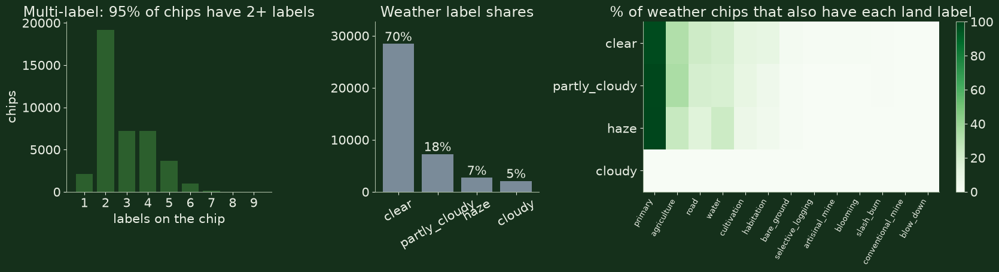

In [133]:
# Labels-per-chip, weather shares, and weather×land co-occurrence (EDA §6)
perChip = Yeda.sum(1)  # number of positive labels on each chip
# Assign `fig, axes` ← plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios"…
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 0.8, 1.6]})

# Panel 1: histogram of how many labels appear on each chip
ks, cnt = np.unique(perChip, return_counts=True)
# Assign `axes[0].bar(ks, cnt, color` ← GROUP_COLOR["common"])
axes[0].bar(ks, cnt, color=GROUP_COLOR["common"])
# Execute: axes[0].set_xlabel("labels on the chip"); axes[0].set_ylabel("chips"); axes[0].set_xticks(
axes[0].set_xlabel("labels on the chip"); axes[0].set_ylabel("chips"); axes[0].set_xticks(ks)
# Execute: axes[0].set_title(f"Multi-label: {np.mean(perChip > 1):.0%} of chips have 2+ labels")
axes[0].set_title(f"Multi-label: {np.mean(perChip > 1):.0%} of chips have 2+ labels")

# Panel 2: weather class counts (exactly one weather label per chip in Planet Amazon)
wc = [Yeda[:, Leda[w]].sum() for w in WEATHER_EDA]
# Assign `axes[1].bar(WEATHER_EDA, wc, color` ← GROUP_COLOR["weather"])
axes[1].bar(WEATHER_EDA, wc, color=GROUP_COLOR["weather"])
# Loop over items
for x, v in enumerate(wc):
    # Assign `axes[1].text(x, v, f"{v / Neda:.0%}", ha` ← "center", va="bottom")
    axes[1].text(x, v, f"{v / Neda:.0%}", ha="center", va="bottom")
# Assign `axes[1].set_ylim(top` ← max(wc) * 1.15 if wc else 1)
axes[1].set_ylim(top=max(wc) * 1.15 if wc else 1)
# Assign `axes[1].set_title("Weather label shares"); axes[1].tick_params(axis` ← "x", rotation=30)
axes[1].set_title("Weather label shares"); axes[1].tick_params(axis="x", rotation=30)

# Panel 3: for each weather, how often each land label appears (%)
land = sorted(COMMON_EDA, key=lambda l: -freqEda[Leda[l]]) + sorted(RARE_EDA, key=lambda l: -freqEda[Leda[l]])
# Assign `M` ← np.array([[Yeda[Yeda[:, Leda[w]] == 1, Leda[l]].mean() * 100 for …
M = np.array([[Yeda[Yeda[:, Leda[w]] == 1, Leda[l]].mean() * 100 for l in land] for w in WEATHER_EDA]) if WEATHER_EDA and land else np.zeros((1, 1))
# Assign `im` ← axes[2].imshow(M, cmap="Greens", vmin=0, vmax=100, aspect="auto")
im = axes[2].imshow(M, cmap="Greens", vmin=0, vmax=100, aspect="auto")
# Assign `axes[2].set_xticks(range(len(land))); axes[2].set_xticklabels(land, rotation` ← 60, ha="right", fontsize=9)
axes[2].set_xticks(range(len(land))); axes[2].set_xticklabels(land, rotation=60, ha="right", fontsize=9)
# Execute: axes[2].set_yticks(range(len(WEATHER_EDA))); axes[2].set_yticklabels(WEATHER_EDA)
axes[2].set_yticks(range(len(WEATHER_EDA))); axes[2].set_yticklabels(WEATHER_EDA)
# Execute: axes[2].set_title("% of weather chips that also have each land label")
axes[2].set_title("% of weather chips that also have each land label")
# Assign `fig.colorbar(im, ax` ← axes[2], fraction=0.046)
fig.colorbar(im, ax=axes[2], fraction=0.046)
# Save weather/land EDA figure under both local and Run2 names
plt.tight_layout()
# Run this pipeline step
save_eda(fig, "eda_weather_land.png")
# Run this pipeline step
save_eda(fig, "03_labels_per_chip_and_weather.png")
# Run this pipeline step
plt.show(); plt.close()

saved eda_ndvi_by_label.png
saved 07_ndvi_by_label.png


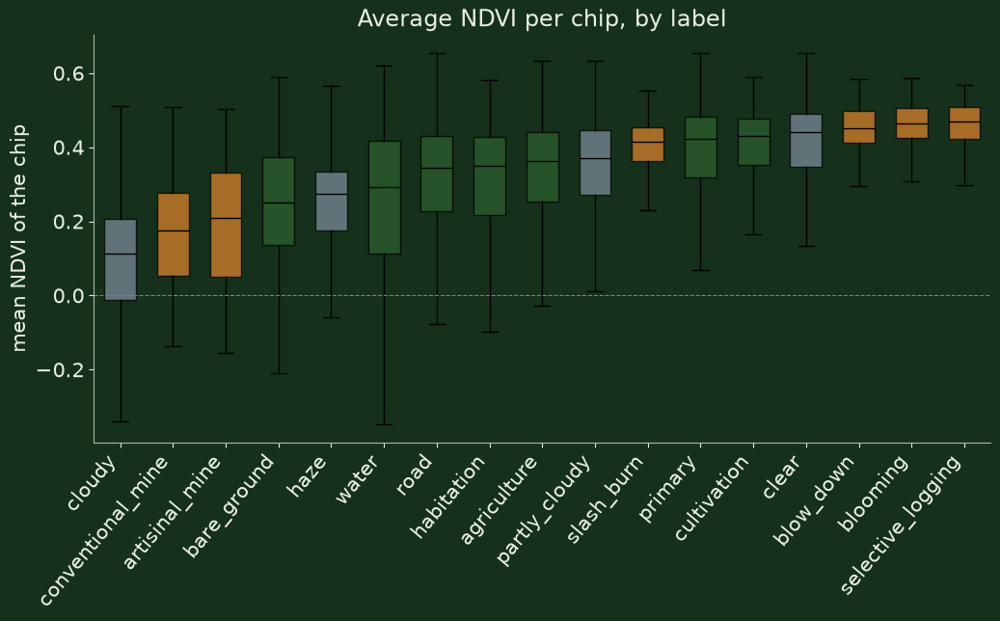

In [134]:
# Mean NDVI by label (EDA §10) — informative only when TIF/NIR cache is real
# Detect JPG placeholder mode from cache meta
metaEda = json.load(open(f"{edaCache}/cache_meta.json")) if os.path.exists(f"{edaCache}/cache_meta.json") else {}
# If-branch
if metaEda.get("jpg_mode"):
    # Log to notebook output
    print("JPG cache: NIR/NDVI are placeholders — skipping NDVI-by-label figure.")
# Else branch
else:
    # Average NDVI per chip from channel 4 (stored as 0–1)
    meanNdvi = np.empty(Neda, dtype=np.float32)
    # Loop over items
    for s in range(0, Neda, 2000):
        # Assign `meanNdvi[s:s + 2000]` ← np.asarray(Xeda[s:s + 2000, 4], dtype=np.float32).mean((1, 2)) * …
        meanNdvi[s:s + 2000] = np.asarray(Xeda[s:s + 2000, 4], dtype=np.float32).mean((1, 2)) * 2 - 1
    # Order labels by median NDVI
    byLabel = sorted(labelsEda, key=lambda l: np.median(meanNdvi[Yeda[:, Leda[l]] == 1]))
    # Assign `fig, ax` ← plt.subplots(figsize=(12, 5.5))
    fig, ax = plt.subplots(figsize=(12, 5.5))
    # Assign `bp` ← ax.boxplot([meanNdvi[Yeda[:, Leda[l]] == 1] for l in byLabel], sh…
    bp = ax.boxplot([meanNdvi[Yeda[:, Leda[l]] == 1] for l in byLabel], showfliers=False, patch_artist=True, widths=0.6)
    # Loop over items
    for patch, l in zip(bp["boxes"], byLabel):
        # Execute: patch.set_facecolor(GROUP_COLOR[group_eda(l)]); patch.set_alpha(0.75)
        patch.set_facecolor(GROUP_COLOR[group_eda(l)]); patch.set_alpha(0.75)
    # Loop over items
    for m in bp["medians"]:
        # Execute: m.set_color("black")
        m.set_color("black")
    # Assign `ax.set_xticks(range(1, len(byLabel) + 1)); ax.set_xticklabels(byLabel, rotation` ← 50, ha="right")
    ax.set_xticks(range(1, len(byLabel) + 1)); ax.set_xticklabels(byLabel, rotation=50, ha="right")
    # Assign `ax.set_ylabel("mean NDVI of the chip"); ax.axhline(0, color` ← "gray", lw=0.8, ls="--")
    ax.set_ylabel("mean NDVI of the chip"); ax.axhline(0, color="gray", lw=0.8, ls="--")
    # Execute: ax.set_title("Average NDVI per chip, by label")
    ax.set_title("Average NDVI per chip, by label")
    # Save NDVI-by-label under both local and Run2 names
    save_eda(fig, "eda_ndvi_by_label.png")
    # Run this pipeline step
    save_eda(fig, "07_ndvi_by_label.png")
    # Run this pipeline step
    plt.show(); plt.close()

saved eda_oversampling_defor.png
saved deck_04_oversampling.png


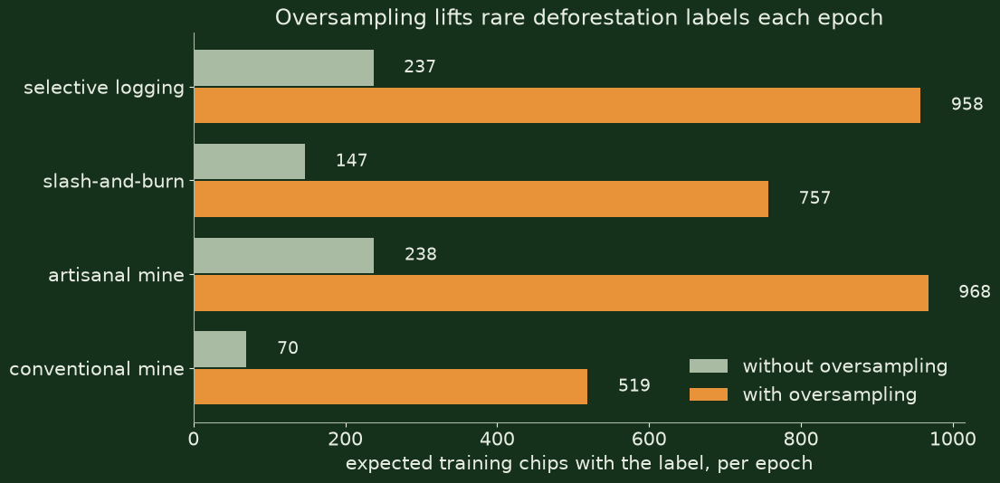

pos_weight (loss) for deforestation labels: {'selective_logging': 10.0, 'slash_burn': 10.0, 'artisinal_mine': 10.0, 'conventional_mine': 10.0}


In [135]:
# Oversampling effect on rare deforestation labels (EDA § slide figure)
trEda = spEda["train"]
# Assign `ytr` ← Yeda[trEda].astype(float)
ytr = Yeda[trEda].astype(float)
# Label frequency in the training split
f = ytr.mean(0).clip(1e-6, None)
# Per-chip sampling weight = max over its labels of f ** -0.5 (rarest label wins)
w = (ytr * f ** -0.5).max(1)
# Assign `p` ← w / w.sum()
p = w / w.sum()
# Expected positive counts per epoch with vs without oversampling
seenWith = len(trEda) * (ytr * p[:, None]).sum(0)
# Assign `seenWithout` ← ytr.sum(0)
seenWithout = ytr.sum(0)
# Assign `posW` ← np.clip(np.sqrt((1 - f) / f), 1, 10)
posW = np.clip(np.sqrt((1 - f) / f), 1, 10)

# Assign `show` ← [l for l in DEFOR_EDA if l in Leda]
show = [l for l in DEFOR_EDA if l in Leda]
# If-branch
if not show:
    # Log to notebook output
    print("No deforestation labels found — skip oversampling figure.")
# Else branch
else:
    # Execute: deck_style()
    deck_style()
    # Assign `nice` ← [{"slash_burn": "slash-and-burn", "artisinal_mine": "artisanal mi…
    nice = [{"slash_burn": "slash-and-burn", "artisinal_mine": "artisanal mine"}.get(l, l.replace("_", " ")) for l in show]
    # Assign `yy` ← np.arange(len(show))[::-1]
    yy = np.arange(len(show))[::-1]
    # Assign `fig, ax` ← plt.subplots(figsize=(11, 5.6))
    fig, ax = plt.subplots(figsize=(11, 5.6))
    # Assign `b0` ← ax.barh(yy + 0.2, [seenWithout[Leda[l]] for l in show], 0.38, col…
    b0 = ax.barh(yy + 0.2, [seenWithout[Leda[l]] for l in show], 0.38, color=DECK["muted"], label="without oversampling")
    # Assign `b1` ← ax.barh(yy - 0.2, [seenWith[Leda[l]] for l in show], 0.38, color=…
    b1 = ax.barh(yy - 0.2, [seenWith[Leda[l]] for l in show], 0.38, color=DECK["orange"], label="with oversampling")
    # Loop over items
    for bars in (b0, b1):
        # Loop over items
        for b in bars:
            # Execute: ax.text(b.get_width() + 40, b.get_y() + b.get_height() / 2, f"{b.get_width():,.0f}"
            ax.text(b.get_width() + 40, b.get_y() + b.get_height() / 2, f"{b.get_width():,.0f}",
                    # Field/kwarg `va`
                    va="center", fontsize=14, color=DECK["text"])
    # Execute: ax.set_yticks(yy); ax.set_yticklabels(nice)
    ax.set_yticks(yy); ax.set_yticklabels(nice)
    # Execute: ax.set_xlabel("expected training chips with the label, per epoch")
    ax.set_xlabel("expected training chips with the label, per epoch")
    # Assign `ax.legend(frameon` ← False); ax.set_title("Oversampling lifts rare deforestation label…
    ax.legend(frameon=False); ax.set_title("Oversampling lifts rare deforestation labels each epoch")
    # Save oversampling figure under both local and Run2 deck names
    save_eda(fig, "eda_oversampling_defor.png")
    # Run this pipeline step
    save_eda(fig, "deck_04_oversampling.png")
    # Run this pipeline step
    plt.show(); plt.close()
    # Log to notebook output
    print("pos_weight (loss) for deforestation labels:", {l: float(posW[Leda[l]]) for l in show})

saved eda_rgb_nir_ndvi.png
saved deck_03_bands.png


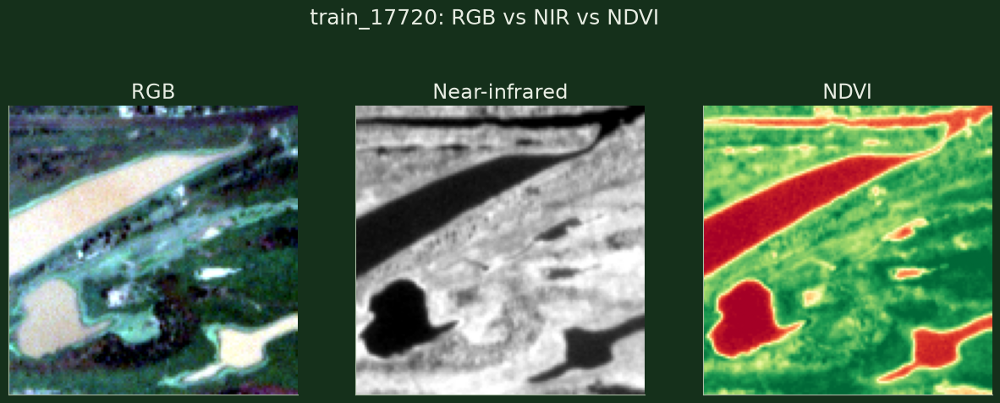

In [136]:
# RGB / NIR / NDVI side-by-side for a clear forest+water+cleared chip (EDA bands slide)
if metaEda.get("jpg_mode"):
    # Log to notebook output
    print("JPG cache — skipping RGB/NIR/NDVI band panel.")
# Else branch
else:
    # Define `natural_rgb`
    def natural_rgb(x, lo=2, hi=98, gamma=0.9):
        # Execute: """Per-chip percentile stretch of RGB for display only."""
        """Per-chip percentile stretch of RGB for display only."""
        # Assign `img` ← rgb_chip(x)
        img = rgb_chip(x)
        # Assign `out` ← np.empty_like(img)
        out = np.empty_like(img)
        # Loop over items
        for c in range(3):
            # Assign `a, b` ← np.percentile(img[..., c], [lo, hi])
            a, b = np.percentile(img[..., c], [lo, hi])
            # Assign `out[..., c]` ← np.clip((img[..., c] - a) / (b - a + 1e-6), 0, 1)
            out[..., c] = np.clip((img[..., c] - a) / (b - a + 1e-6), 0, 1)
        # Return value to caller
        return out ** gamma

    # Define `nir_view`
    def nir_view(x, lo=2, hi=98):
        # Assign `"""Stretched NIR band (bright` ← strong vegetation reflectance)."""
        """Stretched NIR band (bright = strong vegetation reflectance)."""
        # Assign `v` ← np.asarray(x[3], dtype=np.float32)
        v = np.asarray(x[3], dtype=np.float32)
        # Assign `a, b` ← np.percentile(v, [lo, hi])
        a, b = np.percentile(v, [lo, hi])
        # Return value to caller
        return np.clip((v - a) / (b - a + 1e-6), 0, 1)

    # Define `band_candidates`
    def band_candidates():
        # Assign `has` ← lambda l: Yeda[:, Leda[l]] == 1 if l in Leda else np.zeros(Neda, …
        has = lambda l: Yeda[:, Leda[l]] == 1 if l in Leda else np.zeros(Neda, dtype=bool)
        # Assign `cleared` ← has("agriculture") | has("bare_ground")
        cleared = has("agriculture") | has("bare_ground")
        # Return value to caller
        return np.where(has("clear") & has("primary") & has("water") & cleared & (Yeda.sum(1) <= 5))[0]

    # Assign `cand` ← band_candidates()
    cand = band_candidates()
    # If-branch
    if len(cand) == 0:
        # Log to notebook output
        print("No suitable band-panel chip found.")
    # Else branch
    else:
        # Assign `rngEda` ← np.random.RandomState(0)
        rngEda = np.random.RandomState(0)
        # Assign `i` ← int(rngEda.choice(cand))
        i = int(rngEda.choice(cand))
        # Assign `x` ← Xeda[i]
        x = Xeda[i]
        # Assign `nd` ← ndvi_chip(x)
        nd = ndvi_chip(x)
        # Execute: deck_style()
        deck_style()
        # Assign `fig, axes` ← plt.subplots(1, 3, figsize=(15, 5.9))
        fig, axes = plt.subplots(1, 3, figsize=(15, 5.9))
        # Execute: axes[0].imshow(natural_rgb(x))
        axes[0].imshow(natural_rgb(x))
        # Assign `axes[1].imshow(nir_view(x), cmap` ← "gray")
        axes[1].imshow(nir_view(x), cmap="gray")
        # Assign `lo, hi` ← np.percentile(nd, [2, 98])
        lo, hi = np.percentile(nd, [2, 98])
        # Assign `im` ← axes[2].imshow(nd, cmap="RdYlGn", vmin=lo, vmax=hi)
        im = axes[2].imshow(nd, cmap="RdYlGn", vmin=lo, vmax=hi)
        # Execute: axes[0].set_title("RGB"); axes[1].set_title("Near-infrared"); axes[2].set_title("NDVI")
        axes[0].set_title("RGB"); axes[1].set_title("Near-infrared"); axes[2].set_title("NDVI")
        # Loop over items
        for ax in axes:
            # Execute: ax.set_xticks([]); ax.set_yticks([])
            ax.set_xticks([]); ax.set_yticks([])
        # Assign `fig.suptitle(f"{namesEda[i]}: RGB vs NIR vs NDVI", color` ← DECK["text"])
        fig.suptitle(f"{namesEda[i]}: RGB vs NIR vs NDVI", color=DECK["text"])
        # Save RGB/NIR/NDVI panel under both local and Run2 deck names
        save_eda(fig, "eda_rgb_nir_ndvi.png")
        # Run this pipeline step
        save_eda(fig, "deck_03_bands.png")
        # Run this pipeline step
        plt.show(); plt.close()

saved deck_01_label_frequency.png
saved 01_label_frequency.png


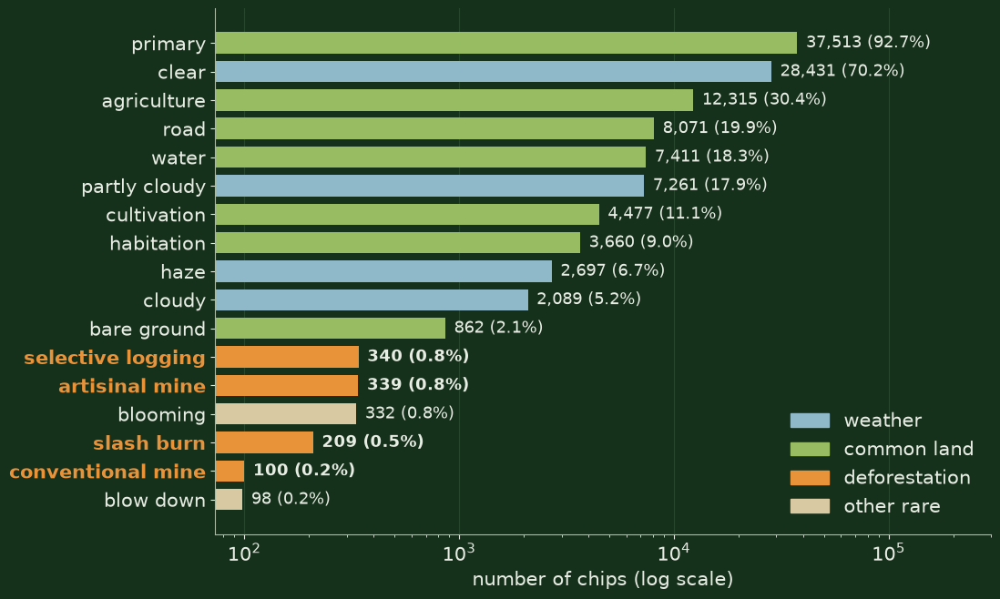

In [137]:
# Slide figure: label frequency (log scale), deck style
# Import dependency: import matplotlib.patches as mpatches
import matplotlib.patches as mpatches

# Run this pipeline step
deck_style()
# Define function `deck_group`
def deck_group(l):
    # Conditional branch
    if l in WEATHER_EDA: return "weather"
    # Conditional branch
    if l in DEFOR_EDA: return "deforestation"
    # Conditional branch
    if l in RARE_EDA: return "other rare"
    # Return result to caller
    return "common land"

# Set `deckColor` = {"weather": DECK["sky"], "common land": DECK["moss"],
deckColor = {"weather": DECK["sky"], "common land": DECK["moss"],
             # Continuation of the multi-line expression
             "deforestation": DECK["orange"], "other rare": DECK["sand"]}
# Set `order` = sorted(labelsEda, key=lambda l: freqEda[Leda[l]])
order = sorted(labelsEda, key=lambda l: freqEda[Leda[l]])
# Assign `fig, ax` ← plt.subplots(figsize=(11, 7.5))
fig, ax = plt.subplots(figsize=(11, 7.5))
# Set `bars` = ax.barh([l.replace("_", " ") for l in order], [freqEda[Le...
bars = ax.barh([l.replace("_", " ") for l in order], [freqEda[Leda[l]] for l in order],
               # Keyword/field `color`
               color=[deckColor[deck_group(l)] for l in order], height=0.75)
# Draw or configure plot elements
ax.set_xscale("log"); ax.set_xlabel("number of chips (log scale)")
# Draw or configure plot elements
ax.set_xlim(right=freqEda.max() * 8)
# Iterate over this sequence
for b, l in zip(bars, order):
    # Draw or configure plot elements
    ax.text(b.get_width() * 1.1, b.get_y() + b.get_height() / 2,
            # Continuation of the multi-line expression
            f"{freqEda[Leda[l]]:,} ({freqEda[Leda[l]] / Neda:.1%})",
            # Set `va` = "center", fontsize=13, color=DECK["text"],
            va="center", fontsize=13, color=DECK["text"],
            # Set `fontweight` = "bold" if l in DEFOR_EDA else "normal")
            fontweight="bold" if l in DEFOR_EDA else "normal")
# Iterate over this sequence
for t in ax.get_yticklabels():
    # Conditional branch
    if t.get_text().replace(" ", "_") in DEFOR_EDA:
        # Run this pipeline step
        t.set_color(DECK["orange"]); t.set_fontweight("bold")
# Draw or configure plot elements
ax.legend(handles=[mpatches.Patch(color=c, label=g) for g, c in deckColor.items()],
          # Keyword/field `loc`
          loc="lower right", frameon=False)
# Draw or configure plot elements
ax.grid(axis="x", which="major", alpha=0.5); ax.set_axisbelow(True)
# Save, show, and close the figure
save_eda(fig, "deck_01_label_frequency.png")
# Run this pipeline step
save_eda(fig, "01_label_frequency.png"); plt.show(); plt.close()

primary              chip 37025
agriculture          chip 4558
road                 chip 30242
water                chip 3053
selective_logging    chip 31998
slash_burn           chip 27915
artisinal_mine       chip 39311
conventional_mine    chip 17444
saved deck_02_example_chips.png


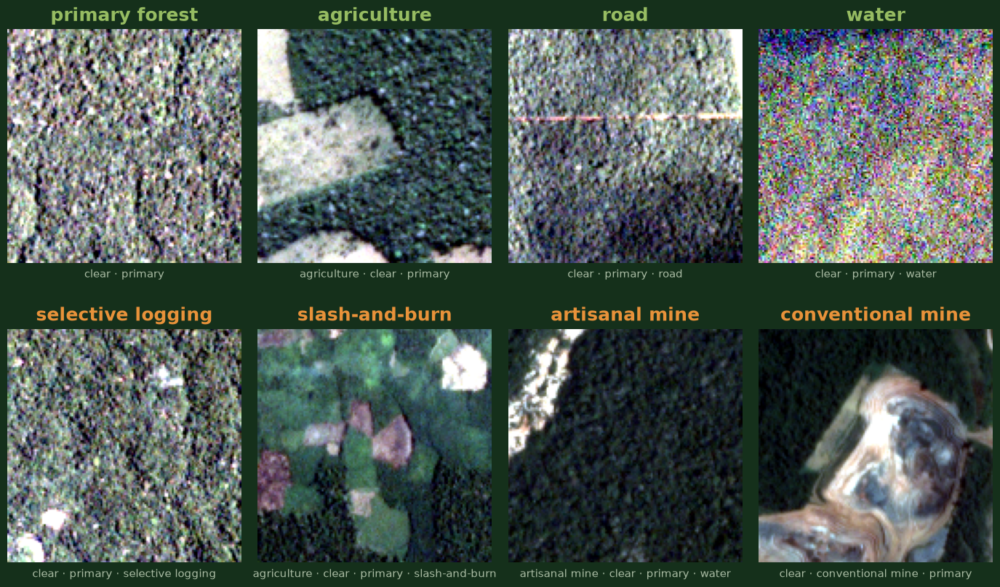

In [138]:
# Slide figure: 8 example chips (4 common land + 4 deforestation), deck style
# Display-only per-chip stretch; cache/models unchanged.
# Set `commonShow` = ["primary", "agriculture", "road", "water"]
commonShow = ["primary", "agriculture", "road", "water"]
# Set `deforShow` = ["selective_logging", "slash_burn", "artisinal_mine", "co...
deforShow = ["selective_logging", "slash_burn", "artisinal_mine", "conventional_mine"]
# Set `pickOverride` = {}
pickOverride = {}  # e.g. {"water": 1234} to force a chip index

# Define function `natural_rgb`
def natural_rgb(x, lo=2, hi=98, gamma=0.9):
    # Set `img` = rgb_chip(x)
    img = rgb_chip(x)
    # Set `out` = np.empty_like(img)
    out = np.empty_like(img)
    # Iterate over this sequence
    for c in range(3):
        # Set `a, b` = np.percentile(img[..., c], [lo, hi])
        a, b = np.percentile(img[..., c], [lo, hi])
        # Run this pipeline step
        out[..., c] = np.clip((img[..., c] - a) / (b - a + 1e-6), 0, 1)
    # Return result to caller
    return out ** gamma

# Define function `nice_name`
def nice_name(l):
    # Return result to caller
    return {"primary": "primary forest", "slash_burn": "slash-and-burn",
            # Continuation of the multi-line expression
            "artisinal_mine": "artisanal mine"}.get(l, l.replace("_", " "))

# Set `prefer` = {"primary": {"clear", "primary"}, "agriculture": {"agricu...
prefer = {"primary": {"clear", "primary"}, "agriculture": {"agriculture", "clear", "primary"},
          # Continuation of the multi-line expression
          "road": {"clear", "primary", "road"}, "water": {"clear", "primary", "water"}}

# Define function `candidates`
def candidates(label):
    # Set `has` = Yeda[:, Leda[label]] == 1
    has = Yeda[:, Leda[label]] == 1
    # Set `clear` = Yeda[:, Leda["clear"]] == 1 if "clear" in Leda else np.on...
    clear = Yeda[:, Leda["clear"]] == 1 if "clear" in Leda else np.ones(Neda, dtype=bool)
    # Conditional branch
    if label in prefer:
        # Set `want` = np.zeros(len(labelsEda), int)
        want = np.zeros(len(labelsEda), int)
        # Run this pipeline step
        want[[Leda[l] for l in prefer[label] if l in Leda]] = 1
        # Set `exact` = np.where((Yeda == want).all(1))[0]
        exact = np.where((Yeda == want).all(1))[0]
        # Conditional branch
        if len(exact): return exact
    # Set `cand` = np.where(has & clear & (Yeda.sum(1) <= 4))[0]
    cand = np.where(has & clear & (Yeda.sum(1) <= 4))[0]
    # Return result to caller
    return cand if len(cand) else np.where(has)[0]

# Define function `pick_chip`
def pick_chip(label, seed=7):
    # Conditional branch
    if label in pickOverride:
        # Return result to caller
        return pickOverride[label]
    # Return result to caller
    return int(np.random.RandomState(seed).choice(candidates(label)))

# Define function `tags_of`
def tags_of(i):
    # Return result to caller
    return " ".join(labelsEda[j] for j in range(len(labelsEda)) if Yeda[i, j])

# Run this pipeline step
deck_style()
# Assign `fig, axes` ← plt.subplots(2, 4, figsize=(14, 8.2))
fig, axes = plt.subplots(2, 4, figsize=(14, 8.2))
# Iterate over this sequence
for row, (show, col) in enumerate([(commonShow, DECK["moss"]), (deforShow, DECK["orange"])]):
    # Iterate over this sequence
    for ax, l in zip(axes[row], show):
        # Conditional branch
        if l not in Leda:
            # Draw or configure plot elements
            ax.axis("off"); continue
        # Set `i` = pick_chip(l)
        i = pick_chip(l)
        # Draw or configure plot elements
        ax.imshow(natural_rgb(Xeda[i]))
        # Draw or configure plot elements
        ax.set_xticks([]); ax.set_yticks([])
        # Iterate over this sequence
        for sp in ax.spines.values():
            # Run this pipeline step
            sp.set_visible(False)
        # Draw or configure plot elements
        ax.set_title(nice_name(l), color=col, fontsize=18, fontweight="bold", pad=8)
        # Draw or configure plot elements
        ax.set_xlabel(" · ".join(nice_name(t) if t != "primary" else "primary" for t in tags_of(i).split()),
                      # Keyword/field `color`
                      color=DECK["muted"], fontsize=11, labelpad=6)
        # Print status / metrics to the notebook
        print(f"{l:<20} chip {i}")
# Run this pipeline step
fig.tight_layout(h_pad=2.5)
# Save, show, and close the figure
save_eda(fig, "deck_02_example_chips.png"); plt.show(); plt.close()

# Define function `browse_label`
def browse_label(label, n=12, seed=0):
    # Set `cand` = candidates(label)
    cand = candidates(label)
    # Set `show` = np.random.RandomState(seed).choice(cand, min(n, len(cand)...
    show = np.random.RandomState(seed).choice(cand, min(n, len(cand)), replace=False)
    # Assign `fig, axes` ← plt.subplots(2, 6, figsize=(16, 6))
    fig, axes = plt.subplots(2, 6, figsize=(16, 6))
    # Iterate over this sequence
    for ax, i in zip(axes.ravel(), show):
        # Draw or configure plot elements
        ax.imshow(natural_rgb(Xeda[i])); ax.set_xticks([]); ax.set_yticks([])
        # Draw or configure plot elements
        ax.set_title(f"chip {i}", fontsize=12, color=DECK["text"])
    # Iterate over this sequence
    for ax in axes.ravel()[len(show):]:
        # Draw or configure plot elements
        ax.axis("off")
    # Run this pipeline step
    fig.suptitle(f"{nice_name(label)}: {len(cand)} candidates", color=DECK["text"])
    # Render and close the figure
    fig.tight_layout(); plt.show(); plt.close()

In [139]:
# Slide figure: rare labels at 256 px vs resized 128 px (needs AMAZON_ROOT_256 cache)
# Set `resLabels` = [l for l in ["selective_logging", "slash_burn", "artisinal_mine", "blow_down", "conventional_mine"] if l in Leda]
resLabels = [l for l in ["selective_logging", "slash_burn", "artisinal_mine", "blow_down", "conventional_mine"] if l in Leda]
# Set `perLabel` = 2
perLabel = 2
# Set `win` = 64
win = 64

# Define function `stretch_rgb`
def stretch_rgb(img, ref=None):
    # Set `ref` = img if ref is None else ref
    ref = img if ref is None else ref
    # Set `out` = np.empty_like(img, dtype=np.float32)
    out = np.empty_like(img, dtype=np.float32)
    # Iterate over this sequence
    for c in range(3):
        # Set `a, b` = np.percentile(ref[..., c], [2, 98])
        a, b = np.percentile(ref[..., c], [2, 98])
        # Run this pipeline step
        out[..., c] = np.clip((img[..., c] - a) / (b - a + 1e-6), 0, 1)
    # Return result to caller
    return out

# Define function `detail_window`
def detail_window(big, small):
    # Set `gBig, gSmall` = big.mean(-1), small.mean(-1)
    gBig, gSmall = big.mean(-1), small.mean(-1)
    # Set `up` = cv2.resize(gSmall, (256, 256), interpolation=cv2.INTER_LI...
    up = cv2.resize(gSmall, (256, 256), interpolation=cv2.INTER_LINEAR)
    # Set `lossMap` = (gBig - up) ** 2
    lossMap = (gBig - up) ** 2
    # Set `lost` = lossMap.sum() / (((gBig - gBig.mean()) ** 2).sum() + 1e-9)
    lost = lossMap.sum() / (((gBig - gBig.mean()) ** 2).sum() + 1e-9)
    # Set `s` = cv2.blur(lossMap, (win, win))[win // 2: 256 - win // 2 + ...
    s = cv2.blur(lossMap, (win, win))[win // 2: 256 - win // 2 + 1, win // 2: 256 - win // 2 + 1]
    # Set `y0, x0` = np.unravel_index(np.argmax(s), s.shape)
    y0, x0 = np.unravel_index(np.argmax(s), s.shape)
    # Return result to caller
    return y0, x0, lost

# Define function `pick_clear`
def pick_clear(l, n=1):
    # Set `pos` = np.where(Yeda[:, Leda[l]] == 1)[0]
    pos = np.where(Yeda[:, Leda[l]] == 1)[0]
    # Conditional branch
    if "clear" in Leda and l not in WEATHER_EDA:
        # Set `clear` = pos[Yeda[pos, Leda["clear"]] == 1]
        clear = pos[Yeda[pos, Leda["clear"]] == 1]
        # Set `pos` = clear if len(clear) >= n else pos
        pos = clear if len(clear) >= n else pos
    # Return result to caller
    return np.random.RandomState(42).choice(pos, min(n, len(pos)), replace=False)

# Conditional branch
if not has256:
    # Print status / metrics to the notebook
    print(f"No 256 px cache at {edaRoot256}/cache/X.npy — skip resolution figures.")
# Else branch
else:
    # Set `Xeda256` = np.load(f"{edaRoot256}/cache/X.npy", mmap_mode="r")
    Xeda256 = np.load(f"{edaRoot256}/cache/X.npy", mmap_mode="r")
    # Run this pipeline step
    deck_style()
    # Set `picks` = [(l, int(i)) for l in resLabels for i in pick_clear(l, pe...
    picks = [(l, int(i)) for l in resLabels for i in pick_clear(l, perLabel)]
    # Assign `fig, axes` ← plt.subplots(len(picks), 4, figsize=(15, 3.9 * max(len(pi...
    fig, axes = plt.subplots(len(picks), 4, figsize=(15, 3.9 * max(len(picks), 1)))
    # Set `axes` = np.atleast_2d(axes)
    axes = np.atleast_2d(axes)
    # Iterate over this sequence
    for r, (l, i) in enumerate(picks):
        # Set `big, small` = rgb_chip(Xeda256[i]), rgb_chip(Xeda[i])
        big, small = rgb_chip(Xeda256[i]), rgb_chip(Xeda[i])
        # If 256 cache is RGB-only shape mismatch is fine; if same tile size, still compare
        if big.shape[0] != 256:
            # Set `big` = cv2.resize(big, (256, 256), interpolation=cv2.INTER_LINEAR)
            big = cv2.resize(big, (256, 256), interpolation=cv2.INTER_LINEAR)
        # Conditional branch
        if small.shape[0] != 128:
            # Set `small` = cv2.resize(small, (128, 128), interpolation=cv2.INTER_AREA)
            small = cv2.resize(small, (128, 128), interpolation=cv2.INTER_AREA)
        # Set `y0, x0, lost` = detail_window(big, small)
        y0, x0, lost = detail_window(big, small)
        # Set `bigS, smallS` = stretch_rgb(big), stretch_rgb(small, big)
        bigS, smallS = stretch_rgb(big), stretch_rgb(small, big)
        # Draw or configure plot elements
        axes[r, 0].imshow(bigS); axes[r, 1].imshow(smallS, interpolation="nearest")
        # Draw or configure plot elements
        axes[r, 2].imshow(bigS[y0:y0 + win, x0:x0 + win], interpolation="nearest")
        # Draw or configure plot elements
        axes[r, 3].imshow(smallS[y0 // 2:(y0 + win) // 2, x0 // 2:(x0 + win) // 2], interpolation="nearest")
        # Iterate over this sequence
        for c, scale in ((0, 1), (1, 0.5)):
            # Draw or configure plot elements
            axes[r, c].add_patch(mpl.patches.Rectangle(
                # Continuation of the multi-line expression
                (x0 * scale - 0.5, y0 * scale - 0.5), win * scale, win * scale,
                # Set `fill` = False, ec="yellow", lw=2))
                fill=False, ec="yellow", lw=2))
        # Draw or configure plot elements
        axes[r, 0].set_ylabel(f"{l}\n{namesEda[i]}", fontsize=11, fontweight="bold")
        # Set `titles` = ["256 px original", f"128 px (detail lost {lost:.0%})", "...
        titles = ["256 px original", f"128 px (detail lost {lost:.0%})", "zoom: 256 px", "zoom: 128 px"]
        # Iterate over this sequence
        for c in range(4):
            # Draw or configure plot elements
            axes[r, c].set_title(titles[c]); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    # Run this pipeline step
    fig.suptitle("Rare labels at original resolution vs after resizing to 128 px", y=1.0)
    # Save, show, and close the figure
    plt.tight_layout(); save_eda(fig, "08_resolution_rare_labels.png"); plt.show(); plt.close()

    # Single-slide selective_logging version
    if "selective_logging" in Leda:
        # Set `i` = int(pick_clear("selective_logging")[0])
        i = int(pick_clear("selective_logging")[0])
        # Set `big, small` = rgb_chip(Xeda256[i]), rgb_chip(Xeda[i])
        big, small = rgb_chip(Xeda256[i]), rgb_chip(Xeda[i])
        # Conditional branch
        if big.shape[0] != 256:
            # Set `big` = cv2.resize(big, (256, 256), interpolation=cv2.INTER_LINEAR)
            big = cv2.resize(big, (256, 256), interpolation=cv2.INTER_LINEAR)
        # Conditional branch
        if small.shape[0] != 128:
            # Set `small` = cv2.resize(small, (128, 128), interpolation=cv2.INTER_AREA)
            small = cv2.resize(small, (128, 128), interpolation=cv2.INTER_AREA)
        # Set `y0, x0, lost` = detail_window(big, small)
        y0, x0, lost = detail_window(big, small)
        # Set `bigS, smallS` = stretch_rgb(big), stretch_rgb(small, big)
        bigS, smallS = stretch_rgb(big), stretch_rgb(small, big)
        # Assign `fig, axes` ← plt.subplots(1, 4, figsize=(18, 4.8))
        fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
        # Set `panels` = [(bigS, "Original 256 px"), (smallS, f"Resized 128 px ({l...
        panels = [(bigS, "Original 256 px"), (smallS, f"Resized 128 px ({lost:.0%} of detail lost)"),
                  # Continuation of the multi-line expression
                  (bigS[y0:y0 + win, x0:x0 + win], "Zoom: original"),
                  # Continuation of the multi-line expression
                  (smallS[y0 // 2:(y0 + win) // 2, x0 // 2:(x0 + win) // 2], "Zoom: resized")]
        # Iterate over this sequence
        for ax, (img, t) in zip(axes, panels):
            # Draw or configure plot elements
            ax.imshow(img, interpolation="nearest"); ax.set_title(t); ax.set_xticks([]); ax.set_yticks([])
        # Iterate over this sequence
        for c, scale in ((0, 1), (1, 0.5)):
            # Draw or configure plot elements
            axes[c].add_patch(mpl.patches.Rectangle(
                # Continuation of the multi-line expression
                (x0 * scale - 0.5, y0 * scale - 0.5), win * scale, win * scale,
                # Set `fill` = False, ec="yellow", lw=2))
                fill=False, ec="yellow", lw=2))
        # Run this pipeline step
        fig.suptitle(f"selective_logging ({namesEda[i]}): thin trails at 256 vs 128", y=1.02)
        # Save, show, and close the figure
        save_eda(fig, "09_selective_logging_resize.png"); plt.show(); plt.close()

No 256 px cache at /mnt/c/Users/legen/amazon_project_tif_256/cache/X.npy — skip resolution figures.


saved 02_label_cooccurrence.png


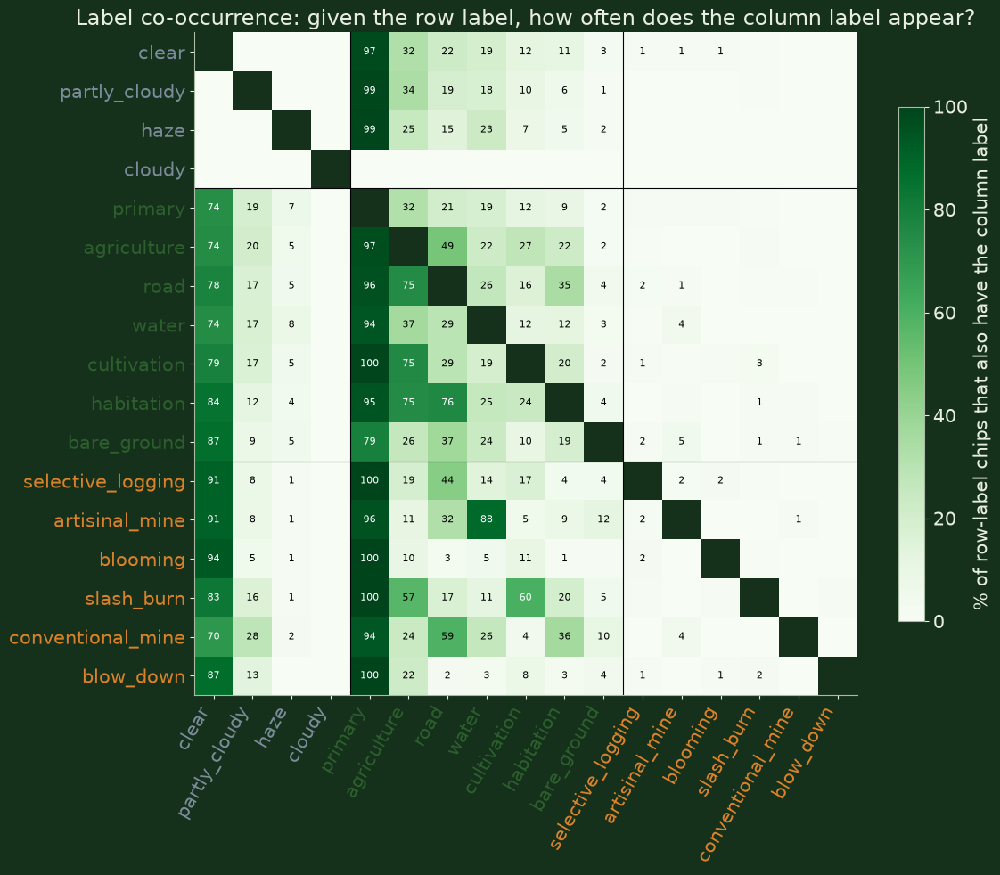

In [140]:
# Label co-occurrence P(column | row) — Run2 EDA 02_label_cooccurrence
# Reuses Yeda / Leda / WEATHER_EDA / COMMON_EDA / RARE_EDA from the EDA setup cell
ordered = WEATHER_EDA + sorted(COMMON_EDA, key=lambda l: -freqEda[Leda[l]]) + sorted(RARE_EDA, key=lambda l: -freqEda[Leda[l]])
# Column indices into the multi-hot matrix
idx = [Leda[l] for l in ordered]
# Raw co-occurrence counts (label i and label j both positive)
co = (Yeda[:, idx].T.astype(np.int64) @ Yeda[:, idx].astype(np.int64))
# Conditional percent: P(column | row)
cond = co / np.maximum(np.diag(co)[:, None], 1) * 100
# Hide the diagonal (always 100%)
np.fill_diagonal(cond, np.nan)

# Draw the heatmap
fig, ax = plt.subplots(figsize=(12, 10))
# Set `im` = ax.imshow(cond, cmap="Greens", vmin=0, vmax=100)
im = ax.imshow(cond, cmap="Greens", vmin=0, vmax=100)
# Run this pipeline step
ax.set_xticks(range(len(ordered))); ax.set_xticklabels(ordered, rotation=60, ha="right")
# Run this pipeline step
ax.set_yticks(range(len(ordered))); ax.set_yticklabels(ordered)
# Color tick labels by weather / rare / common group
for t, l in zip(ax.get_xticklabels(), ordered):
    # Run this pipeline step
    t.set_color(GROUP_COLOR[group_eda(l)])
# Iterate over this sequence
for t, l in zip(ax.get_yticklabels(), ordered):
    # Run this pipeline step
    t.set_color(GROUP_COLOR[group_eda(l)])
# Annotate cells with at least 1%
for r in range(len(ordered)):
    # Iterate over this sequence
    for c in range(len(ordered)):
        # Conditional branch
        if r != c and cond[r, c] >= 1:
            # Run this pipeline step
            ax.text(c, r, f"{cond[r, c]:.0f}", ha="center", va="center", fontsize=8,
                    # Continuation of the multi-line expression
                    color="white" if cond[r, c] > 60 else "black")
# Separators between weather / common / rare blocks
for b in (len(WEATHER_EDA) - 0.5, len(WEATHER_EDA) + len(COMMON_EDA) - 0.5):
    # Run this pipeline step
    ax.axhline(b, color="black", lw=0.8); ax.axvline(b, color="black", lw=0.8)
# Run this pipeline step
fig.colorbar(im, ax=ax, shrink=0.75, label="% of row-label chips that also have the column label")
# Run this pipeline step
ax.set_title("Label co-occurrence: given the row label, how often does the column label appear?")
# Run this pipeline step
save_eda(fig, "02_label_cooccurrence.png"); plt.show(); plt.close()
# Also write the raw count matrix for the deck appendix
np.savetxt(os.path.join(edaOut, "cooccurrence_counts.csv"), co, fmt="%d", delimiter=",", header=",".join(ordered))

label                  train     val    test
primary               26,259   5,616   5,638
clear                 19,901   4,258   4,272
agriculture            8,583   1,901   1,831
road                   5,656   1,201   1,214
water                  5,201   1,096   1,114
partly_cloudy          5,080   1,094   1,087
cultivation            3,143     663     671
habitation             2,550     556     554
haze                   1,891     406     400
cloudy                 1,462     314     313
bare_ground              607     126     129
selective_logging        237      52      51
artisinal_mine           238      50      51
blooming                 231      50      51
slash_burn               147      31      31
conventional_mine         70      15      15
blow_down                 69      14      15
saved 04_rare_labels_per_split.png


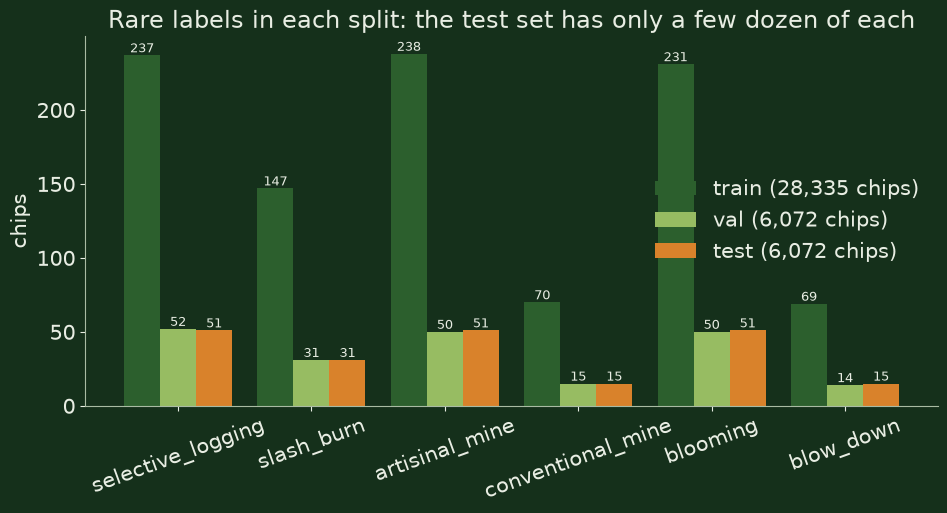

In [141]:
# Rare deforestation labels per train/val/test split — Run2 EDA 04_rare_labels_per_split
splitNames = ["train", "val", "test"]
# Positive counts per label inside each split
countsSplit = {s: Yeda[spEda[s]].sum(0) for s in splitNames}
# Print a compact table sorted by overall frequency
print(f"{'label':<20}" + "".join(f"{s:>8}" for s in splitNames))
# Iterate over this sequence
for l in sorted(labelsEda, key=lambda l: -freqEda[Leda[l]]):
    # Print status / metrics to the notebook
    print(f"{l:<20}" + "".join(f"{countsSplit[s][Leda[l]]:>8,}" for s in splitNames))

# Bar chart for the rare labels only
fig, ax = plt.subplots(figsize=(11, 4.8))
# Set `barW` = 0.27
barW = 0.27
# Set `x` = np.arange(len(RARE_EDA))
x = np.arange(len(RARE_EDA))
# Iterate over this sequence
for k, (s, c) in enumerate(zip(splitNames, ["#2C5F2D", "#97BC62", "#D9822B"])):
    # Set `v` = [countsSplit[s][Leda[l]] for l in RARE_EDA]
    v = [countsSplit[s][Leda[l]] for l in RARE_EDA]
    # Set `bars` = ax.bar(x + (k - 1) * barW, v, barW, label=f"{s}...
    bars = ax.bar(x + (k - 1) * barW, v, barW, label=f"{s} ({len(spEda[s]):,} chips)", color=c)
    # Iterate over this sequence
    for bi, vi in zip(bars, v):
        # Run this pipeline step
        ax.text(bi.get_x() + barW / 2, vi, str(int(vi)), ha="center", va="bottom", fontsize=9)
# Run this pipeline step
ax.set_xticks(x); ax.set_xticklabels(RARE_EDA, rotation=20); ax.set_ylabel("chips")
# Run this pipeline step
ax.legend(frameon=False)
# Run this pipeline step
ax.set_title("Rare labels in each split: the test set has only a few dozen of each")
# Run this pipeline step
save_eda(fig, "04_rare_labels_per_split.png"); plt.show(); plt.close()

saved 05_example_chip_per_label.png


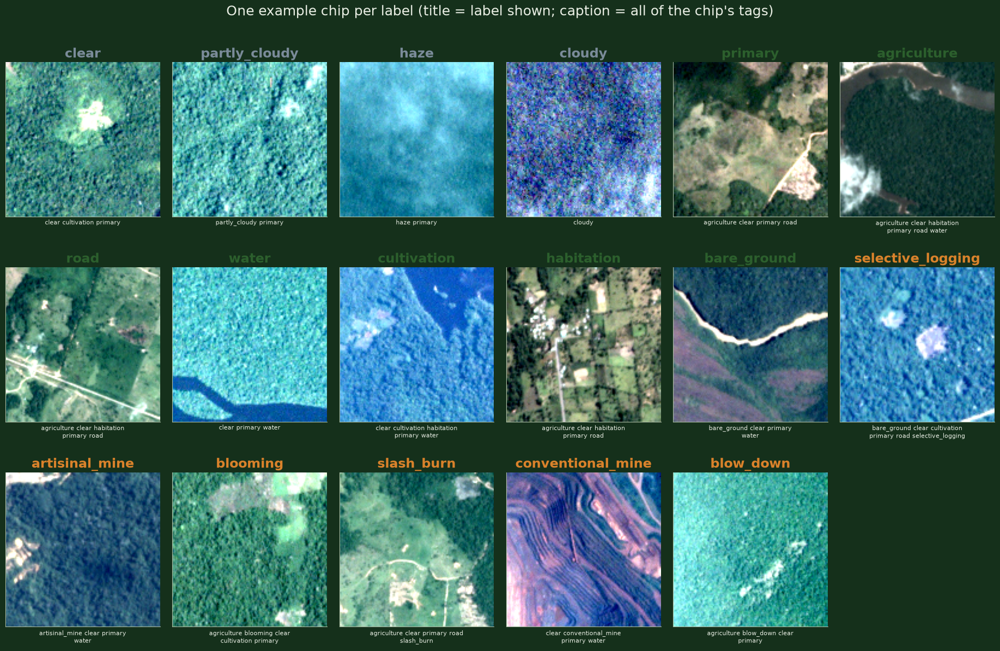

In [142]:
# One example chip per label — Run2 EDA 05_example_chip_per_label
import textwrap

# Pick n clear-preferring positives for label l
def pick_eda(l, n=1, preferClear=True):
    # Set `pos` = np.where(Yeda[:, Leda[l]] == 1)[0]
    pos = np.where(Yeda[:, Leda[l]] == 1)[0]
    # Conditional branch
    if preferClear and l not in WEATHER_EDA and "clear" in Leda:
        # Set `clear` = pos[Yeda[pos, Leda["clear"]] == 1]
        clear = pos[Yeda[pos, Leda["clear"]] == 1]
        # Set `pos` = clear if len(clear) >= n else pos
        pos = clear if len(clear) >= n else pos
    # Return result to caller
    return rngEda.choice(pos, min(n, len(pos)), replace=False)

# Order: weather, then common by freq, then rare by freq
showOrder = WEATHER_EDA + sorted(COMMON_EDA, key=lambda l: -freqEda[Leda[l]]) + sorted(RARE_EDA, key=lambda l: -freqEda[Leda[l]])
# Set `cols` = 6
cols = 6
# Set `rows` = int(np.ceil(len(showOrder) / cols))
rows = int(np.ceil(len(showOrder) / cols))
# Set `fig, axes` = ...
fig, axes = plt.subplots(rows, cols, figsize=(3.1 * cols, 4.0 * rows))
# Iterate over this sequence
for ax, l in zip(axes.flat, showOrder):
    # Set `i` = pick_eda(l)[0]
    i = pick_eda(l)[0]
    # Run this pipeline step
    ax.imshow(stretch_eda(rgb_chip(chip_eda(i))))
    # Run this pipeline step
    ax.set_title(l, color=GROUP_COLOR[group_eda(l)], fontweight="bold")
    # Run this pipeline step
    ax.set_xlabel("\n".join(textwrap.wrap(tags_eda(i), 30)), fontsize=8)
    # Run this pipeline step
    ax.set_xticks([]); ax.set_yticks([])
# Iterate over this sequence
for ax in axes.flat[len(showOrder):]:
    # Run this pipeline step
    ax.axis("off")
# Run this pipeline step
fig.suptitle("One example chip per label (title = label shown; caption = all of the chip's tags)", y=1.0)
# Run this pipeline step
plt.tight_layout(); save_eda(fig, "05_example_chip_per_label.png"); plt.show(); plt.close()

saved 06_rgb_nir_ndvi.png


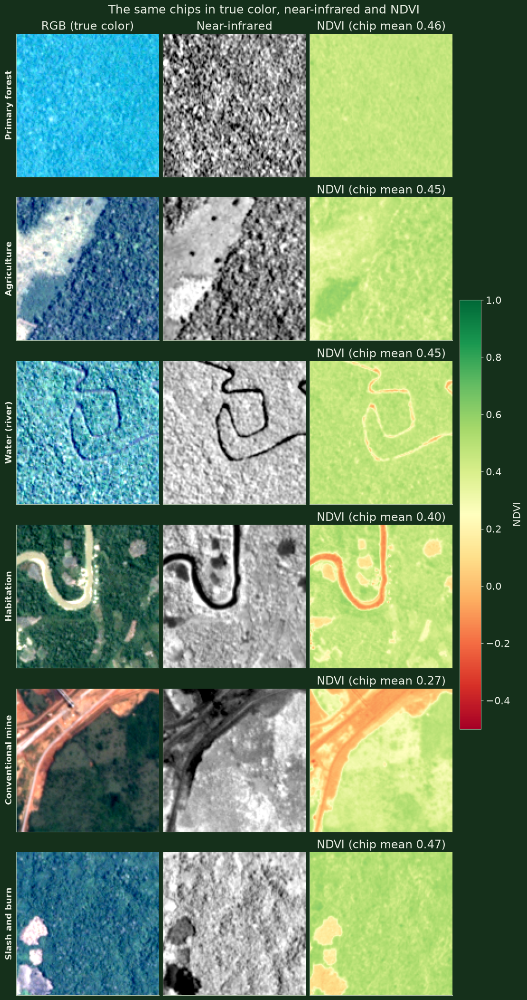

In [143]:
# Multi-row RGB / NIR / NDVI examples — Run2 EDA 06_rgb_nir_ndvi
# Skip when the cache is JPG-placeholder mode (NIR/NDVI not real)
metaEda = metaEda if "metaEda" in dir() else (json.load(open(f"{edaCache}/cache_meta.json")) if os.path.exists(f"{edaCache}/cache_meta.json") else {})
# Conditional branch
if metaEda.get("jpg_mode"):
    # Print status / metrics to the notebook
    print("JPG cache — skipping 06_rgb_nir_ndvi multi-row panel.")
# Else branch
else:
    # Clear chips with label l and none of the exclude labels
    def pure_eda(l, exclude):
        # Set `pos` = np.where(Yeda[:, Leda[l]] == 1)[0]
        pos = np.where(Yeda[:, Leda[l]] == 1)[0]
        # Conditional branch
        if "clear" in Leda:
            # Set `pos` = pos[Yeda[pos, Leda["clear"]] == 1]
            pos = pos[Yeda[pos, Leda["clear"]] == 1]
        # Set `ex` = [Leda[e] for e in exclude if e in Leda and e != l]
        ex = [Leda[e] for e in exclude if e in Leda and e != l]
        # Conditional branch
        if ex:
            # Set `pos` = pos[Yeda[np.ix_(pos, ex)].sum(1) == 0]
            pos = pos[Yeda[np.ix_(pos, ex)].sum(1) == 0]
        # Return result to caller
        return pos

    # Set `examples` = [
    examples = [
        # Continuation of the multi-line expression
        ("primary", "Primary forest", ["agriculture", "road", "habitation", "water", "cultivation"] + RARE_EDA),
        # Continuation of the multi-line expression
        ("agriculture", "Agriculture", ["water"] + RARE_EDA),
        # Continuation of the multi-line expression
        ("water", "Water (river)", RARE_EDA),
        # Continuation of the multi-line expression
        ("habitation", "Habitation", RARE_EDA),
        # Continuation of the multi-line expression
        ("conventional_mine", "Conventional mine", []),
        # Continuation of the multi-line expression
        ("slash_burn", "Slash and burn", []),
    # Continuation of the multi-line expression
    ]
    # Keep only labels that exist in this cache
    examples = [e for e in examples if e[0] in Leda]
    # Set `fig, axes` = ...
    fig, axes = plt.subplots(len(examples), 3, figsize=(11, 3.5 * len(examples)), layout="constrained")
    # Set `axes` = np.atleast_2d(axes)
    axes = np.atleast_2d(axes)
    # Set `im` = None
    im = None
    # Iterate over this sequence
    for r, (l, title, ex) in enumerate(examples):
        # Set `pos` = pure_eda(l, ex)
        pos = pure_eda(l, ex)
        # Set `pos` = pos if len(pos) else np.where(Yeda[:, Leda[l]] ...
        pos = pos if len(pos) else np.where(Yeda[:, Leda[l]] == 1)[0]
        # Set `x` = chip_eda(int(rngEda.choice(pos)))
        x = chip_eda(int(rngEda.choice(pos)))
        # Run this pipeline step
        axes[r, 0].imshow(stretch_eda(rgb_chip(x)))
        # Run this pipeline step
        axes[r, 1].imshow(stretch_eda(np.asarray(x[3], dtype=np.float32)), cmap="gray")
        # Set `im` = axes[r, 2].imshow(ndvi_chip(x), cmap="RdYlGn", ...
        im = axes[r, 2].imshow(ndvi_chip(x), cmap="RdYlGn", vmin=-0.5, vmax=1.0)
        # Run this pipeline step
        axes[r, 0].set_ylabel(title, fontsize=13, fontweight="bold")
        # Set `heads` = ["RGB (true color)", "Near-infrared", "NDVI"] i...
        heads = ["RGB (true color)", "Near-infrared", "NDVI"] if r == 0 else ["", "", "NDVI"]
        # Iterate over this sequence
        for c in range(3):
            # Set `t` = heads[c] + (f" (chip mean {ndvi_chip(x).mean():...
            t = heads[c] + (f" (chip mean {ndvi_chip(x).mean():.2f})" if c == 2 else "")
            # Run this pipeline step
            axes[r, c].set_title(t); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    # Conditional branch
    if im is not None:
        # Run this pipeline step
        fig.colorbar(im, ax=axes[:, 2], shrink=0.6, label="NDVI")
    # Run this pipeline step
    fig.suptitle("The same chips in true color, near-infrared and NDVI")
    # Run this pipeline step
    save_eda(fig, "06_rgb_nir_ndvi.png"); plt.show(); plt.close()

In [144]:
# Ladder training settings (local paths instead of Colab Drive)
from pathlib import Path  # resolve repo-local run_ladder.py

# 128 px TIF project (reuse matched / main TIF cache)
ladderRoot128 = os.environ.get("AMAZON_ROOT_TIF", os.environ.get("AMAZON_ROOT", "/mnt/c/Users/legen/amazon_project"))
# Optional 256 px cache root
ladderRoot256 = os.environ.get("AMAZON_ROOT_256", f"{ladderRoot128}_256")
# Where ladder run artifacts are written
ladderRuns = os.environ.get("AMAZON_LADDER_RUNS", f"{ladderRoot128}/ladder_runs")
# Assign `os.makedirs(ladderRuns, exist_ok` ← True)
os.makedirs(ladderRuns, exist_ok=True)

# Channel index presets matching the 5-channel cache layout (R,G,B,NIR,NDVI)
RGB, RGBN, RGBNV = [0, 1, 2], [0, 1, 2, 3], [0, 1, 2, 3, 4]
# Default seed plus two repeats for variability
SEEDS = [42, 1, 2]

# Path to run_ladder.py next to this notebook
ladderScript = str(root / "run_ladder.py") if "root" in dir() and hasattr(root, "__truediv__") else None
# Prefer repo-local run_ladder.py beside the notebook file
_nbDir = Path("/mnt/c/Users/legen/Documents/github/Amazon Deforestation")
# Assign `ladderScript` ← str(_nbDir / "run_ladder.py")
ladderScript = str(_nbDir / "run_ladder.py")
# Assert required condition
assert os.path.exists(ladderScript), f"Missing {ladderScript} — extract it from Run2/Ladder_Training_v2 first."

# Load run_ladder as a module for run_name / full_settings helpers
_spec = importlib.util.spec_from_file_location("run_ladder", ladderScript)
# Assign `rl` ← importlib.util.module_from_spec(_spec)
rl = importlib.util.module_from_spec(_spec)
# Execute: _spec.loader.exec_module(rl)
_spec.loader.exec_module(rl)

# Define `name_of`
def name_of(s):
    # Execute: """File stem a settings dict will be saved under."""
    """File stem a settings dict will be saved under."""
    # Return value to caller
    return rl.run_name(rl.full_settings(s))

# Define `with_seeds`
def with_seeds(s, seeds=SEEDS):
    # Execute: """One copy of a settings dict per seed."""
    """One copy of a settings dict per seed."""
    # Return value to caller
    return [dict(s, seed=k) for k in seeds]

# Define `finished_ladder`
def finished_ladder():
    # Execute: """Names of runs that already have *_probs.npz under ladderRuns."""
    """Names of runs that already have *_probs.npz under ladderRuns."""
    # If-branch
    if not os.path.isdir(ladderRuns):
        # Return value to caller
        return []
    # Return value to caller
    return sorted(f[:-10] for f in os.listdir(ladderRuns) if f.endswith("_probs.npz"))

# Define `run_plan`
def run_plan(runs):
    # Execute: """Train the listed settings in order; finished runs are skipped by run_ladder.py."""
    """Train the listed settings in order; finished runs are skipped by run_ladder.py."""
    # Assign `need256` ← any(rl.full_settings(s)["res"] != "128" for s in runs)
    need256 = any(rl.full_settings(s)["res"] != "128" for s in runs)
    # If-branch
    if need256:
        # Assert required condition
        assert os.path.exists(f"{ladderRoot256}/cache/X.npy"), (
            # Continues prior expression: f"256 px cache missing at {ladderRoot256}/cache/X.npy — build it or drop 256/pro
            f"256 px cache missing at {ladderRoot256}/cache/X.npy — build it or drop 256/prog runs.")
    # Assign `planPath` ← f"{ladderRoot128}/ladder_plan.json"
    planPath = f"{ladderRoot128}/ladder_plan.json"
    # Open context manager
    with open(planPath, "w") as f:
        # Assign `json.dump({"runs": runs}, f, indent` ← 1)
        json.dump({"runs": runs}, f, indent=1)
    # Log to notebook output
    print("plan:", [name_of(s) for s in runs])
    # Assign `cmd` ← [sys.executable, "-u", ladderScript
    cmd = [sys.executable, "-u", ladderScript,
           # Continues prior expression: "--root128", ladderRoot128, "--runs", ladderRuns, "--plan", planPath
           "--root128", ladderRoot128, "--runs", ladderRuns, "--plan", planPath,
           # Continues prior expression: "--work", f"{ladderRoot128}/ladder_work"]
           "--work", f"{ladderRoot128}/ladder_work"]
    # If-branch
    if need256:
        # Assign `cmd +` ← ["--root256", ladderRoot256]
        cmd += ["--root256", ladderRoot256]
    # Assign `p` ← subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.S…
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    # Loop over items
    for line in p.stdout:
        # Log to notebook output
        print(line, end="")
    # Execute: p.wait()
    p.wait()
    # Log to notebook output
    print("exit code:", p.returncode)

# Log to notebook output
print("finished ladder runs so far:", finished_ladder())
# Log to notebook output
print("128 cache:", os.path.exists(f"{ladderRoot128}/cache/X.npy"), "| 256 cache:", os.path.exists(f"{ladderRoot256}/cache/X.npy"))

finished ladder runs so far: []
128 cache: True | 256 cache: False


In [145]:
# Optional: install TorchGeo only if you will train Sentinel-2 pretrained runs
installTorchgeo = False  # set True once on the GPU machine before group4 / S2 runs
# If-branch
if installTorchgeo:
    # Execute: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torchgeo"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torchgeo"])
    # Log to notebook output
    print("torchgeo installed")
# Else branch
else:
    # Log to notebook output
    print("Skipping torchgeo install (set installTorchgeo=True for Sentinel-2 weights)")

Skipping torchgeo install (set installTorchgeo=True for Sentinel-2 weights)


In [146]:
# Ladder groups 1–6 + ResNet-34 (from Ladder_Training_v2)
# Set runLadder=True to actually train; default False so the unified notebook stays safe to Run-All
runLadder = False

# Assign `group1` ← [
group1 = [
    # Continues prior expression: dict(arch="scratch", chans=RGB)
    dict(arch="scratch", chans=RGB),
    # Continues prior expression: dict(arch="scratch", chans=RGBNV)
    dict(arch="scratch", chans=RGBNV),
    # Continues prior expression: dict(arch="scratch", chans=RGB, epochs=28)
    dict(arch="scratch", chans=RGB, epochs=28),
    # Continues prior expression: dict(arch="scratch", chans=RGBNV, epochs=28)
    dict(arch="scratch", chans=RGBNV, epochs=28),
# Continuation of the multi-line expression
]
# Assign `group2` ← (
group2 = (
    # Continues prior expression: with_seeds(dict(arch="resnet18", pretrain="none", chans=RGB))
    with_seeds(dict(arch="resnet18", pretrain="none", chans=RGB))
  # Continues prior expression: + [dict(arch="resnet18", pretrain="none", chans=RGBN)
  + [dict(arch="resnet18", pretrain="none", chans=RGBN),
     # Continues prior expression: dict(arch="resnet18", pretrain="none", chans=RGB, epochs=28)
     dict(arch="resnet18", pretrain="none", chans=RGB, epochs=28),
     # Continues prior expression: dict(arch="resnet18", pretrain="none", chans=RGBN, epochs=28)]
     dict(arch="resnet18", pretrain="none", chans=RGBN, epochs=28)]
# Continuation of the multi-line expression
)
# Assign `IMNET` ← dict(arch="resnet18", pretrain="imagenet", chans=RGB)
IMNET = dict(arch="resnet18", pretrain="imagenet", chans=RGB)
# Assign `group3` ← (
group3 = (
    # Continues prior expression: with_seeds(IMNET)
    with_seeds(IMNET)
  # Continues prior expression: + [dict(IMNET, chans=RGBN)
  + [dict(IMNET, chans=RGBN),
     # Continues prior expression: dict(IMNET, lr=3e-4)
     dict(IMNET, lr=3e-4),
     # Continues prior expression: dict(IMNET, balance=False)
     dict(IMNET, balance=False),
     # Continues prior expression: dict(IMNET, pool="avgmax")]
     dict(IMNET, pool="avgmax")]
# Continuation of the multi-line expression
)
# Assign `S2` ← dict(arch="resnet18", pretrain="sentinel2", chans=RGB)
S2 = dict(arch="resnet18", pretrain="sentinel2", chans=RGB)
# Assign `group4` ← (
group4 = (
    # Continues prior expression: [dict(S2), dict(S2, chans=RGBN)]
    [dict(S2), dict(S2, chans=RGBN)]
  # Continues prior expression: + with_seeds(dict(S2, s2_weights="rgb"))
  + with_seeds(dict(S2, s2_weights="rgb"))
  # Continues prior expression: + [dict(S2, s2_weights="rgb", norm="s2match")]
  + [dict(S2, s2_weights="rgb", norm="s2match")]
# Continuation of the multi-line expression
)
# Assign `group5` ← (
group5 = (
    # Continues prior expression: with_seeds(dict(IMNET, res="256"))
    with_seeds(dict(IMNET, res="256"))
  # Continues prior expression: + [dict(arch="efficientnet_b0", pretrain="imagenet", chans=RGB)
  + [dict(arch="efficientnet_b0", pretrain="imagenet", chans=RGB),
     # Continues prior expression: dict(arch="efficientnet_b0", pretrain="imagenet", chans=RGB, res="256")]
     dict(arch="efficientnet_b0", pretrain="imagenet", chans=RGB, res="256")]
# Continuation of the multi-line expression
)
# Assign `group6` ← (
group6 = (
    # Continues prior expression: with_seeds(dict(IMNET, res="prog", hi_epochs=3))
    with_seeds(dict(IMNET, res="prog", hi_epochs=3))
  # Continues prior expression: + [dict(S2, s2_weights="rgb", res="prog", hi_epochs=3)]
  + [dict(S2, s2_weights="rgb", res="prog", hi_epochs=3)]
# Continuation of the multi-line expression
)
# Assign `R34` ← dict(arch="resnet34", pretrain="imagenet", chans=RGB)
R34 = dict(arch="resnet34", pretrain="imagenet", chans=RGB)
# Assign `groupR34` ← (
groupR34 = (
    # Continues prior expression: with_seeds(dict(R34), SEEDS)
    with_seeds(dict(R34), SEEDS)
  # Continues prior expression: + with_seeds(dict(R34, res="256"), SEEDS)
  + with_seeds(dict(R34, res="256"), SEEDS)
# Continuation of the multi-line expression
)

# Status: planned vs finished
planned = []
# Loop over items
for gname in ("group1", "group2", "group3", "group4", "group5", "group6", "groupR34"):
    # Assign `planned +` ← [name_of(s) for s in globals()[gname]]
    planned += [name_of(s) for s in globals()[gname]]
# Assign `done` ← set(finished_ladder())
done = set(finished_ladder())
# Loop over items
for n in planned:
    # Log to notebook output
    print(("done   " if n in done else "pending"), n)
# Log to notebook output
print(f"\n{sum(n in done for n in planned)}/{len(planned)} finished")

# If-branch
if runLadder:
    # Train in the same order as the original training notebook
    for g in (group1, group2, group3, group4, group5, group6, groupR34):
        # Execute: run_plan(g)
        run_plan(g)
# Else branch
else:
    # Log to notebook output
    print("\nrunLadder=False — not launching training. Set runLadder=True on a GPU machine to train.")

pending scratch_none_rgb
pending scratch_none_rgbnv
pending scratch_none_rgb_e28
pending scratch_none_rgbnv_e28
pending r18_none_rgb
pending r18_none_rgb_s1
pending r18_none_rgb_s2
pending r18_none_rgbn
pending r18_none_rgb_e28
pending r18_none_rgbn_e28
pending r18_imnet_rgb
pending r18_imnet_rgb_s1
pending r18_imnet_rgb_s2
pending r18_imnet_rgbn
pending r18_imnet_rgb_lr0.0003
pending r18_imnet_rgb_nobal
pending r18_imnet_rgb_avgmax
pending r18_s2_rgb
pending r18_s2_rgbn
pending r18_s2_rgb_s2rgb
pending r18_s2_rgb_s2rgb_s1
pending r18_s2_rgb_s2rgb_s2
pending r18_s2_rgb_s2rgb_s2norm
pending r18_imnet_rgb_256
pending r18_imnet_rgb_256_s1
pending r18_imnet_rgb_256_s2
pending effb0_imnet_rgb
pending effb0_imnet_rgb_256
pending r18_imnet_rgb_prog3
pending r18_imnet_rgb_prog3_s1
pending r18_imnet_rgb_prog3_s2
pending r18_s2_rgb_prog3_s2rgb
pending r34_imnet_rgb
pending r34_imnet_rgb_s1
pending r34_imnet_rgb_s2
pending r34_imnet_rgb_256
pending r34_imnet_rgb_256_s1
pending r34_imnet_rgb_256_s

In [147]:
# Training curves for any finished ladder run
curveName = "r18_imnet_rgb"  # change to any finished run stem
# Assign `histPath` ← f"{ladderRuns}/{curveName}_history.json"
histPath = f"{ladderRuns}/{curveName}_history.json"
# Assign `setPath` ← f"{ladderRuns}/{curveName}_settings.json"
setPath = f"{ladderRuns}/{curveName}_settings.json"
# If-branch
if os.path.exists(histPath) and os.path.exists(setPath):
    # Assign `h` ← json.load(open(histPath))
    h = json.load(open(histPath))
    # Assign `s` ← json.load(open(setPath))
    s = json.load(open(setPath))
    # Log to notebook output
    print(f"{curveName}: best epoch {s.get('best_epoch')} | {s.get('n_params', 0)/1e6:.1f}M params | "
          # Continues prior expression: f"{s.get('train_s_per_epoch', 0):.0f} s/epoch | GPU {s.get('gpu', '?')}")
          f"{s.get('train_s_per_epoch', 0):.0f} s/epoch | GPU {s.get('gpu', '?')}")
    # Assign `fig, ax` ← plt.subplots(1, 2, figsize=(10, 3.2), constrained_layout=True)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), constrained_layout=True)
    # Assign `ep` ← [e["epoch"] for e in h]
    ep = [e["epoch"] for e in h]
    # Assign `ax[0].plot(ep, [e["train_loss"] for e in h], marker` ← "o"); ax[0].set(title="Training loss", xlabel="epoch")
    ax[0].plot(ep, [e["train_loss"] for e in h], marker="o"); ax[0].set(title="Training loss", xlabel="epoch")
    # Assign `ax[1].plot(ep, [e["val_macro_f2_fixed"] for e in h], marker` ← "o"); ax[1].set(title="Val macro F2 @0.2", xlabel="epoch")
    ax[1].plot(ep, [e["val_macro_f2_fixed"] for e in h], marker="o"); ax[1].set(title="Val macro F2 @0.2", xlabel="epoch")
    # Execute: fig.suptitle(curveName); plt.show(); plt.close()
    fig.suptitle(curveName); plt.show(); plt.close()
# Else branch
else:
    # Log to notebook output
    print(f"No history for {curveName} under {ladderRuns}")

No history for r18_imnet_rgb under /mnt/c/Users/legen/amazon_project_tif/ladder_runs


In [148]:
# Ladder Grad-CAM deck: ImageNet vs no-pretraining on the same deforestation chips
# Needs ladder settings cell (rl, ladderRuns, ladderRoot128) and finished r18_* runs.
# Distinct from matched C-vs-D Grad-CAM earlier in the notebook.
# Set `runLadderCam` = True
runLadderCam = False
# Set `camModels` = {"ImageNet (final)": "r18_imnet_rgb", "No pretraining": "...
camModels = {"ImageNet (final)": "r18_imnet_rgb", "No pretraining": "r18_none_rgb"}
# Set `camLabels` = ["slash_burn", "selective_logging"]
camLabels = ["slash_burn", "selective_logging"]
# Set `nHit, nMiss` = 1, 1
nHit, nMiss = 1, 1
# Set `camChips` = None
camChips = None  # or [(chipIdx, label), ...]

# Conditional branch
if not runLadderCam:
    # Print status / metrics to the notebook
    print("Skipped ladder Grad-CAM (set runLadderCam=True).")
# Alternate conditional branch
elif "rl" not in dir():
    # Print status / metrics to the notebook
    print("Run the ladder training settings cell first.")
# Else branch
else:
    # Set `missing` = [r for r in camModels.values() if not os.path.exists(f"{l...
    missing = [r for r in camModels.values() if not os.path.exists(f"{ladderRuns}/{r}.pt")]
    # Conditional branch
    if missing:
        # Print status / metrics to the notebook
        print("Missing ladder weights:", missing)
    # Else branch
    else:
        # Run this pipeline step
        os.environ["LADDER_OFFLINE_TEST"] = "1"
        # Set `deckCam` = dict(bg="
        deckCam = dict(bg="#15301B", text="#E8EDE3", muted="#A9BBA3", moss="#97BC62", orange="#E8923A")
        # Run this pipeline step
        mpl.rcParams.update({"figure.facecolor": deckCam["bg"], "axes.facecolor": deckCam["bg"],
                             # Continuation of the multi-line expression
                             "savefig.facecolor": deckCam["bg"], "text.color": deckCam["text"],
                             # Run this pipeline step
                             "font.size": 14, "savefig.dpi": 200, "savefig.bbox": "tight"})
        # Set `niceCam` = {"slash_burn": "slash-and-burn", "selective_logging": "se...
        niceCam = {"slash_burn": "slash-and-burn", "selective_logging": "selective logging",
                   # Continuation of the multi-line expression
                   "artisinal_mine": "artisanal mine", "conventional_mine": "conventional mine"}
        # Set `c128` = f"{ladderRoot128}/cache"
        c128 = f"{ladderRoot128}/cache"
        # Set `labelsCam` = json.load(open(f"{c128}/labels.json"))
        labelsCam = json.load(open(f"{c128}/labels.json"))
        # Set `yCam` = np.load(f"{c128}/Y.npy")
        yCam = np.load(f"{c128}/Y.npy")
        # Set `stCam` = np.load(f"{c128}/stats.npz")
        stCam = np.load(f"{c128}/stats.npz")
        # Set `xCam` = np.load(f"{c128}/X.npy", mmap_mode="r")
        xCam = np.load(f"{c128}/X.npy", mmap_mode="r")
        # Set `namesCam` = json.load(open(f"{c128}/names.json"))
        namesCam = json.load(open(f"{c128}/names.json"))

        # Define function `load_ladder_model`
        def load_ladder_model(run):
            # Set `meta` = json.load(open(f"{ladderRuns}/{run}_settings.json"))
            meta = json.load(open(f"{ladderRuns}/{run}_settings.json"))
            # Set `s` = rl.full_settings({k: meta[k] for k in rl.DEFAULTS if k in...
            s = rl.full_settings({k: meta[k] for k in rl.DEFAULTS if k in meta})
            # Set `m` = rl.build_model(s, len(labelsCam))
            m = rl.build_model(s, len(labelsCam))
            # Run this pipeline step
            m.load_state_dict(torch.load(f"{ladderRuns}/{run}.pt", map_location="cpu"))
            # Return result to caller
            return m.eval(), s

        # Define function `ladder_gradcam`
        def ladder_gradcam(model, s, i, label):
            # Set `ch` = s["chans"]
            ch = s["chans"]
            # Set `x` = torch.tensor(np.asarray(xCam[i][ch], dtype=np.float32))[N...
            x = torch.tensor(np.asarray(xCam[i][ch], dtype=np.float32))[None]
            # Set `x` = (x - torch.tensor(stCam["mean"][ch]).view(1, -1, 1, 1)) /...
            x = (x - torch.tensor(stCam["mean"][ch]).view(1, -1, 1, 1)) / torch.tensor(stCam["std"][ch]).view(1, -1, 1, 1)
            # Set `acts` = {}
            acts = {}
            # Set `layer` = model.features[6]
            layer = model.features[6]  # ResNet layer3 (8x8 at 128 px)
            # Set `h` = layer.register_forward_hook(lambda mod, inp, out: acts.__...
            h = layer.register_forward_hook(lambda mod, inp, out: acts.__setitem__("a", out))
            # Set `logit` = model(x)[0, labelsCam.index(label)]
            logit = model(x)[0, labelsCam.index(label)]
            # Run this pipeline step
            h.remove()
            # Set `A` = acts["a"]
            A = acts["a"]
            # Set `g` = torch.autograd.grad(logit, A)[0]
            g = torch.autograd.grad(logit, A)[0]
            # Set `cam` = F.relu((g.mean((2, 3), keepdim=True) * A).sum(1, keepdim=...
            cam = F.relu((g.mean((2, 3), keepdim=True) * A).sum(1, keepdim=True))
            # Set `cam` = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", al...
            cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0].detach().numpy()
            # Return result to caller
            return cam / (cam.max() + 1e-8), float(torch.sigmoid(logit.detach()))

        # Define function `natural_rgb_cam`
        def natural_rgb_cam(i, lo=2, hi=98):
            # Set `img` = np.transpose(np.asarray(xCam[i][:3], dtype=np.float32), (...
            img = np.transpose(np.asarray(xCam[i][:3], dtype=np.float32), (1, 2, 0))
            # Set `out` = np.empty_like(img)
            out = np.empty_like(img)
            # Iterate over this sequence
            for c in range(3):
                # Set `a, b` = np.percentile(img[..., c], [lo, hi])
                a, b = np.percentile(img[..., c], [lo, hi])
                # Run this pipeline step
                out[..., c] = np.clip((img[..., c] - a) / (b - a + 1e-6), 0, 1)
            # Return result to caller
            return out ** 0.9

        # Set `modelsCam` = {k: load_ladder_model(r) for k, r in camModels.items()}
        modelsCam = {k: load_ladder_model(r) for k, r in camModels.items()}
        # Set `chips` = camChips
        chips = camChips
        # Conditional branch
        if chips is None:
            # Set `d` = np.load(f"{ladderRuns}/{list(camModels.values())[0]}_prob...
            d = np.load(f"{ladderRuns}/{list(camModels.values())[0]}_probs.npz")
            # Set `tp, ty, tidx` = d["test_probs"], d["test_y"], d["test_idx"]
            tp, ty, tidx = d["test_probs"], d["test_y"], d["test_idx"]
            # Set `chips` = []
            chips = []
            # Iterate over this sequence
            for l in camLabels:
                # Set `j` = labelsCam.index(l)
                j = labelsCam.index(l)
                # Set `pos` = np.where(ty[:, j] == 1)[0]
                pos = np.where(ty[:, j] == 1)[0]
                # Set `order` = pos[np.argsort(-tp[pos, j])]
                order = pos[np.argsort(-tp[pos, j])]
                # Update `chips` += [(int(tidx[k]), l, "found") for k in order[:nHit]]
                chips += [(int(tidx[k]), l, "found") for k in order[:nHit]]
                # Update `chips` += [(int(tidx[k]), l, "missed") for k in order[::-1][
                chips += [(int(tidx[k]), l, "missed") for k in order[::-1][:nMiss]]
        # Else branch
        else:
            # Set `chips` = [(i, l, "") for i, l in chips]
            chips = [(i, l, "") for i, l in chips]

        # Set `cols` = 1 + len(modelsCam)
        cols = 1 + len(modelsCam)
        # Assign `fig, axes` ← plt.subplots(len(chips), cols, figsize=(3.4 * cols, 3.5 *...
        fig, axes = plt.subplots(len(chips), cols, figsize=(3.4 * cols, 3.5 * len(chips)), squeeze=False)
        # Iterate over this sequence
        for r, (i, l, kind) in enumerate(chips):
            # Set `rgb` = natural_rgb_cam(i)
            rgb = natural_rgb_cam(i)
            # Draw or configure plot elements
            axes[r, 0].imshow(rgb)
            # Draw or configure plot elements
            axes[r, 0].set_ylabel(f"{niceCam.get(l, l)}\n({kind} by final)" if kind else niceCam.get(l, l),
                                  # Keyword/field `fontsize`
                                  fontsize=13, color=deckCam["orange"], fontweight="bold")
            # Iterate over this sequence
            for c, (mname, (m, s)) in enumerate(modelsCam.items(), start=1):
                # Set `cam, p` = ladder_gradcam(m, s, i, l)
                cam, p = ladder_gradcam(m, s, i, l)
                # Draw or configure plot elements
                axes[r, c].imshow(rgb)
                # Draw or configure plot elements
                axes[r, c].imshow(cam, cmap="inferno", alpha=0.5, vmin=0, vmax=1)
                # Draw or configure plot elements
                axes[r, c].set_xlabel(f"p = {p:.2f}", fontsize=13, color=deckCam["text"])
                # Conditional branch
                if r == 0: axes[r, c].set_title(mname, fontsize=15, color=deckCam["text"])
            # Conditional branch
            if r == 0: axes[r, 0].set_title("chip", fontsize=15, color=deckCam["text"])
            # Iterate over this sequence
            for ax in axes[r]:
                # Draw or configure plot elements
                ax.set_xticks([]); ax.set_yticks([])
                # Iterate over this sequence
                for sp_ in ax.spines.values(): sp_.set_visible(False)
            # Print status / metrics to the notebook
            print(f"row {r + 1}: chip {i} ({namesCam[i]}), label {l}, {kind}")
        # Run this pipeline step
        fig.tight_layout()
        # Ensure output directory exists
        os.makedirs(f"{ladderRuns}/eval", exist_ok=True)
        # Save, show, and close the figure
        fig.savefig(f"{ladderRuns}/eval/deck_gradcam.png"); plt.show(); plt.close()

Skipped ladder Grad-CAM (set runLadderCam=True).


In [149]:
# Ladder evaluation: load runs + metric helpers (adapted from Ladder_Evaluation_v2)
import re

# Paths (same defaults as the ladder training section)
evalRuns = os.environ.get("AMAZON_LADDER_RUNS", f"{os.environ.get('AMAZON_ROOT_TIF', os.environ.get('AMAZON_ROOT', '/mnt/c/Users/legen/amazon_project'))}/ladder_runs")
# Assign `evalCache` ← os.environ.get("AMAZON_ROOT_TIF", os.environ.get("AMAZON_ROOT", "…
evalCache = os.environ.get("AMAZON_ROOT_TIF", os.environ.get("AMAZON_ROOT", "/mnt/c/Users/legen/amazon_project")) + "/cache"
# Assign `evalOut` ← f"{evalRuns}/eval_shared"
evalOut = f"{evalRuns}/eval_shared"
# Assign `os.makedirs(evalOut, exist_ok` ← True)
os.makedirs(evalOut, exist_ok=True)
# Assign `N_BOOT` ← 1000
N_BOOT = 1000
# Assign `REFERENCE` ← "r18_imnet_rgb"
REFERENCE = "r18_imnet_rgb"
# Assign `FINAL` ← "r18_imnet_rgb"
FINAL = "r18_imnet_rgb"

# Display helper outside Jupyter
try:
    # Execute: display
    display
# Catch import/runtime errors
except NameError:
    # Assign `display` ← lambda df: print(df.to_string() if hasattr(df, "to_string") else …
    display = lambda df: print(df.to_string() if hasattr(df, "to_string") else df)

# If-branch
if not os.path.exists(f"{evalCache}/labels.json"):
    # Log to notebook output
    print(f"Missing labels at {evalCache}/labels.json — build the TIF cache first.")
# Else branch
else:
    # Assign `labelsEv` ← json.load(open(f"{evalCache}/labels.json"))
    labelsEv = json.load(open(f"{evalCache}/labels.json"))
    # Assign `WEATHER` ← [w for w in ["clear", "partly_cloudy", "haze", "cloudy"] if w in …
    WEATHER = [w for w in ["clear", "partly_cloudy", "haze", "cloudy"] if w in labelsEv]
    # Assign `DEFOR` ← [l for l in ["selective_logging", "slash_burn", "artisinal_mine",…
    DEFOR = [l for l in ["selective_logging", "slash_burn", "artisinal_mine", "conventional_mine"] if l in labelsEv]
    # Assign `WI` ← [labelsEv.index(l) for l in WEATHER]
    WI = [labelsEv.index(l) for l in WEATHER]
    # Assign `LI` ← [j for j in range(len(labelsEv)) if j not in WI]
    LI = [j for j in range(len(labelsEv)) if j not in WI]
    # Assign `DI` ← [labelsEv.index(l) for l in DEFOR]
    DI = [labelsEv.index(l) for l in DEFOR]

    # Discover finished runs
    RUN = {}
    # Assign `ORDER` ← []
    ORDER = []
    # Loop over items
    for p in sorted(glob.glob(f"{evalRuns}/*_probs.npz")):
        # Assign `name` ← os.path.basename(p)[:-10]
        name = os.path.basename(p)[:-10]
        # Assign `metaPath` ← f"{evalRuns}/{name}_settings.json"
        metaPath = f"{evalRuns}/{name}_settings.json"
        # Assign `d` ← np.load(p)
        d = np.load(p)
        # Assign `RUN[name]` ← {
        histPath = f"{evalRuns}/{name}_history.json"
        # Run this pipeline step
        RUN[name] = {
            # Dict entry `"probs"`
            "probs": d,
            # Dict entry `"ty"`
            "ty": d["test_y"], "tp": d["test_probs"], "tidx": d["test_idx"],
            # Dict entry `"vy"`
            "vy": d["val_y"], "vp": d["val_probs"],
            # Dict entry `"meta"`
            "meta": json.load(open(metaPath)) if os.path.exists(metaPath) else {},
            # Training curves when the run saved history
            "hist": json.load(open(histPath)) if os.path.exists(histPath) else [],
        # Continuation of the multi-line expression
        }
        # Execute: ORDER.append(name)
        ORDER.append(name)
    # Log to notebook output
    print(f"Loaded {len(ORDER)} ladder runs from {evalRuns}")

    # Assign `GRID` ← np.arange(0.02, 0.81, 0.01)
    GRID = np.arange(0.02, 0.81, 0.01)
    # Set `THRESHOLDS` = "shared" # or "per_label"
    THRESHOLDS = "shared"  # or "per_label"

    
    # Alias used by Run2 Ladder_Evaluation snippets
    labels = labelsEv

    # TP / FP / FN counts per label
    def counts(y, pred):
        # Set `yb` = y.astype(bool)
        yb = y.astype(bool)
        # Set `pr` = pred.astype(bool)
        pr = pred.astype(bool)
        # Return result to caller
        return (pr & yb).sum(0), (pr & ~yb).sum(0), (~pr & yb).sum(0)

    # F2 from TP/FP/FN vectors
    def f2_from(tp, fp, fn):
        # Return result to caller
        return 5 * tp / (5 * tp + 4 * fn + fp + 1e-9)

    # Per-label metric table
    def per_label_df(y, pred):
        # Set `tp, fp, fn` = ...
        tp, fp, fn = counts(y, pred)
        # Return result to caller
        return pd.DataFrame({
            # Keyword/field `F2`
            "F2": f2_from(tp, fp, fn),
            # Keyword/field `precision`
            "precision": tp / np.maximum(tp + fp, 1),
            # Keyword/field `recall`
            "recall": tp / np.maximum(tp + fn, 1),
            # Keyword/field `positives`
            "positives": y.sum(0).astype(int),
        # Continuation of the multi-line expression
        }, index=labelsEv)

    # Nice names for deck axis labels
    NICE = {"selective_logging": "selective logging", "slash_burn": "slash-and-burn",
            # Keyword/field `artisinal_mine`
            "artisinal_mine": "artisanal mine", "conventional_mine": "conventional mine",
            # Keyword/field `bare_ground`
            "bare_ground": "bare ground", "blow_down": "blow down", "partly_cloudy": "partly cloudy"}

    # Define `tune`
    def tune(y, p):
        # Execute: """Land-label thresholds on validation; weather uses argmax (no threshold)."""
        """Land-label thresholds on validation; weather uses argmax (no threshold)."""
        # Assign `thr` ← np.full(p.shape[1], np.nan)
        thr = np.full(p.shape[1], np.nan)
        # If-branch
        if THRESHOLDS == "shared":
            # Assign `scores` ← []
            scores = []
            # Loop over items
            for t in GRID:
                # Assign `pred` ← p[:, LI] >= t
                pred = p[:, LI] >= t
                # Assign `pos` ← y[:, LI] == 1
                pos = y[:, LI] == 1
                # Assign `tp` ← (pred & pos).sum(0); fp = (pred & ~pos).sum(0); fn = (~pred & pos…
                tp = (pred & pos).sum(0); fp = (pred & ~pos).sum(0); fn = (~pred & pos).sum(0)
                # Execute: scores.append(np.mean(5 * tp / (5 * tp + 4 * fn + fp + 1e-9)))
                scores.append(np.mean(5 * tp / (5 * tp + 4 * fn + fp + 1e-9)))
            # Assign `thr[LI]` ← GRID[int(np.argmax(scores))]
            thr[LI] = GRID[int(np.argmax(scores))]
            # Return value to caller
            return thr
        # Loop over items
        for j in LI:
            # Assign `pred` ← p[:, j:j + 1] >= GRID[None, :]
            pred = p[:, j:j + 1] >= GRID[None, :]
            # Assign `pos` ← y[:, j:j + 1] == 1
            pos = y[:, j:j + 1] == 1
            # Assign `tp` ← (pred & pos).sum(0); fp = (pred & ~pos).sum(0); fn = (~pred & pos…
            tp = (pred & pos).sum(0); fp = (pred & ~pos).sum(0); fn = (~pred & pos).sum(0)
            # Assign `thr[j]` ← GRID[(5 * tp / (5 * tp + 4 * fn + fp + 1e-9)).argmax()]
            thr[j] = GRID[(5 * tp / (5 * tp + 4 * fn + fp + 1e-9)).argmax()]
        # Return value to caller
        return thr

    # Define `predict`
    def predict(p, thr):
        # Execute: """Exactly one weather label (argmax) + every land label above its threshold."""
        """Exactly one weather label (argmax) + every land label above its threshold."""
        # Assign `pred` ← np.zeros(p.shape, dtype=bool)
        pred = np.zeros(p.shape, dtype=bool)
        # If-branch
        if WI:
            # Assign `pred[np.arange(len(p)), np.array(WI)[p[:, WI].argmax(1)]]` ← True
            pred[np.arange(len(p)), np.array(WI)[p[:, WI].argmax(1)]] = True
        # Assign `pred[:, LI]` ← p[:, LI] >= thr[LI]
        pred[:, LI] = p[:, LI] >= thr[LI]
        # Return value to caller
        return pred

    # Define `metrics_ev`
    def metrics_ev(y, p, pred):
        # Execute: """Summary metrics used in the ladder eval tables."""
        """Summary metrics used in the ladder eval tables."""
        # Assign `yb, pr` ← y.astype(bool), pred.astype(bool)
        yb, pr = y.astype(bool), pred.astype(bool)
        # Assign `tp` ← (pr & yb).sum(0); fp = (pr & ~yb).sum(0); fn = (~pr & yb).sum(0)
        tp = (pr & yb).sum(0); fp = (pr & ~yb).sum(0); fn = (~pr & yb).sum(0)
        # Assign `f2` ← 5 * tp / (5 * tp + 4 * fn + fp + 1e-9)
        f2 = 5 * tp / (5 * tp + 4 * fn + fp + 1e-9)
        # Assign `out` ← {
        out = {
            # Dict entry `"macro_F2"`
            "macro_F2": float(np.nanmean(f2)),
            # Dict entry `"land_macro_F2"`
            "land_macro_F2": float(np.nanmean(f2[LI])) if LI else float("nan"),
            # Dict entry `"defor_F2"`
            "defor_F2": float(np.nanmean(f2[DI])) if DI else float("nan"),
            # Dict entry `"defor_precision"`
            "defor_precision": float(np.nanmean(tp[DI] / (tp[DI] + fp[DI] + 1e-9))) if DI else float("nan"),
            # Dict entry `"defor_recall"`
            "defor_recall": float(np.nanmean(tp[DI] / (tp[DI] + fn[DI] + 1e-9))) if DI else float("nan"),
            # Dict entry `"samples_F2"`
            "samples_F2": float(fbeta_score(yb, pr, beta=2, average="samples", zero_division=0)),
            # Dict entry `"hamming_loss"`
            "hamming_loss": float((pr != yb).mean()),
        # Continuation of the multi-line expression
        }
        # If-branch
        if DI:
            # Assign `out["defor_PR_AUC"]` ← float(np.mean([average_precision_score(yb[:, j], p[:, j]) for j i…
            out["defor_PR_AUC"] = float(np.mean([average_precision_score(yb[:, j], p[:, j]) for j in DI]))
        # Return value to caller
        return out

    # Define `evaluate`
    def evaluate(name):
        # Execute: """Tune on val, predict on test/val, return metrics + preds."""
        """Tune on val, predict on test/val, return metrics + preds."""
        # Assign `r` ← RUN[name]
        r = RUN[name]
        # Assign `thr` ← tune(r["vy"], r["vp"])
        thr = tune(r["vy"], r["vp"])
        # Assign `predTe` ← predict(r["tp"], thr)
        predTe = predict(r["tp"], thr)
        # Assign `predVa` ← predict(r["vp"], thr)
        predVa = predict(r["vp"], thr)
        # Return value to caller
        return {
            # Dict entry `"thr"`
            "thr": thr,
            # Dict entry `"test"`
            "test": metrics_ev(r["ty"], r["tp"], predTe),
            # Dict entry `"val"`
            "val": metrics_ev(r["vy"], r["vp"], predVa),
            # Dict entry `"pred"`
            "pred": {"test": predTe, "val": predVa},
            # Per-label tables (Run2 Ladder_Evaluation)
            "per_label": {"test": per_label_df(r["ty"], predTe), "val": per_label_df(r["vy"], predVa)},
        # Continuation of the multi-line expression
        }

    # Define `family`
    def family(name):
        # Execute: """Readable model family from the run name."""
        """Readable model family from the run name."""
        # Execute: if name.startswith("scratch"): return "Scratch CNN"
        if name.startswith("scratch"): return "Scratch CNN"
        # Execute: if name.startswith("effb0"): return "EfficientNet-B0 (ImageNet)"
        if name.startswith("effb0"): return "EfficientNet-B0 (ImageNet)"
        # Execute: if "_s2rgb" in name: return "ResNet-18 Sentinel-2 RGB-only"
        if "_s2rgb" in name: return "ResNet-18 Sentinel-2 RGB-only"
        # Return value to caller
        return {"r18_none": "ResNet-18 no pretraining", "r18_imnet": "ResNet-18 ImageNet",
                # Dict entry `"r18_s2"`
                "r18_s2": "ResNet-18 Sentinel-2 13-band", "r34_imnet": "ResNet-34 ImageNet"
                # Continues prior expression: }.get("_".join(name.split("_")[:2]), "other")
                }.get("_".join(name.split("_")[:2]), "other")

    # If-branch
    if ORDER:
        # Assign `rows` ← []
        rows = []
        # Loop over items
        for n in ORDER:
            # Assign `e, s` ← evaluate(n), RUN[n]["meta"]
            e, s = evaluate(n), RUN[n]["meta"]
            # Execute: rows.append({"run": n, "family": family(n)
            rows.append({"run": n, "family": family(n),
                         # Dict entry `"val_defor_F2"`
                         "val_defor_F2": e["val"]["defor_F2"], "val_macro_F2": e["val"]["macro_F2"],
                         # Dict entry `"test_defor_F2"`
                         "test_defor_F2": e["test"]["defor_F2"], "test_macro_F2": e["test"]["macro_F2"],
                         # Dict entry `"test_land_macro_F2"`
                         "test_land_macro_F2": e["test"]["land_macro_F2"], "test_samples_F2": e["test"]["samples_F2"],
                         # Dict entry `"params_M"`
                         "params_M": round(s["n_params"] / 1e6, 1) if s.get("n_params") else None})
        # Assign `tableEv` ← pd.DataFrame(rows).set_index("run").round(4)
        tableEv = pd.DataFrame(rows).set_index("run").round(4)
        # Execute: tableEv.to_csv(f"{evalOut}/results_all_runs.csv")
        tableEv.to_csv(f"{evalOut}/results_all_runs.csv")
        # Set `sortedVal` = tableEv.sort_values("val_defor_F2", ascending=F...
        sortedVal = tableEv.sort_values("val_defor_F2", ascending=False)
        # Run this pipeline step
        sortedVal.to_csv(f"{evalOut}/results_sorted_by_val.csv")
        # Show rich output in Jupyter
        display(tableEv)
        # Print status / metrics to the notebook
        print("Top 10 by validation deforestation F2:")
        # Print status / metrics to the notebook
        display(sortedVal[["family", "val_defor_F2", "val_macro_F2", "test_defor_F2", "test_macro_F2"]].head(10))
    # Else branch
    else:
        # Log to notebook output
        print("No ladder runs to evaluate yet.")

Loaded 0 ladder runs from /mnt/c/Users/legen/amazon_project_tif/ladder_runs
No ladder runs to evaluate yet.


In [150]:
# Seed variability + cloudy rule + simple ensemble (ladder eval extras)
if "ORDER" in dir() and ORDER:
    # Define `seed_groups`
    def seed_groups():
        # Execute: """Group runs that differ only by a _sN seed suffix."""
        """Group runs that differ only by a _sN seed suffix."""
        # Assign `groups` ← {}
        groups = {}
        # Loop over items
        for n in ORDER:
            # Assign `base` ← re.sub(r"_s\d+$", "", n)
            base = re.sub(r"_s\d+$", "", n)
            # Execute: groups.setdefault(base, []).append(n)
            groups.setdefault(base, []).append(n)
        # Return value to caller
        return {b: ns for b, ns in groups.items() if len(ns) > 1 and b in RUN}

    # Define `seed_summary`
    def seed_summary():
        # Assign `rows` ← []
        rows = []
        # Loop over items
        for base, ns in seed_groups().items():
            # Assign `row` ← {"configuration": base, "seeds": len(ns)}
            row = {"configuration": base, "seeds": len(ns)}
            # Loop over items
            for split in ("val", "test"):
                # Loop over items
                for k in ("defor_F2", "macro_F2"):
                    # Assign `v` ← np.array([evaluate(n)[split][k] for n in ns])
                    v = np.array([evaluate(n)[split][k] for n in ns])
                    # Assign `row[f"{split}_{k}"]` ← f"{v.mean():.3f} ± {v.std(ddof=1):.3f}"
                    row[f"{split}_{k}"] = f"{v.mean():.3f} ± {v.std(ddof=1):.3f}"
            # Execute: rows.append(row)
            rows.append(row)
        # Return value to caller
        return pd.DataFrame(rows).set_index("configuration") if rows else pd.DataFrame()

    # Assign `seeds` ← seed_summary()
    seeds = seed_summary()
    # If-branch
    if len(seeds):
        # Execute: seeds.to_csv(f"{evalOut}/seed_summary.csv")
        seeds.to_csv(f"{evalOut}/seed_summary.csv")
        # Show rich output in Jupyter
        display(seeds)
    # Else branch
    else:
        # Log to notebook output
        print("No multi-seed groups yet.")

    # Define `cloudy_rule`
    def cloudy_rule(pred):
        # Execute: """If cloudy is predicted, zero out all land labels (dataset logic)."""
        """If cloudy is predicted, zero out all land labels (dataset logic)."""
        # Assign `out` ← pred.copy()
        out = pred.copy()
        # If-branch
        if "cloudy" not in labelsEv:
            # Return value to caller
            return out
        # Assign `ci` ← labelsEv.index("cloudy")
        ci = labelsEv.index("cloudy")
        # Assign `cloudy` ← out[:, ci]
        cloudy = out[:, ci]
        # Assign `out[cloudy]` ← False
        out[cloudy] = False
        # Assign `out[cloudy, ci]` ← True
        out[cloudy, ci] = True
        # Return value to caller
        return out

    # Demonstrate cloudy rule on FINAL if present
    if FINAL in RUN:
        # Assign `e0` ← evaluate(FINAL)
        e0 = evaluate(FINAL)
        # Assign `pred0` ← e0["pred"]["test"]
        pred0 = e0["pred"]["test"]
        # Assign `pred1` ← cloudy_rule(pred0)
        pred1 = cloudy_rule(pred0)
        # Assign `m0` ← metrics_ev(RUN[FINAL]["ty"], RUN[FINAL]["tp"], pred0)
        m0 = metrics_ev(RUN[FINAL]["ty"], RUN[FINAL]["tp"], pred0)
        # Assign `m1` ← metrics_ev(RUN[FINAL]["ty"], RUN[FINAL]["tp"], pred1)
        m1 = metrics_ev(RUN[FINAL]["ty"], RUN[FINAL]["tp"], pred1)
        # Log to notebook output
        print("FINAL without cloudy rule:", {k: round(m0[k], 4) for k in ("macro_F2", "defor_F2", "samples_F2")})
        # Log to notebook output
        print("FINAL with cloudy rule:   ", {k: round(m1[k], 4) for k in ("macro_F2", "defor_F2", "samples_F2")})

    # Logit-average ensemble of available members
    MEMBERS = [n for n in ["r18_imnet_rgb_prog3", "r18_s2_rgb_s2rgb", "r18_imnet_rgb"] if n in RUN]
    # If-branch
    if len(MEMBERS) >= 2:
        # Average test probabilities across members (same test_idx assumed)
        tp = np.mean([RUN[n]["tp"] for n in MEMBERS], axis=0)
        # Assign `vp` ← np.mean([RUN[n]["vp"] for n in MEMBERS], axis=0)
        vp = np.mean([RUN[n]["vp"] for n in MEMBERS], axis=0)
        # Assign `thr` ← tune(RUN[MEMBERS[0]]["vy"], vp)
        thr = tune(RUN[MEMBERS[0]]["vy"], vp)
        # Assign `pred` ← predict(tp, thr)
        pred = predict(tp, thr)
        # Log to notebook output
        print("Ensemble", MEMBERS, "->", metrics_ev(RUN[MEMBERS[0]]["ty"], tp, pred))
    # Else branch
    else:
        # Log to notebook output
        print("Need ≥2 of the ensemble members trained to build the ensemble.")
# Else branch
else:
    # Log to notebook output
    print("Ladder eval load cell did not find runs — skip extras.")

Ladder eval load cell did not find runs — skip extras.


In [151]:
# Head-to-head comparison questions — full Run2 Ladder_Evaluation QUESTIONS
# Needs ladder eval load + seed extras (ORDER, RUN, evaluate, boot_defor or local bootstrap).
if "ORDER" not in dir() or not ORDER:
    # Print status / metrics to the notebook
    print("No ladder runs — skip QUESTIONS comparisons.")
# Else branch
else:
    # Set `QUESTIONS` = {
    QUESTIONS = {
        # Continuation of the multi-line expression
        "Input channels (does NIR / NDVI help?)": [
            # Continuation of the multi-line expression
            ("scratch_none_rgb", "scratch_none_rgbnv", "Scratch CNN: + NIR + NDVI"),
            # Continuation of the multi-line expression
            ("scratch_none_rgb_e28", "scratch_none_rgbnv_e28", "Scratch CNN, 28 epochs: + NIR + NDVI"),
            # Continuation of the multi-line expression
            ("r18_none_rgb", "r18_none_rgbn", "ResNet-18 no pretraining: + NIR"),
            # Continuation of the multi-line expression
            ("r18_none_rgb_e28", "r18_none_rgbn_e28", "ResNet-18 no pretraining, 28 epochs: + NIR"),
            # Continuation of the multi-line expression
            ("r18_imnet_rgb", "r18_imnet_rgbn", "ResNet-18 ImageNet: + NIR"),
            # Continuation of the multi-line expression
            ("r18_s2_rgb", "r18_s2_rgbn", "ResNet-18 Sentinel-2 13-band: + NIR"),
        # Continuation of the multi-line expression
        ],
        # Continuation of the multi-line expression
        "Architecture and pretraining": [
            # Continuation of the multi-line expression
            ("scratch_none_rgb", "r18_none_rgb", "ResNet-18 vs. scratch CNN (both untrained)"),
            # Continuation of the multi-line expression
            ("r18_none_rgb", "r18_imnet_rgb", "ImageNet pretraining vs. none"),
            # Continuation of the multi-line expression
            ("r18_none_rgb_e28", "r18_imnet_rgb", "ImageNet (14 ep) vs. no pretraining (28 ep)"),
            # Continuation of the multi-line expression
            ("r18_imnet_rgb", "r18_s2_rgb", "Sentinel-2 13-band vs. ImageNet"),
            # Continuation of the multi-line expression
            ("r18_s2_rgb", "r18_s2_rgb_s2rgb", "Sentinel-2 RGB-only vs. 13-band weights"),
            # Continuation of the multi-line expression
            ("r18_imnet_rgb", "r18_s2_rgb_s2rgb", "Sentinel-2 RGB-only vs. ImageNet"),
            # Continuation of the multi-line expression
            ("r18_s2_rgb_s2rgb", "r18_s2_rgb_s2rgb_s2norm", "Sentinel-2 RGB-only: matched input scaling"),
            # Continuation of the multi-line expression
            ("r18_imnet_rgb", "effb0_imnet_rgb", "EfficientNet-B0 vs. ResNet-18 (ImageNet, 128 px)"),
        # Continuation of the multi-line expression
        ],
        # Continuation of the multi-line expression
        "Training length and training choices": [
            # Continuation of the multi-line expression
            ("scratch_none_rgb", "scratch_none_rgb_e28", "Scratch CNN RGB: 28 vs. 14 epochs"),
            # Continuation of the multi-line expression
            ("scratch_none_rgbnv", "scratch_none_rgbnv_e28", "Scratch CNN RGB+NIR+NDVI: 28 vs. 14 epochs"),
            # Continuation of the multi-line expression
            ("r18_none_rgb", "r18_none_rgb_e28", "ResNet-18 no pretraining RGB: 28 vs. 14 epochs"),
            # Continuation of the multi-line expression
            ("r18_none_rgbn", "r18_none_rgbn_e28", "ResNet-18 no pretraining RGB+NIR: 28 vs. 14 epochs"),
            # Continuation of the multi-line expression
            ("r18_imnet_rgb", "r18_imnet_rgb_lr0.0003", "ImageNet: learning rate 3e-4 vs. 1e-3"),
            # Continuation of the multi-line expression
            ("r18_imnet_rgb", "r18_imnet_rgb_nobal", "ImageNet: no imbalance handling"),
            # Continuation of the multi-line expression
            ("r18_imnet_rgb", "r18_imnet_rgb_avgmax", "ImageNet: average + max pooling"),
        # Continuation of the multi-line expression
        ],
        # Keyword/field `Resolution`
        "Resolution": [
            # Continuation of the multi-line expression
            ("r18_imnet_rgb", "r18_imnet_rgb_256", "ResNet-18 ImageNet: 256 vs. 128 px"),
            # Continuation of the multi-line expression
            ("effb0_imnet_rgb", "effb0_imnet_rgb_256", "EfficientNet-B0: 256 vs. 128 px"),
            # Continuation of the multi-line expression
            ("r18_imnet_rgb", "r18_imnet_rgb_prog3", "ResNet-18 ImageNet: progressive vs. 128 px"),
            # Continuation of the multi-line expression
            ("r18_imnet_rgb_256", "r18_imnet_rgb_prog3", "ResNet-18 ImageNet: progressive vs. 256 px"),
            # Continuation of the multi-line expression
            ("r18_s2_rgb_s2rgb", "r18_s2_rgb_prog3_s2rgb", "Sentinel-2 RGB-only: progressive vs. 128 px"),
            # Continuation of the multi-line expression
            ("r18_imnet_rgb_prog3", "r18_s2_rgb_prog3_s2rgb", "Progressive: Sentinel-2 RGB-only vs. ImageNet"),
        # Continuation of the multi-line expression
        ],
    # Continuation of the multi-line expression
    }

    # Bootstrap mean difference in deforestation F2 (B - A) on a split
    def boot_defor(a, b, split="test", n=N_BOOT):
        # Conditional branch
        if a not in RUN or b not in RUN:
            # Return result to caller
            return None
        # Set `ya` = RUN[a]["ty" if split == "test" else "vy"]
        ya = RUN[a]["ty" if split == "test" else "vy"]
        # Set `pa` = evaluate(a)["pred"][split]
        pa = evaluate(a)["pred"][split]
        # Set `pb` = evaluate(b)["pred"][split]
        pb = evaluate(b)["pred"][split]
        # Set `rng` = np.random.RandomState(0)
        rng = np.random.RandomState(0)
        # Set `diffs` = []
        diffs = []
        # Set `idxArr` = np.arange(len(ya))
        idxArr = np.arange(len(ya))
        # Iterate over this sequence
        for _ in range(n):
            # Set `samp` = rng.choice(idxArr, len(idxArr), replace=True)
            samp = rng.choice(idxArr, len(idxArr), replace=True)
            # Define function `f2`
            def f2(y, pred):
                # Set `yb, pr` = ...
                yb, pr = y.astype(bool), pred.astype(bool)
                # Set `tp` = (pr & yb).sum(0); fp = (pr & ~yb).sum(0); fn = ...
                tp = (pr & yb).sum(0); fp = (pr & ~yb).sum(0); fn = (~pr & yb).sum(0)
                # Set `f` = 5 * tp / (5 * tp + 4 * fn + fp + 1e-9)
                f = 5 * tp / (5 * tp + 4 * fn + fp + 1e-9)
                # Return result to caller
                return float(np.nanmean(f[DI])) if DI else float("nan")
            # Run this pipeline step
            diffs.append(f2(ya[samp], pb[samp]) - f2(ya[samp], pa[samp]))
        # Set `diffs` = np.array(diffs)
        diffs = np.array(diffs)
        # Return result to caller
        return dict(diff=float(diffs.mean()), ci_low=float(np.percentile(diffs, 2.5)),
                    # Continuation of the multi-line expression
                    ci_high=float(np.percentile(diffs, 97.5)),
                    # Continuation of the multi-line expression
                    verdict=("B better" if np.percentile(diffs, 2.5) > 0
                             # Continuation of the multi-line expression
                             else "A better" if np.percentile(diffs, 97.5) < 0
                             # Continuation of the multi-line expression
                             else "not significant"))

    # Walk every question pair; skip pairs whose runs are not trained yet
    rows = []
    # Iterate over this sequence
    for group, pairs in QUESTIONS.items():
        # Print status / metrics to the notebook
        print(f"\n=== {group} ===")
        # Iterate over this sequence
        for a, b, lab in pairs:
            # Conditional branch
            if a not in RUN or b not in RUN:
                # Print status / metrics to the notebook
                print(f"skip (missing run): {lab}")
                # Control flow: continue
                continue
            # Set `bv, bt` = ...
            bv, bt = boot_defor(a, b, "val"), boot_defor(a, b, "test")
            # Run this pipeline step
            rows.append({
                # Keyword/field `group`
                "group": group, "question": lab, "A": a, "B": b,
                # Continuation of the multi-line expression
                "A val": evaluate(a)["val"]["defor_F2"], "B val": evaluate(b)["val"]["defor_F2"],
                # Continuation of the multi-line expression
                "Δ val": bv["diff"], "val 95% CI": f"[{bv['ci_low']:+.3f}, {bv['ci_high']:+.3f}]",
                # Continuation of the multi-line expression
                "val verdict": bv["verdict"],
                # Continuation of the multi-line expression
                "Δ test": bt["diff"], "test 95% CI": f"[{bt['ci_low']:+.3f}, {bt['ci_high']:+.3f}]",
                # Continuation of the multi-line expression
                "test verdict": bt["verdict"],
            # Continuation of the multi-line expression
            })
            # Print status / metrics to the notebook
            print(f"{lab}: Δtest={bt['diff']:+.3f} [{bt['ci_low']:+.3f}, {bt['ci_high']:+.3f}] ({bt['verdict']})")
    # Conditional branch
    if rows:
        # Set `comparisons` = pd.DataFrame(rows).set_index(["group", "questio...
        comparisons = pd.DataFrame(rows).set_index(["group", "question"]).round(3)
        # Run this pipeline step
        comparisons.to_csv(f"{evalOut}/comparisons.csv")
        # Run this pipeline step
        pd.DataFrame(rows).to_csv(f"{evalOut}/head_to_head.csv", index=False)
        # Print status / metrics to the notebook
        display(comparisons)

    # Optional pairwise deep-dive (change pairA / pairB as needed)
    pairA, pairB = "r18_s2_rgb_s2rgb", "r18_s2_rgb_prog3_s2rgb"
    # Conditional branch
    if pairA in RUN and pairB in RUN and "per_label" in evaluate(pairA):
        # Print status / metrics to the notebook
        print(f"\nDetail {pairA} vs {pairB}")
        # Print status / metrics to the notebook
        display(boot_defor(pairA, pairB, "val"))
        # Print status / metrics to the notebook
        display(boot_defor(pairA, pairB, "test"))
        # Set `pa` = evaluate(pairA)["per_label"]["test"]
        pa = evaluate(pairA)["per_label"]["test"]
        # Set `pb` = evaluate(pairB)["per_label"]["test"]
        pb = evaluate(pairB)["per_label"]["test"]
        # Print status / metrics to the notebook
        display(pb[["F2"]] - pa[["F2"]])

No ladder runs — skip QUESTIONS comparisons.


In [152]:
# Ladder eval deck figures (rare-per-split, seed spread, forest plots, look-alike)
# Needs ladder evaluation cells above (ORDER, RUN, evaluate, seed_groups, boot_defor, DEFOR/DI).
# Conditional branch
if "ORDER" not in dir() or not ORDER:
    # Print status / metrics to the notebook
    print("No ladder runs loaded — skip eval deck figures.")
# Else branch
else:
    # Conditional branch
    if "DECK" not in dir():
        # Set `DECK` = dict(bg="
        DECK = dict(bg="#15301B", panel="#1F4426", text="#E8EDE3", muted="#A9BBA3",
                    # Keyword/field `grid`
                    grid="#3A5E40", moss="#97BC62", orange="#E8923A", sky="#8FB8C9", sand="#D8C9A3")
    # Set `niceEv` = {"selective_logging": "selective logging", "slash_burn": ...
    niceEv = {"selective_logging": "selective logging", "slash_burn": "slash-and-burn",
              # Continuation of the multi-line expression
              "artisinal_mine": "artisanal mine", "conventional_mine": "conventional mine",
              # Run this pipeline step
              "blooming": "blooming"}
    # Run this pipeline step
    mpl.rcParams.update({"figure.facecolor": DECK["bg"], "axes.facecolor": DECK["bg"],
                         # Continuation of the multi-line expression
                         "savefig.facecolor": DECK["bg"], "text.color": DECK["text"],
                         # Run this pipeline step
                         "axes.labelcolor": DECK["text"], "xtick.color": DECK["text"],
                         # Run this pipeline step
                         "ytick.color": DECK["text"], "axes.titlecolor": DECK["text"],
                         # Run this pipeline step
                         "axes.spines.top": False, "axes.spines.right": False,
                         # Run this pipeline step
                         "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 14})

    # Rare deforestation labels in each split
    yAll = np.load(f"{evalCache}/Y.npy")
    # Set `spl` = np.load(f"{evalCache}/splits.npz")
    spl = np.load(f"{evalCache}/splits.npz")
    # Conditional branch
    if DI:
        # Set `counts` = {s: yAll[spl[s]][:, DI].sum(0) for s in ("train", "val", ...
        counts = {s: yAll[spl[s]][:, DI].sum(0) for s in ("train", "val", "test")}
        # Assign `fig, ax` ← plt.subplots(figsize=(11, 5.4))
        fig, ax = plt.subplots(figsize=(11, 5.4))
        # Set `x` = np.arange(len(DEFOR)); w = 0.27
        x = np.arange(len(DEFOR)); w = 0.27
        # Iterate over this sequence
        for k, (s, col, name) in enumerate([("train", DECK["muted"], "train"),
                                            # Continuation of the multi-line expression
                                            ("val", DECK["moss"], "validation"),
                                            # Continuation of the multi-line expression
                                            ("test", DECK["orange"], "test")]):
            # Set `bars` = ax.bar(x + (k - 1) * w, counts[s], w, color=col, label=f"...
            bars = ax.bar(x + (k - 1) * w, counts[s], w, color=col, label=f"{name} ({len(spl[s]):,} chips)")
            # Iterate over this sequence
            for b in bars:
                # Draw or configure plot elements
                ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 3, f"{int(b.get_height())}",
                        # Keyword/field `ha`
                        ha="center", va="bottom", fontsize=14, color=DECK["text"])
        # Draw or configure plot elements
        ax.set_xticks(x); ax.set_xticklabels([niceEv.get(l, l) for l in DEFOR], fontsize=15)
        # Draw or configure plot elements
        ax.set_ylabel("chips with this label"); ax.legend(frameon=False, loc="upper right")
        # Draw or configure plot elements
        ax.set_ylim(top=max(counts["train"]) * 1.18); ax.grid(axis="y", alpha=0.4); ax.set_axisbelow(True)
        # Save, show, and close the figure
        fig.tight_layout(); fig.savefig(f"{evalOut}/deck_10a_rare_per_split.png"); plt.show(); plt.close()

    # Seed spread on test deforestation F2
    seedNames = {"r18_none_rgb": "ResNet-18, no pretraining", "r18_imnet_rgb": "ResNet-18, ImageNet",
                 # Continuation of the multi-line expression
                 "r18_s2_rgb_s2rgb": "ResNet-18, Sentinel-2 RGB", "r18_imnet_rgb_256": "ImageNet, 256 px",
                 # Run this pipeline step
                 "r18_imnet_rgb_prog3": "ImageNet, progressive"}
    # Set `groups` = seed_groups() if "seed_groups" in dir() else {}
    groups = seed_groups() if "seed_groups" in dir() else {}
    # Set `plotted` = [(b, lab) for b, lab in seedNames.items() if b in groups]
    plotted = [(b, lab) for b, lab in seedNames.items() if b in groups]
    # Conditional branch
    if plotted:
        # Assign `fig, ax` ← plt.subplots(figsize=(11, 4.8))
        fig, ax = plt.subplots(figsize=(11, 4.8))
        # Iterate over this sequence
        for k, (base, label) in enumerate(plotted):
            # Set `v` = np.array([evaluate(r)["test"]["defor_F2"] for r in groups...
            v = np.array([evaluate(r)["test"]["defor_F2"] for r in groups[base]])
            # Set `y` = len(plotted) - 1 - k
            y = len(plotted) - 1 - k
            # Draw or configure plot elements
            ax.plot([v.min(), v.max()], [y, y], color=DECK["muted"], lw=3, solid_capstyle="round")
            # Draw or configure plot elements
            ax.scatter(v, [y] * len(v), s=110, color=DECK["orange"], zorder=3, edgecolor=DECK["bg"])
            # Draw or configure plot elements
            ax.scatter([v.mean()], [y], marker="|", s=500, color=DECK["text"], zorder=4)
            # Draw or configure plot elements
            ax.text(v.max() + 0.006, y, f"{v.mean():.3f} ± {v.std(ddof=1):.3f}", va="center", fontsize=14)
        # Draw or configure plot elements
        ax.set_yticks(range(len(plotted))); ax.set_yticklabels([lab for _, lab in plotted][::-1], fontsize=15)
        # Draw or configure plot elements
        ax.set_xlabel("test deforestation F2 (dots = seeds; tick = mean)")
        # Set `lo, hi` = ax.get_xlim(); ax.set_xlim(lo, hi + 0.04)
        lo, hi = ax.get_xlim(); ax.set_xlim(lo, hi + 0.04)
        # Draw or configure plot elements
        ax.grid(axis="x", alpha=0.4); ax.set_axisbelow(True)
        # Save, show, and close the figure
        fig.tight_layout(); fig.savefig(f"{evalOut}/deck_10b_seed_spread.png"); plt.show(); plt.close()
    # Else branch
    else:
        # Print status / metrics to the notebook
        print("No multi-seed groups for seed-spread figure.")

    # Forest plots via boot_defor
    def forest_plot(rows, fname):
        # Set `items` = [r for r in rows if isinstance(r, str) or (isinstance(r, ...
        items = [r for r in rows if isinstance(r, str) or (isinstance(r, tuple) and r[0] in RUN and r[1] in RUN)]
        # Conditional branch
        if not items:
            # Print status / metrics to the notebook
            print("No rows available for", fname); return
        # Assign `fig, ax` ← plt.subplots(figsize=(11, 0.55 * len(items) + 1.2))
        fig, ax = plt.subplots(figsize=(11, 0.55 * len(items) + 1.2))
        # Set `y` = len(items) - 1
        y = len(items) - 1
        # Set `ylabels, yticks` = [], []
        ylabels, yticks = [], []
        # Iterate over this sequence
        for r in items:
            # Conditional branch
            if isinstance(r, str):
                # Draw or configure plot elements
                ax.text(-0.02, y, r, transform=ax.get_yaxis_transform(), ha="right", va="center",
                        # Keyword/field `fontsize`
                        fontsize=15, fontweight="bold", color=DECK["orange"])
                # Update `y` -= 1; continue
                y -= 1; continue
            # Set `a, b, label` = r
            a, b, label = r
            # Set `bt` = boot_defor(a, b, "test")
            bt = boot_defor(a, b, "test")
            # Conditional branch
            if bt is None:
                # Update `y` -= 1; continue
                y -= 1; continue
            # Set `col` = DECK["moss"] if bt["ci_low"] > 0 else DECK["orange"] if b...
            col = DECK["moss"] if bt["ci_low"] > 0 else DECK["orange"] if bt["ci_high"] < 0 else DECK["muted"]
            # Draw or configure plot elements
            ax.plot([bt["ci_low"], bt["ci_high"]], [y, y], color=col, lw=3, solid_capstyle="round")
            # Draw or configure plot elements
            ax.scatter([bt["diff"]], [y], s=110, color=col, zorder=3, edgecolor=DECK["bg"])
            # Draw or configure plot elements
            ax.text(bt["ci_high"] + 0.006, y, f"{bt['diff']:+.3f}", va="center", fontsize=14, color=col)
            # Run this pipeline step
            ylabels.append(label); yticks.append(y); y -= 1
        # Draw or configure plot elements
        ax.axvline(0, color=DECK["text"], lw=1, ls="--", alpha=0.7)
        # Draw or configure plot elements
        ax.set_yticks(yticks); ax.set_yticklabels(ylabels, fontsize=14)
        # Draw or configure plot elements
        ax.set_ylim(-0.7, len(items) - 0.3)
        # Set `lo, hi` = ax.get_xlim(); ax.set_xlim(lo, hi + 0.03)
        lo, hi = ax.get_xlim(); ax.set_xlim(lo, hi + 0.03)
        # Draw or configure plot elements
        ax.set_xlabel("change in test deforestation F2 (95% interval)")
        # Draw or configure plot elements
        ax.grid(axis="x", alpha=0.4); ax.set_axisbelow(True)
        # Save, show, and close the figure
        fig.tight_layout(); fig.savefig(f"{evalOut}/{fname}"); plt.show(); plt.close()

    # Run this pipeline step
    forest_plot([
        # Continuation of the multi-line expression
        "Pretraining",
        # Continuation of the multi-line expression
        ("r18_none_rgb", "r18_imnet_rgb", "ImageNet vs. no pretraining"),
        # Continuation of the multi-line expression
        ("r18_none_rgb_e28", "r18_imnet_rgb", "ImageNet vs. no pretraining at 28 epochs"),
        # Run this pipeline step
        "Training length",
        # Continuation of the multi-line expression
        ("scratch_none_rgb", "scratch_none_rgb_e28", "Scratch CNN: 28 vs. 14 epochs"),
        # Continuation of the multi-line expression
        ("r18_none_rgb", "r18_none_rgb_e28", "ResNet-18 untrained: 28 vs. 14 epochs"),
    # Continuation of the multi-line expression
    ], "deck_11_what_matters.png")
    # Run this pipeline step
    forest_plot([
        # Continuation of the multi-line expression
        "Near-infrared",
        # Continuation of the multi-line expression
        ("scratch_none_rgb", "scratch_none_rgbnv", "Scratch CNN: + NIR + NDVI"),
        # Continuation of the multi-line expression
        ("r18_none_rgb", "r18_none_rgbn", "ResNet-18 untrained: + NIR"),
        # Continuation of the multi-line expression
        ("r18_imnet_rgb", "r18_imnet_rgbn", "ResNet-18 ImageNet: + NIR"),
        # Run this pipeline step
        "Resolution and architecture",
        # Continuation of the multi-line expression
        ("r18_imnet_rgb", "r18_imnet_rgb_256", "256 px vs. 128 px"),
        # Continuation of the multi-line expression
        ("r18_imnet_rgb", "r18_imnet_rgb_prog3", "Progressive vs. 128 px"),
        # Continuation of the multi-line expression
        ("r18_imnet_rgb", "effb0_imnet_rgb", "EfficientNet-B0 vs. ResNet-18"),
    # Continuation of the multi-line expression
    ], "deck_12_what_didnt.png")

    # Look-alike pair: selective_logging missed as blooming vs true blooming
    if FINAL in RUN and "selective_logging" in labelsEv and "blooming" in labelsEv:
        # Set `pair` = None
        pair = None  # or (loggingIdx, bloomingIdx)
        # Set `xLook` = np.load(f"{evalCache}/X.npy", mmap_mode="r")
        xLook = np.load(f"{evalCache}/X.npy", mmap_mode="r")
        # Set `r` = RUN[FINAL]; ty, tp, tidx = r["ty"].astype(bool), r["tp"],...
        r = RUN[FINAL]; ty, tp, tidx = r["ty"].astype(bool), r["tp"], r["tidx"]
        # Set `pred` = evaluate(FINAL)["pred"]["test"].astype(bool)
        pred = evaluate(FINAL)["pred"]["test"].astype(bool)
        # Set `ja, jb` = labelsEv.index("selective_logging"), labelsEv.index("bloo...
        ja, jb = labelsEv.index("selective_logging"), labelsEv.index("blooming")
        # Set `jc` = labelsEv.index("clear") if "clear" in labelsEv else None
        jc = labelsEv.index("clear") if "clear" in labelsEv else None
        # Conditional branch
        if pair is None:
            # Set `c1` = np.where(ty[:, ja] & ~pred[:, ja] & pred[:, jb] & ~ty[:, ...
            c1 = np.where(ty[:, ja] & ~pred[:, ja] & pred[:, jb] & ~ty[:, jb])[0]
            # Conditional branch
            if not len(c1):
                # Set `c1` = np.where(ty[:, ja] & ~pred[:, ja] & ~ty[:, jb])[0]
                c1 = np.where(ty[:, ja] & ~pred[:, ja] & ~ty[:, jb])[0]
            # Set `c1` = c1[np.argsort(-tp[c1, jb])] if len(c1) else c1
            c1 = c1[np.argsort(-tp[c1, jb])] if len(c1) else c1
            # Set `mask2` = ty[:, jb] & pred[:, jb] & ~ty[:, ja]
            mask2 = ty[:, jb] & pred[:, jb] & ~ty[:, ja]
            # Conditional branch
            if jc is not None: mask2 = mask2 & ty[:, jc]
            # Set `c2` = np.where(mask2)[0]
            c2 = np.where(mask2)[0]
            # Set `c2` = c2[np.argsort(-tp[c2, jb])] if len(c2) else c2
            c2 = c2[np.argsort(-tp[c2, jb])] if len(c2) else c2
            # Conditional branch
            if len(c1) and len(c2):
                # Set `pair` = (int(tidx[c1[0]]), int(tidx[c2[0]]))
                pair = (int(tidx[c1[0]]), int(tidx[c2[0]]))
                # Set `k1, k2` = c1[0], c2[0]
                k1, k2 = c1[0], c2[0]
            # Else branch
            else:
                # Print status / metrics to the notebook
                print("No suitable look-alike chips; set pair=(loggingIdx, bloomingIdx).")
                # Set `pair` = None
                pair = None
        # Else branch
        else:
            # Set `k1, k2` = [int(np.where(tidx == i)[0][0]) for i in pair]
            k1, k2 = [int(np.where(tidx == i)[0][0]) for i in pair]
        # Conditional branch
        if pair is not None:
            # Define function `natural_rgb_look`
            def natural_rgb_look(x, lo=2, hi=98, gamma=0.9):
                # Set `img` = np.transpose(np.asarray(x[:3], dtype=np.float32), (1, 2, 0))
                img = np.transpose(np.asarray(x[:3], dtype=np.float32), (1, 2, 0))
                # Set `out` = np.empty_like(img)
                out = np.empty_like(img)
                # Iterate over this sequence
                for c in range(3):
                    # Set `lo_, hi_` = np.percentile(img[..., c], [lo, hi])
                    lo_, hi_ = np.percentile(img[..., c], [lo, hi])
                    # Run this pipeline step
                    out[..., c] = np.clip((img[..., c] - lo_) / (hi_ - lo_ + 1e-6), 0, 1)
                # Return result to caller
                return out ** gamma
            # Assign `fig, axes` ← plt.subplots(1, 2, figsize=(9, 5.1))
            fig, axes = plt.subplots(1, 2, figsize=(9, 5.1))
            # Iterate over this sequence
            for ax, k, head, sub, col in [
                    # Continuation of the multi-line expression
                    (axes[0], k1, "True: selective logging",
                     # Continuation of the multi-line expression
                     f"blooming p = {tp[k1, jb]:.2f}, selective logging p = {tp[k1, ja]:.2f}", DECK["orange"]),
                    # Continuation of the multi-line expression
                    (axes[1], k2, "True: blooming", f"blooming p = {tp[k2, jb]:.2f}", DECK["moss"])]:
                # Draw or configure plot elements
                ax.imshow(natural_rgb_look(xLook[int(tidx[k])])); ax.set_xticks([]); ax.set_yticks([])
                # Iterate over this sequence
                for sp in ax.spines.values():
                    # Run this pipeline step
                    sp.set_visible(True); sp.set_color(col); sp.set_linewidth(4)
                # Draw or configure plot elements
                ax.set_title(head, fontsize=16, color=col, fontweight="bold", pad=24)
                # Draw or configure plot elements
                ax.text(0.5, 1.02, sub, transform=ax.transAxes, ha="center", va="bottom",
                        # Keyword/field `fontsize`
                        fontsize=12, color=DECK["text"])
            # Save, show, and close the figure
            fig.tight_layout(); fig.savefig(f"{evalOut}/deck_lookalike.png"); plt.show(); plt.close()
            # Print status / metrics to the notebook
            print("look-alike chips (cache indices):", pair)

No ladder runs loaded — skip eval deck figures.


In [153]:
# Ladder eval presentation figures — overview / PR / cost / training curves (Run2 Ladder_Evaluation)
# Needs the ladder eval load cell (ORDER, RUN, evaluate, family, seed_groups, DEFOR, DI, LI, labelsEv).

# Conditional branch
if "ORDER" not in dir() or not ORDER:
    # Print status / metrics to the notebook
    print("No ladder runs loaded — skip overview/PR/cost/curves figures.")
# Else branch
else:
    # Alias OUT to the shared eval folder (Run2 used OUT)
    OUT = evalOut

    # Mean ± std deforestation F2 per configuration
    def config_scores(split):
        # Set `rows, done` = ...
        rows, done = [], set()
        # Iterate over this sequence
        for n in ORDER:
            # Set `base` = re.sub(r"_s\d+$", "", n)
            base = re.sub(r"_s\d+$", "", n)
            # Conditional branch
            if base in done or base not in RUN:
                # Control flow: continue
                continue
            # Run this pipeline step
            done.add(base)
            # Set `runs` = seed_groups().get(base, [base]) if "seed_groups...
            runs = seed_groups().get(base, [base]) if "seed_groups" in dir() else [base]
            # Set `runs` = [r for r in runs if r in RUN]
            runs = [r for r in runs if r in RUN]
            # Set `v` = np.array([evaluate(r)[split]["defor_F2"] for r ...
            v = np.array([evaluate(r)[split]["defor_F2"] for r in runs])
            # Run this pipeline step
            rows.append((base, family(base), v.mean(), v.std(ddof=1) if len(v) > 1 else 0.0, len(v)))
        # Return result to caller
        return rows

    # Set `FAM_COLORS` = {
    FAM_COLORS = {
        # Continuation of the multi-line expression
        "Scratch CNN": "#B5B9B2",
        # Continuation of the multi-line expression
        "ResNet-18 no pretraining": "#8C8C8C",
        # Continuation of the multi-line expression
        "ResNet-18 ImageNet": "#2C5F2D",
        # Continuation of the multi-line expression
        "ResNet-18 Sentinel-2 13-band": "#C9A227",
        # Continuation of the multi-line expression
        "ResNet-18 Sentinel-2 RGB-only": "#97BC62",
        # Continuation of the multi-line expression
        "EfficientNet-B0 (ImageNet)": "#4A7FA7",
        # Continuation of the multi-line expression
        "ResNet-34 ImageNet": "#2C5F2D",
        # Keyword/field `other`
        "other": "#666666",
    # Continuation of the multi-line expression
    }

    # --- fig_overview.png ---
    valRows, testRows = config_scores("val"), config_scores("test")
    # Conditional branch
    if valRows:
        # Set `fig, ax` = ...
        fig, ax = plt.subplots(figsize=(9, 0.38 * len(valRows) + 1.5))
        # Set `yy` = np.arange(len(valRows))[::-1]
        yy = np.arange(len(valRows))[::-1]
        # Iterate over this sequence
        for (n, fam, m, s, k), y in zip(valRows, yy):
            # Run this pipeline step
            ax.errorbar(m, y + 0.15, xerr=s, fmt="o", color=FAM_COLORS.get(fam, "#666"), mfc="white", capsize=3)
        # Iterate over this sequence
        for (n, fam, m, s, k), y in zip(testRows, yy):
            # Run this pipeline step
            ax.errorbar(m, y - 0.15, xerr=s, fmt="o", color=FAM_COLORS.get(fam, "#666"), capsize=3)
        # Run this pipeline step
        ax.set_yticks(yy)
        # Run this pipeline step
        ax.set_yticklabels([f"{n}" + (f"  (×{k} seeds)" if k > 1 else "") for n, _, _, _, k in valRows], fontsize=9)
        # Run this pipeline step
        ax.set_xlabel("deforestation F2   (open = validation, filled = test)")
        # Iterate over this sequence
        for fam, c in FAM_COLORS.items():
            # Conditional branch
            if any(r[1] == fam for r in valRows):
                # Run this pipeline step
                ax.plot([], [], "o", color=c, label=fam)
        # Run this pipeline step
        ax.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
        # Run this pipeline step
        ax.grid(axis="x", alpha=0.3)
        # Run this pipeline step
        ax.set_title("Deforestation F2 for every model")
        # Run this pipeline step
        fig.savefig(f"{OUT}/fig_overview.png"); plt.show(); plt.close()

    # --- fig_per_label_f2.png + fig_pr_curves_defor.png ---
    if REFERENCE in RUN and FINAL in RUN and "per_label" in evaluate(REFERENCE):
        # Set `a` = evaluate(REFERENCE)["per_label"]["test"]
        a = evaluate(REFERENCE)["per_label"]["test"]
        # Set `b` = evaluate(FINAL)["per_label"]["test"]
        b = evaluate(FINAL)["per_label"]["test"]
        # Set `order` = a["F2"].sort_values().index
        order = a["F2"].sort_values().index
        # Set `fig, ax` = ...
        fig, ax = plt.subplots(figsize=(10, 7))
        # Set `yy` = np.arange(len(order))
        yy = np.arange(len(order))
        # Run this pipeline step
        ax.barh(yy - 0.2, a.loc[order, "F2"], 0.4, label=REFERENCE, color="#B5B9B2")
        # Run this pipeline step
        ax.barh(yy + 0.2, b.loc[order, "F2"], 0.4, label=FINAL, color="#2C5F2D")
        # Run this pipeline step
        ax.set_yticks(yy)
        # Run this pipeline step
        ax.set_yticklabels([f"{l}  (n={a.loc[l, 'positives']})" for l in order])
        # Run this pipeline step
        ax.set_xlabel("test F2"); ax.legend(frameon=False); ax.set_title("Per-label test F2")
        # Run this pipeline step
        fig.savefig(f"{OUT}/fig_per_label_f2.png"); plt.show(); plt.close()
        # Run this pipeline step
        a.join(b, lsuffix="_" + REFERENCE, rsuffix="_" + FINAL).round(3).to_csv(f"{OUT}/per_label_test.csv")

        # Conditional branch
        if DEFOR:
            # Set `fig, axes` = ...
            fig, axes = plt.subplots(1, len(DEFOR), figsize=(4.2 * len(DEFOR), 4), sharey=True, constrained_layout=True)
            # Set `axes` = np.atleast_1d(axes)
            axes = np.atleast_1d(axes)
            # Iterate over this sequence
            for ax, l in zip(axes, DEFOR):
                # Set `j` = labelsEv.index(l)
                j = labelsEv.index(l)
                # Iterate over this sequence
                for n, c in [(REFERENCE, "#B5B9B2"), (FINAL, "#2C5F2D")]:
                    # Set `y, p` = ...
                    y, p = RUN[n]["ty"][:, j], RUN[n]["tp"][:, j]
                    # Conditional branch
                    if y.sum() == 0:
                        # Control flow: continue
                        continue
                    # Set `pr, rc, _` = ...
                    pr, rc, _ = precision_recall_curve(y, p)
                    # Run this pipeline step
                    ax.plot(rc, pr, color=c, label=f"{n} (AP {average_precision_score(y, p):.2f})")
                # Run this pipeline step
                ax.set_title(l); ax.set_xlabel("recall"); ax.legend(fontsize=8, frameon=False)
            # Run this pipeline step
            axes[0].set_ylabel("precision")
            # Run this pipeline step
            fig.suptitle("Precision-recall curves, deforestation labels (test)")
            # Run this pipeline step
            fig.savefig(f"{OUT}/fig_pr_curves_defor.png"); plt.show(); plt.close()

    # --- fig_accuracy_vs_cost.png ---
    pts = [n for n in ORDER if not re.search(r"_s\d+$", n) and RUN[n]["meta"].get("n_params")]
    # Conditional branch
    if pts:
        # Set `fig, ax` = ...
        fig, ax = plt.subplots(figsize=(10, 6))
        # Iterate over this sequence
        for n in pts:
            # Set `s, v` = ...
            s, v = RUN[n]["meta"], evaluate(n)["val"]["defor_F2"]
            # Run this pipeline step
            ax.scatter(s["n_params"] / 1e6, v, s=20 + 2 * (s.get("train_s_per_epoch") or 0),
                       # Continuation of the multi-line expression
                       color=FAM_COLORS.get(family(n), "#666"), alpha=0.8,
                       # Continuation of the multi-line expression
                       edgecolor="black" if n == FINAL else "none")
            # Run this pipeline step
            ax.annotate(n, (s["n_params"] / 1e6, v), textcoords="offset points", xytext=(5, 3), fontsize=7)
        # Run this pipeline step
        ax.set_xscale("log")
        # Run this pipeline step
        ax.set_xlabel("parameters (millions, log scale)")
        # Run this pipeline step
        ax.set_ylabel("validation deforestation F2")
        # Run this pipeline step
        ax.set_title("Accuracy vs. model size (marker size = training seconds per epoch)")
        # Run this pipeline step
        fig.savefig(f"{OUT}/fig_accuracy_vs_cost.png"); plt.show(); plt.close()

    # --- fig_training_curves.png ---
    CURVES = ["scratch_none_rgb_e28", "r18_none_rgb_e28", "r18_imnet_rgb", "r18_s2_rgb_s2rgb", "r18_imnet_rgb_prog3"]
    # Set `have` = [c for c in CURVES if c in RUN and RUN[c].get("...
    have = [c for c in CURVES if c in RUN and RUN[c].get("hist")]
    # Conditional branch
    if have:
        # Set `fig, ax` = ...
        fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
        # Iterate over this sequence
        for n in have:
            # Set `h, best` = ...
            h, best = RUN[n]["hist"], RUN[n]["meta"].get("best_epoch")
            # Set `ep` = [e["epoch"] for e in h]
            ep = [e["epoch"] for e in h]
            # Set `line,` = ...
            line, = ax[0].plot(ep, [e.get("val_macro_f2_fixed", e.get("val_macro_f2", np.nan)) for e in h], marker=".", label=n)
            # Run this pipeline step
            ax[1].plot(ep, [e["train_loss"] for e in h], marker=".", color=line.get_color())
            # Conditional branch
            if best in ep:
                # Run this pipeline step
                ax[0].plot(best, h[ep.index(best)].get("val_macro_f2_fixed", h[ep.index(best)].get("val_macro_f2", np.nan)),
                           # Continuation of the multi-line expression
                           "o", ms=9, color=line.get_color())
        # Run this pipeline step
        ax[0].set(title="Validation macro F2 @0.2", xlabel="epoch")
        # Run this pipeline step
        ax[1].set(title="Training loss", xlabel="epoch")
        # Run this pipeline step
        ax[0].legend(fontsize=8, frameon=False)
        # Run this pipeline step
        fig.savefig(f"{OUT}/fig_training_curves.png"); plt.show(); plt.close()
    # Else branch
    else:
        # Print status / metrics to the notebook
        print("No *_history.json found for CURVES list — skip fig_training_curves.")

    # Print status / metrics to the notebook
    print("tables and figures saved in", OUT)

No ladder runs loaded — skip overview/PR/cost/curves figures.


In [154]:
# Deck 13: all configs + final per-label F2 — Run2 Ladder_Evaluation deck_13a/b

# Conditional branch
if "ORDER" not in dir() or not ORDER:
    # Print status / metrics to the notebook
    print("No ladder runs — skip deck_13 figures.")
# Else branch
else:
    # Set `OUT` = evalOut
    OUT = evalOut
    # Conditional branch
    if "DECK" not in dir():
        # Set `DECK` = dict(bg="#15301B", panel="#1F4426", text="#E8ED...
        DECK = dict(bg="#15301B", panel="#1F4426", text="#E8EDE3", muted="#A9BBA3",
                    # Continuation of the multi-line expression
                    grid="#3A5E40", moss="#97BC62", orange="#E8923A", sky="#8FB8C9", sand="#D8C9A3")
    # Conditional branch
    if "NICE" not in dir():
        # Set `NICE` = {"selective_logging": "selective logging", "sla...
        NICE = {"selective_logging": "selective logging", "slash_burn": "slash-and-burn",
                # Keyword/field `artisinal_mine`
                "artisinal_mine": "artisanal mine", "conventional_mine": "conventional mine"}

    # Prefer config_scores from the previous cell; rebuild if needed
    if "config_scores" not in dir():
        # Define function `config_scores`
        def config_scores(split):
            # Set `rows, done` = ...
            rows, done = [], set()
            # Iterate over this sequence
            for n in ORDER:
                # Set `base` = re.sub(r"_s\d+$", "", n)
                base = re.sub(r"_s\d+$", "", n)
                # Conditional branch
                if base in done or base not in RUN:
                    # Control flow: continue
                    continue
                # Run this pipeline step
                done.add(base)
                # Set `runs` = seed_groups().get(base, [base]) if "seed_groups...
                runs = seed_groups().get(base, [base]) if "seed_groups" in dir() else [base]
                # Set `runs` = [r for r in runs if r in RUN]
                runs = [r for r in runs if r in RUN]
                # Set `v` = np.array([evaluate(r)[split]["defor_F2"] for r ...
                v = np.array([evaluate(r)[split]["defor_F2"] for r in runs])
                # Run this pipeline step
                rows.append((base, family(base), float(v.mean()), float(v.std(ddof=1) if len(v) > 1 else 0.0), len(v)))
            # Return result to caller
            return rows

    # Set `rows` = config_scores("test")
    rows = config_scores("test")
    # Set `order` = sorted(rows, key=lambda r: r[2])
    order = sorted(rows, key=lambda r: r[2])
    # Set `famCol` = {"Scratch CNN": DECK["sand"], "ResNet-18 no pre...
    famCol = {"Scratch CNN": DECK["sand"], "ResNet-18 no pretraining": DECK["muted"],
              # Continuation of the multi-line expression
              "ResNet-18 ImageNet": DECK["moss"], "ResNet-18 Sentinel-2 13-band": DECK["sky"],
              # Continuation of the multi-line expression
              "ResNet-18 Sentinel-2 RGB-only": DECK["sky"], "EfficientNet-B0 (ImageNet)": "#C9D9B5",
              # Continuation of the multi-line expression
              "ResNet-34 ImageNet": DECK["moss"], "other": DECK["muted"]}
    # Set `fig, ax` = ...
    fig, ax = plt.subplots(figsize=(11, 0.36 * max(len(order), 1) + 1.0))
    # Iterate over this sequence
    for k, (n, fam, m, sd, ns) in enumerate(order):
        # Set `col` = DECK["orange"] if n == FINAL else famCol.get(fa...
        col = DECK["orange"] if n == FINAL else famCol.get(fam, DECK["muted"])
        # Run this pipeline step
        ax.barh(k, m, xerr=sd if ns > 1 else None, color=col, height=0.72,
                # Continuation of the multi-line expression
                error_kw=dict(ecolor=DECK["text"], capsize=3, lw=1.2))
        # Run this pipeline step
        ax.text(m + (sd if ns > 1 else 0) + 0.005, k, f"{m:.3f}" + (f" (×{ns})" if ns > 1 else ""),
                # Continuation of the multi-line expression
                va="center", fontsize=12)
    # Run this pipeline step
    ax.set_yticks(range(len(order))); ax.set_yticklabels([r[0] for r in order], fontsize=12)
    # Conditional branch
    if order:
        # Run this pipeline step
        ax.set_xlim(0.40, max(r[2] for r in order) + 0.06)
    # Run this pipeline step
    ax.set_xlabel("test deforestation F2 (×3 = mean ± std over seeds)")
    # Set `handles` = [mpl.patches.Patch(color=c, label=f) for f, c in
    handles = [mpl.patches.Patch(color=c, label=f) for f, c in
               # Continuation of the multi-line expression
               [("final model", DECK["orange"]), ("ImageNet", DECK["moss"]), ("Sentinel-2", DECK["sky"]),
                # Continuation of the multi-line expression
                ("EfficientNet-B0", "#C9D9B5"), ("no pretraining", DECK["muted"]), ("scratch CNN", DECK["sand"])]]
    # Run this pipeline step
    ax.legend(handles=handles, loc="lower right", frameon=False, fontsize=12)
    # Run this pipeline step
    ax.grid(axis="x", alpha=0.4); ax.set_axisbelow(True)
    # Run this pipeline step
    fig.tight_layout(); fig.savefig(f"{OUT}/deck_13a_all_configs.png"); plt.show(); plt.close()

    # Per-label test F2 of the final model
    if FINAL in RUN and "per_label" in evaluate(FINAL):
        # Set `fin` = seed_groups().get(FINAL, [FINAL]) if "seed_grou...
        fin = seed_groups().get(FINAL, [FINAL]) if "seed_groups" in dir() else [FINAL]
        # Set `fin` = [r for r in fin if r in RUN] or [FINAL]
        fin = [r for r in fin if r in RUN] or [FINAL]
        # Set `f2` = np.mean([evaluate(r)["per_label"]["test"]["F2"]...
        f2 = np.mean([evaluate(r)["per_label"]["test"]["F2"].values for r in fin], 0)
        # Set `pos` = evaluate(FINAL)["per_label"]["test"]["positives...
        pos = evaluate(FINAL)["per_label"]["test"]["positives"].values
        # Set `idx` = np.argsort(f2)
        idx = np.argsort(f2)
        # Set `fig, ax` = ...
        fig, ax = plt.subplots(figsize=(8, 7.5))
        # Set `cols` = [DECK["orange"] if labelsEv[j] in DEFOR else DE...
        cols = [DECK["orange"] if labelsEv[j] in DEFOR else DECK["moss"] for j in idx]
        # Run this pipeline step
        ax.barh(range(len(idx)), f2[idx], color=cols, height=0.72)
        # Iterate over this sequence
        for k, j in enumerate(idx):
            # Run this pipeline step
            ax.text(f2[j] + 0.01, k, f"{f2[j]:.2f}", va="center", fontsize=12)
        # Run this pipeline step
        ax.set_yticks(range(len(idx)))
        # Run this pipeline step
        ax.set_yticklabels([f"{NICE.get(labelsEv[j], labelsEv[j].replace('_', ' '))} ({pos[j]})" for j in idx], fontsize=13)
        # Iterate over this sequence
        for t, j in zip(ax.get_yticklabels(), idx):
            # Conditional branch
            if labelsEv[j] in DEFOR:
                # Run this pipeline step
                t.set_color(DECK["orange"]); t.set_fontweight("bold")
        # Run this pipeline step
        ax.set_xlim(0, 1.08); ax.set_xlabel("test F2 (number of test chips with the label)")
        # Run this pipeline step
        ax.grid(axis="x", alpha=0.4); ax.set_axisbelow(True)
        # Run this pipeline step
        fig.tight_layout(); fig.savefig(f"{OUT}/deck_13b_final_per_label.png"); plt.show(); plt.close()

    # Readable-name redraw of deck_13a (seed-42 bars + seed whiskers)
    READABLE = {
        # Keyword/field `scratch_none_rgb`
        "scratch_none_rgb": "Scratch CNN",
        # Keyword/field `scratch_none_rgbnv`
        "scratch_none_rgbnv": "Scratch CNN + NIR + NDVI",
        # Keyword/field `r18_none_rgb`
        "r18_none_rgb": "ResNet-18, no pretraining",
        # Keyword/field `r18_imnet_rgb`
        "r18_imnet_rgb": "ResNet-18, ImageNet (final)",
        # Keyword/field `r18_s2_rgb_s2rgb`
        "r18_s2_rgb_s2rgb": "ResNet-18, Sentinel-2 RGB-only",
        # Keyword/field `r18_imnet_rgb_256`
        "r18_imnet_rgb_256": "ResNet-18, ImageNet, 256 px",
        # Keyword/field `effb0_imnet_rgb`
        "effb0_imnet_rgb": "EfficientNet-B0, ImageNet",
        # Keyword/field `effb0_imnet_rgb_256`
        "effb0_imnet_rgb_256": "EfficientNet-B0, ImageNet, 256 px",
        # Keyword/field `r18_imnet_rgb_prog3`
        "r18_imnet_rgb_prog3": "ResNet-18, ImageNet, progressive 128→256",
    # Continuation of the multi-line expression
    }

    # Define function `fam_color`
    def fam_color(n):
        # Conditional branch
        if n == FINAL:
            # Return result to caller
            return DECK["orange"]
        # Conditional branch
        if n.startswith("scratch"):
            # Return result to caller
            return DECK["sand"]
        # Conditional branch
        if n.startswith("effb0"):
            # Return result to caller
            return "#C9D9B5"
        # Conditional branch
        if n.startswith("r18_s2"):
            # Return result to caller
            return DECK["sky"]
        # Conditional branch
        if n.startswith("r18_none"):
            # Return result to caller
            return DECK["muted"]
        # Return result to caller
        return DECK["moss"]

    # Set `groups` = seed_groups() if "seed_groups" in dir() else {}
    groups = seed_groups() if "seed_groups" in dir() else {}
    # Set `bases` = [n for n in ORDER if not re.search(r"_s\d+$", n...
    bases = [n for n in ORDER if not re.search(r"_s\d+$", n) and n in READABLE and n in RUN]
    # Conditional branch
    if bases:
        # Set `score` = {n: evaluate(n)["test"]["defor_F2"] for n in ba...
        score = {n: evaluate(n)["test"]["defor_F2"] for n in bases}
        # Set `order2` = sorted(bases, key=lambda n: score[n])
        order2 = sorted(bases, key=lambda n: score[n])
        # Set `fig, ax` = ...
        fig, ax = plt.subplots(figsize=(11, 0.36 * len(order2) + 1.0))
        # Iterate over this sequence
        for k, n in enumerate(order2):
            # Run this pipeline step
            ax.barh(k, score[n], color=fam_color(n), height=0.72)
            # Conditional branch
            if n in groups:
                # Set `v` = np.array([evaluate(r)["test"]["defor_F2"] for r...
                v = np.array([evaluate(r)["test"]["defor_F2"] for r in groups[n] if r in RUN])
                # Conditional branch
                if len(v):
                    # Run this pipeline step
                    ax.plot([v.min(), v.max()], [k, k], color=DECK["text"], lw=1.4)
                    # Run this pipeline step
                    ax.plot([v.mean()], [k], marker="|", ms=14, mew=2.5, color="white")
                    # Run this pipeline step
                    ax.text(v.max() + 0.004, k, f"{score[n]:.3f}  (mean {v.mean():.3f})", va="center", fontsize=12)
            # Else branch
            else:
                # Run this pipeline step
                ax.text(score[n] + 0.004, k, f"{score[n]:.3f}", va="center", fontsize=12)
        # Run this pipeline step
        ax.set_yticks(range(len(order2)))
        # Run this pipeline step
        ax.set_yticklabels([READABLE.get(n, n) for n in order2], fontsize=12)
        # Iterate over this sequence
        for t, n in zip(ax.get_yticklabels(), order2):
            # Conditional branch
            if n == FINAL:
                # Run this pipeline step
                t.set_color(DECK["orange"]); t.set_fontweight("bold")
        # Run this pipeline step
        ax.set_xlim(max(0, round(min(score.values()) - 0.06, 2)), max(score.values()) + 0.09)
        # Run this pipeline step
        ax.set_xlabel("Test Deforestation F2")
        # Set `handles` = [mpl.patches.Patch(color=c, label=f) for f, c in
        handles = [mpl.patches.Patch(color=c, label=f) for f, c in
                   # Continuation of the multi-line expression
                   [("Final model", DECK["orange"]), ("ImageNet", DECK["moss"]), ("Sentinel-2", DECK["sky"]),
                    # Continuation of the multi-line expression
                    ("EfficientNet-B0", "#C9D9B5"), ("No pretraining", DECK["muted"]), ("scratch CNN", DECK["sand"])]]
        # Run this pipeline step
        ax.legend(handles=handles, loc="lower right", frameon=False, fontsize=12)
        # Run this pipeline step
        ax.grid(axis="x", alpha=0.4); ax.set_axisbelow(True)
        # Run this pipeline step
        fig.tight_layout(); fig.savefig(f"{OUT}/deck_13a_all_configs.png"); plt.show(); plt.close()

No ladder runs — skip deck_13 figures.


In [155]:
# Weather + land mix-up confusion figures — Run2 Ladder_Evaluation
if "ORDER" not in dir() or not ORDER or FINAL not in RUN:
    # Print status / metrics to the notebook
    print("No ladder runs / FINAL missing — skip confusion figures.")
# Else branch
else:
    # Set `OUT` = evalOut
    OUT = evalOut
    # Set `CM_RUNS` = seed_groups().get(FINAL, [FINAL]) if "seed_grou...
    CM_RUNS = seed_groups().get(FINAL, [FINAL]) if "seed_groups" in dir() else [FINAL]
    # Set `CM_RUNS` = [r for r in CM_RUNS if r in RUN] or [FINAL]
    CM_RUNS = [r for r in CM_RUNS if r in RUN] or [FINAL]
    # Pool test chips across seeds for a steadier picture
    Y_true = np.concatenate([RUN[r]["ty"] for r in CM_RUNS]).astype(bool)
    # Set `Y_pred` = np.concatenate([evaluate(r)["pred"]["test"] for...
    Y_pred = np.concatenate([evaluate(r)["pred"]["test"] for r in CM_RUNS]).astype(bool)
    # Print status / metrics to the notebook
    print(f"runs pooled: {CM_RUNS}  ({len(Y_true):,} chip predictions)")

    # --- confusion_weather.png ---
    if len(WI) >= 2:
        # Set `W_NAMES` = [labelsEv[j] for j in WI]
        W_NAMES = [labelsEv[j] for j in WI]
        # Set `hasW` = Y_true[:, WI].sum(1) == 1
        hasW = Y_true[:, WI].sum(1) == 1
        # Set `tW` = Y_true[hasW][:, WI].argmax(1)
        tW = Y_true[hasW][:, WI].argmax(1)
        # Set `pW` = Y_pred[hasW][:, WI].argmax(1)
        pW = Y_pred[hasW][:, WI].argmax(1)
        # Set `nW` = len(WI)
        nW = len(WI)
        # Set `cm` = np.zeros((nW, nW), int)
        cm = np.zeros((nW, nW), int)
        # Iterate over this sequence
        for t, p in zip(tW, pW):
            # Run this pipeline step
            cm[t, p] += 1
        # Set `cmPct` = cm / np.maximum(cm.sum(1, keepdims=True), 1) * 100
        cmPct = cm / np.maximum(cm.sum(1, keepdims=True), 1) * 100
        # Set `fig, ax` = ...
        fig, ax = plt.subplots(figsize=(6.8, 5.6))
        # Set `im` = ax.imshow(cmPct, cmap="Greens", vmin=0, vmax=100)
        im = ax.imshow(cmPct, cmap="Greens", vmin=0, vmax=100)
        # Iterate over this sequence
        for i in range(nW):
            # Iterate over this sequence
            for j in range(nW):
                # Run this pipeline step
                ax.text(j, i, f"{cmPct[i, j]:.1f}%\n({cm[i, j]:,})", ha="center", va="center", fontsize=11,
                        # Continuation of the multi-line expression
                        color="white" if cmPct[i, j] > 55 else "black")
        # Run this pipeline step
        ax.set_xticks(range(nW)); ax.set_xticklabels([w.replace("_", " ") for w in W_NAMES], rotation=20)
        # Run this pipeline step
        ax.set_yticks(range(nW)); ax.set_yticklabels([w.replace("_", " ") for w in W_NAMES])
        # Run this pipeline step
        ax.set_xlabel("predicted weather"); ax.set_ylabel("true weather")
        # Run this pipeline step
        ax.set_title(f"Weather confusion (test, {len(CM_RUNS)} run(s) pooled)\nrows sum to 100%")
        # Run this pipeline step
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="% of the true row")
        # Run this pipeline step
        fig.tight_layout(); fig.savefig(f"{OUT}/confusion_weather.png"); plt.show(); plt.close()
        # Print status / metrics to the notebook
        print(f"weather accuracy: {(tW == pW).mean():.3f}")
        # Print status / metrics to the notebook
        display(pd.DataFrame(cm, index=[f"true {w}" for w in W_NAMES], columns=[f"pred {w}" for w in W_NAMES]))

    # --- confusion_land_mixups.png ---
    L_NAMES = [labelsEv[j] for j in LI]
    # Set `missed` = Y_true[:, LI] & ~Y_pred[:, LI]
    missed = Y_true[:, LI] & ~Y_pred[:, LI]
    # Set `added` = Y_pred[:, LI] & ~Y_true[:, LI]
    added = Y_pred[:, LI] & ~Y_true[:, LI]
    # Set `ci` = labelsEv.index("cloudy") if "cloudy" in labelsE...
    ci = labelsEv.index("cloudy") if "cloudy" in labelsEv else None
    # Set `falseCloudy` = (Y_pred[:, ci] & ~Y_true[:, ci]) if ci is not N...
    falseCloudy = (Y_pred[:, ci] & ~Y_true[:, ci]) if ci is not None else np.zeros(len(Y_true), dtype=bool)

    # Set `rows, nMiss` = ...
    rows, nMiss = [], []
    # Iterate over this sequence
    for a in range(len(LI)):
        # Set `m` = missed[:, a]
        m = missed[:, a]
        # Run this pipeline step
        nMiss.append(int(m.sum()))
        # Conditional branch
        if m.sum() == 0:
            # Run this pipeline step
            rows.append([np.nan] * (len(LI) + 2)); continue
        # Set `pctB` = added[m].mean(0) * 100
        pctB = added[m].mean(0) * 100
        # Set `pctB` = pctB.copy(); pctB[a] = np.nan
        pctB = pctB.copy(); pctB[a] = np.nan
        # Run this pipeline step
        rows.append(list(pctB) + [falseCloudy[m].mean() * 100, (~added[m].any(1)).mean() * 100])
    # Set `cols` = [l.replace("_", " ") for l in L_NAMES] + ["fals...
    cols = [l.replace("_", " ") for l in L_NAMES] + ["falsely cloudy", "no false label"]
    # Set `mix` = pd.DataFrame(rows, index=[f"{l.replace('_', ' '...
    mix = pd.DataFrame(rows, index=[f"{l.replace('_', ' ')} (missed {n})" for l, n in zip(L_NAMES, nMiss)], columns=cols)

    # Set `fig, ax` = ...
    fig, ax = plt.subplots(figsize=(14, 8))
    # Set `vmax` = min(100, np.nanmax(mix.values[:, :-1]) * 1.05 +...
    vmax = min(100, np.nanmax(mix.values[:, :-1]) * 1.05 + 1) if np.isfinite(np.nanmax(mix.values[:, :-1])) else 100
    # Set `im` = ax.imshow(mix.values, cmap="Oranges", vmin=0, v...
    im = ax.imshow(mix.values, cmap="Oranges", vmin=0, vmax=vmax)
    # Iterate over this sequence
    for i in range(mix.shape[0]):
        # Iterate over this sequence
        for j in range(mix.shape[1]):
            # Set `v` = mix.values[i, j]
            v = mix.values[i, j]
            # Conditional branch
            if not np.isnan(v) and v >= 1:
                # Run this pipeline step
                ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=10, color="white" if v > 45 else "black")
    # Run this pipeline step
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=40, ha="right")
    # Run this pipeline step
    ax.set_yticks(range(len(mix))); ax.set_yticklabels(mix.index)
    # Iterate over this sequence
    for t in list(ax.get_yticklabels()) + list(ax.get_xticklabels()):
        # Set `key` = t.get_text().split(" (")[0].replace(" ", "_")
        key = t.get_text().split(" (")[0].replace(" ", "_")
        # Conditional branch
        if key in DEFOR:
            # Run this pipeline step
            t.set_color("#D9822B"); t.set_fontweight("bold")
    # Run this pipeline step
    ax.axvline(len(LI) - 0.5, color="black", lw=1)
    # Run this pipeline step
    ax.set_xlabel("label wrongly predicted on the same chip")
    # Run this pipeline step
    ax.set_ylabel("true label the model missed")
    # Run this pipeline step
    ax.set_title(f"When the model misses a land label, what does it predict instead? (% of misses, test, {len(CM_RUNS)} run(s))")
    # Run this pipeline step
    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="% of misses")
    # Run this pipeline step
    fig.tight_layout(); fig.savefig(f"{OUT}/confusion_land_mixups.png"); plt.show(); plt.close()

    # Set `pairs` = []
    pairs = []
    # Iterate over this sequence
    for a, la in enumerate(L_NAMES):
        # Set `m` = missed[:, a]
        m = missed[:, a]
        # Iterate over this sequence
        for b, lb in enumerate(L_NAMES):
            # Conditional branch
            if a != b and m.sum():
                # Set `k` = int((m & added[:, b]).sum())
                k = int((m & added[:, b]).sum())
                # Conditional branch
                if k >= 3:
                    # Run this pipeline step
                    pairs.append({"missed": la, "predicted instead": lb, "chips": k,
                                  # Continuation of the multi-line expression
                                  "% of misses": round(100 * k / m.sum(), 1), "deforestation": la in DEFOR})
    # Conditional branch
    if pairs:
        # Set `top` = pd.DataFrame(pairs).sort_values(["deforestation...
        top = pd.DataFrame(pairs).sort_values(["deforestation", "% of misses"], ascending=[False, False])
        # Run this pipeline step
        top.to_csv(f"{OUT}/confusion_land_pairs.csv", index=False)
        # Print status / metrics to the notebook
        display(top.head(25))

No ladder runs / FINAL missing — skip confusion figures.


In [156]:
# Deck mix-up bars for deforestation misses — Run2 Ladder_Evaluation deck_mixup_bars
# (look-alike chips already covered in the earlier ladder eval deck cell)
if "ORDER" not in dir() or not ORDER or FINAL not in RUN:
    # Print status / metrics to the notebook
    print("No ladder runs — skip deck_mixup_bars.")
# Else branch
else:
    # Set `OUT` = evalOut
    OUT = evalOut
    # Conditional branch
    if "DECK" not in dir():
        # Set `DECK` = dict(bg="#15301B", panel="#1F4426", text="#E8ED...
        DECK = dict(bg="#15301B", panel="#1F4426", text="#E8EDE3", muted="#A9BBA3",
                    # Continuation of the multi-line expression
                    grid="#3A5E40", moss="#97BC62", orange="#E8923A", sky="#8FB8C9", sand="#D8C9A3")
    # Conditional branch
    if "deck_style" in dir():
        # Run this pipeline step
        deck_style()
    # Conditional branch
    if "NICE" not in dir():
        # Set `NICE` = {"selective_logging": "selective logging", "sla...
        NICE = {"selective_logging": "selective logging", "slash_burn": "slash-and-burn",
                # Keyword/field `artisinal_mine`
                "artisinal_mine": "artisanal mine", "conventional_mine": "conventional mine"}
    # Set `nice` = lambda l: NICE.get(l, l.replace("_", " "))
    nice = lambda l: NICE.get(l, l.replace("_", " "))

    # Set `TOP_K` = 3
    TOP_K = 3
    # Set `runs` = seed_groups().get(FINAL, [FINAL]) if "seed_grou...
    runs = seed_groups().get(FINAL, [FINAL]) if "seed_groups" in dir() else [FINAL]
    # Set `runs` = [r for r in runs if r in RUN] or [FINAL]
    runs = [r for r in runs if r in RUN] or [FINAL]
    # Set `Yt` = np.concatenate([RUN[r]["ty"] for r in runs]).as...
    Yt = np.concatenate([RUN[r]["ty"] for r in runs]).astype(bool)
    # Set `Yp` = np.concatenate([evaluate(r)["pred"]["test"] for...
    Yp = np.concatenate([evaluate(r)["pred"]["test"] for r in runs]).astype(bool)
    # Set `LAND` = [labelsEv[j] for j in LI]
    LAND = [labelsEv[j] for j in LI]
    # Set `wrongLand` = Yp[:, LI] & ~Yt[:, LI]
    wrongLand = Yp[:, LI] & ~Yt[:, LI]

    # Set `fig, axes` = ...
    fig, axes = plt.subplots(2, 2, figsize=(12, 6.2))
    # Set `summary` = {}
    summary = {}
    # Iterate over this sequence
    for ax, a in zip(axes.ravel(), DEFOR[:4]):
        # Set `ja` = labelsEv.index(a)
        ja = labelsEv.index(a)
        # Set `m` = Yt[:, ja] & ~Yp[:, ja]
        m = Yt[:, ja] & ~Yp[:, ja]
        # Set `n` = int(m.sum())
        n = int(m.sum())
        # Set `shares` = {b: wrongLand[m, k].mean() * 100 for k, b in en...
        shares = {b: wrongLand[m, k].mean() * 100 for k, b in enumerate(LAND) if b != a} if n else {}
        # Set `top` = sorted(shares.items(), key=lambda kv: -kv[1])[:...
        top = sorted(shares.items(), key=lambda kv: -kv[1])[:TOP_K]
        # Set `notSeen` = (~wrongLand[m].any(1)).mean() * 100 if n else 0
        notSeen = (~wrongLand[m].any(1)).mean() * 100 if n else 0
        # Set `names` = [nice(b) for b, _ in top] + ["nothing (not seen)"]
        names = [nice(b) for b, _ in top] + ["nothing (not seen)"]
        # Set `vals` = [v for _, v in top] + [notSeen]
        vals = [v for _, v in top] + [notSeen]
        # Set `cols` = [DECK["orange"]] * len(top) + [DECK["muted"]]
        cols = [DECK["orange"]] * len(top) + [DECK["muted"]]
        # Set `y` = np.arange(len(vals))[::-1]
        y = np.arange(len(vals))[::-1]
        # Run this pipeline step
        ax.barh(y, vals, color=cols, height=0.65)
        # Iterate over this sequence
        for yy, v in zip(y, vals):
            # Run this pipeline step
            ax.text(v + 1.5, yy, f"{v:.0f}%", va="center", fontsize=14, color=DECK["text"])
        # Run this pipeline step
        ax.set_yticks(y); ax.set_yticklabels(names, fontsize=14)
        # Run this pipeline step
        ax.set_xlim(0, 100); ax.set_xticks([])
        # Run this pipeline step
        ax.spines["bottom"].set_visible(False); ax.tick_params(length=0)
        # Run this pipeline step
        ax.set_title(f"{nice(a).capitalize()}  ·  missed {n}×", loc="left", fontsize=16,
                     # Continuation of the multi-line expression
                     color=DECK["text"], fontweight="bold")
        # Run this pipeline step
        summary[a] = dict(missed=n, **{nice(b): round(v) for b, v in top}, not_seen=round(notSeen))
    # Run this pipeline step
    fig.suptitle("When the final model misses a deforestation label, what does it say instead?",
                 # Continuation of the multi-line expression
                 fontsize=17, color=DECK.get("text", "black"), x=0.01, ha="left")
    # Run this pipeline step
    fig.text(0.01, -0.02, f"% of that label's misses (test, {len(runs)} seeds pooled)",
             # Continuation of the multi-line expression
             fontsize=12, color=DECK.get("muted", "gray"))
    # Run this pipeline step
    fig.tight_layout(); fig.savefig(f"{OUT}/deck_mixup_bars.png"); plt.show(); plt.close()
    # Print status / metrics to the notebook
    display(pd.DataFrame(summary).T)

No ladder runs — skip deck_mixup_bars.


In [157]:
# Threshold-scheme comparison — Run2 Ladder_Evaluation (per-label vs fixed vs shared)
# Optional: set runThresholdSchemes=True after ladder runs exist
runThresholdSchemes = False

# Conditional branch
if not runThresholdSchemes:
    # Print status / metrics to the notebook
    print("runThresholdSchemes=False — skip threshold scheme table (set True after ladder runs exist).")
# Else-if branch
elif "ORDER" not in dir() or not ORDER:
    # Print status / metrics to the notebook
    print("No ladder runs — skip threshold schemes.")
# Else-if branch
elif "counts" not in dir() or "f2_from" not in dir():
    # Print status / metrics to the notebook
    print("counts/f2_from missing — re-run the ladder eval load cell first.")
# Else branch
else:
    # Set `OUT` = evalOut
    OUT = evalOut

    # Define function `thr_fixed`
    def thr_fixed(v):
        # Same threshold v for all land labels; weather stays NaN (argmax)
        thr = np.full(len(labelsEv), np.nan)
        # Run this pipeline step
        thr[LI] = v
        # Return result to caller
        return thr

    # Define function `thr_one_tuned`
    def thr_one_tuned(y, p):
        # One shared land threshold maximizing land macro F2 on validation
        scores = [f2_from(*counts(y, predict(p, thr_fixed(t))))[LI].mean() for t in GRID]
        # Return result to caller
        return thr_fixed(GRID[int(np.argmax(scores))])

    # Set `THR_RUNS` = ["r18_imnet_rgb", "r18_imnet_rgb_s1", "r18_imne...
    THR_RUNS = ["r18_imnet_rgb", "r18_imnet_rgb_s1", "r18_imnet_rgb_s2",
                # Continuation of the multi-line expression
                "r18_imnet_rgb_nobal", "scratch_none_rgb_e28"]
    # Set `rows` = []
    rows = []
    # Iterate over this sequence
    for n in [r for r in THR_RUNS if r in RUN]:
        # Set `r` = RUN[n]
        r = RUN[n]
        # Set `schemes` = {
        schemes = {
            # Continuation of the multi-line expression
            "per-label (tuned)": evaluate(n)["thr"],
            # Continuation of the multi-line expression
            "one tuned threshold": thr_one_tuned(r["vy"], r["vp"]),
            # Continuation of the multi-line expression
            "fixed 0.2": thr_fixed(0.2),
            # Continuation of the multi-line expression
            "fixed 0.5": thr_fixed(0.5),
        # Continuation of the multi-line expression
        }
        # Iterate over this sequence
        for sName, thr in schemes.items():
            # Set `pt` = predict(r["tp"], thr)
            pt = predict(r["tp"], thr)
            # Set `m` = metrics_ev(r["ty"], r["tp"], pt)
            m = metrics_ev(r["ty"], r["tp"], pt)
            # Run this pipeline step
            rows.append({
                # Keyword/field `run`
                "run": n, "thresholds": sName,
                # Continuation of the multi-line expression
                "shared value": "" if sName.startswith("per-label") else f"{thr[LI][0]:.2f}",
                # Keyword/field `test_defor_F2`
                "test_defor_F2": m["defor_F2"], "test_macro_F2": m["macro_F2"],
                # Keyword/field `test_samples_F2`
                "test_samples_F2": m["samples_F2"],
                # Keyword/field `defor_precision`
                "defor_precision": m["defor_precision"], "defor_recall": m["defor_recall"],
            # Continuation of the multi-line expression
            })
    # Set `thrTable` = pd.DataFrame(rows).set_index(["run", "threshold...
    thrTable = pd.DataFrame(rows).set_index(["run", "thresholds"]).round(3)
    # Run this pipeline step
    thrTable.to_csv(f"{OUT}/threshold_schemes.csv")
    # Print status / metrics to the notebook
    display(thrTable)

    # Per-label table for FINAL on test
    if FINAL in RUN and "per_label" in evaluate(FINAL):
        # Set `t` = evaluate(FINAL)["per_label"]["test"].copy()
        t = evaluate(FINAL)["per_label"]["test"].copy()
        # Run this pipeline step
        t["threshold"] = evaluate(FINAL)["thr"]
        # Run this pipeline step
        t["deforestation"] = t.index.isin(DEFOR)
        # Print status / metrics to the notebook
        display(t.sort_values("F2").round(3))

runThresholdSchemes=False — skip threshold scheme table (set True after ladder runs exist).


In [158]:
# ResNet-34 vs ResNet-18 comparisons — Run2 Ladder_Evaluation extra
# Uses boot_defor from the QUESTIONS cell when available.
if "ORDER" not in dir() or not ORDER:
    # Print status / metrics to the notebook
    print("No ladder runs — skip ResNet-34 comparisons.")
# Else branch
else:
    # Set `R34_QUESTIONS` = {
    R34_QUESTIONS = {
        # Continuation of the multi-line expression
        "Depth: ResNet-34 vs. ResNet-18 (ImageNet RGB)": [
            # Continuation of the multi-line expression
            ("r18_imnet_rgb", "r34_imnet_rgb", "ResNet-34 vs. ResNet-18, 128 px"),
            # Continuation of the multi-line expression
            ("r18_imnet_rgb_256", "r34_imnet_rgb_256", "ResNet-34 vs. ResNet-18, 256 px"),
            # Continuation of the multi-line expression
            ("r34_imnet_rgb", "r34_imnet_rgb_256", "ResNet-34: 256 vs. 128 px"),
        # Continuation of the multi-line expression
        ],
    # Continuation of the multi-line expression
    }
    # Set `rows` = []
    rows = []
    # Iterate over this sequence
    for group, pairs in R34_QUESTIONS.items():
        # Iterate over this sequence
        for a, b, lab in pairs:
            # Conditional branch
            if a not in RUN or b not in RUN:
                # Print status / metrics to the notebook
                print(f"skip (missing run): {lab}")
                # Control flow: continue
                continue
            # Conditional branch
            if "boot_defor" not in dir():
                # Print status / metrics to the notebook
                print("boot_defor missing — run the QUESTIONS cell first")
                # Control flow: break
                break
            # Set `bv, bt` = ...
            bv, bt = boot_defor(a, b, "val"), boot_defor(a, b, "test")
            # Run this pipeline step
            rows.append({
                # Keyword/field `group`
                "group": group, "question": lab, "A": a, "B": b,
                # Continuation of the multi-line expression
                "A val": evaluate(a)["val"]["defor_F2"], "B val": evaluate(b)["val"]["defor_F2"],
                # Continuation of the multi-line expression
                "Δ val": bv["diff"], "val 95% CI": f"[{bv['ci_low']:+.3f}, {bv['ci_high']:+.3f}]",
                # Continuation of the multi-line expression
                "val verdict": bv.get("verdict", ""),
                # Continuation of the multi-line expression
                "Δ test": bt["diff"], "test 95% CI": f"[{bt['ci_low']:+.3f}, {bt['ci_high']:+.3f}]",
                # Continuation of the multi-line expression
                "test verdict": bt.get("verdict", ""),
            # Continuation of the multi-line expression
            })
    # Conditional branch
    if rows:
        # Set `r34Cmp` = pd.DataFrame(rows).set_index(["group", "questio...
        r34Cmp = pd.DataFrame(rows).set_index(["group", "question"]).round(3)
        # Run this pipeline step
        r34Cmp.to_csv(f"{evalOut}/comparisons_resnet34.csv")
        # Print status / metrics to the notebook
        display(r34Cmp)

    # 3-seed means for the depth configs
    CONFIGS = ["r18_imnet_rgb", "r34_imnet_rgb", "r18_imnet_rgb_256", "r34_imnet_rgb_256"]
    # Set `seedRows` = []
    seedRows = []
    # Iterate over this sequence
    for base in CONFIGS:
        # Set `runs` = seed_groups().get(base, [base] if base in RUN e...
        runs = seed_groups().get(base, [base] if base in RUN else []) if "seed_groups" in dir() else ([base] if base in RUN else [])
        # Conditional branch
        if not runs:
            # Print status / metrics to the notebook
            print(f"[skip] {base}: not trained yet")
            # Control flow: continue
            continue
        # Set `t` = np.array([evaluate(r)["test"]["defor_F2"] for r...
        t = np.array([evaluate(r)["test"]["defor_F2"] for r in runs])
        # Set `m` = np.array([evaluate(r)["test"]["macro_F2"] for r...
        m = np.array([evaluate(r)["test"]["macro_F2"] for r in runs])
        # Set `meta` = RUN[runs[0]]["meta"]
        meta = RUN[runs[0]]["meta"]
        # Run this pipeline step
        seedRows.append({
            # Keyword/field `configuration`
            "configuration": base, "seeds": len(runs),
            # Continuation of the multi-line expression
            "test defor F2": f"{t.mean():.3f} ± {t.std(ddof=1) if len(t) > 1 else 0:.3f}",
            # Continuation of the multi-line expression
            "each seed": " / ".join(f"{x:.3f}" for x in t),
            # Continuation of the multi-line expression
            "test macro F2": f"{m.mean():.3f}",
            # Continuation of the multi-line expression
            "params (M)": round((meta.get("n_params") or 0) / 1e6, 1),
            # Continuation of the multi-line expression
            "s / epoch": meta.get("train_s_per_epoch"),
        # Continuation of the multi-line expression
        })
    # Conditional branch
    if seedRows:
        # Print status / metrics to the notebook
        display(pd.DataFrame(seedRows).set_index("configuration"))

No ladder runs — skip ResNet-34 comparisons.
